# 04 - Machine Learning Baseline

Ce notebook construit les baselines de Machine Learning classique utilisées comme référence pour la détection de fraude sur PaySim.

Le protocole expérimental repose sur un découpage temporel fixé lors du Feature Engineering. Les performances seront étudiées selon deux configurations principales :

- **Core** : ensemble de variables conçu pour limiter la dépendance aux artefacts spécifiques au simulateur PaySim ;
- **Full** : ensemble enrichi avec certaines variables PaySim-sensitive afin de mesurer leur impact sur les performances.

L'objectif n'est pas uniquement d'obtenir le meilleur score, mais de construire des baselines reproductibles, sans fuite d'information et suffisamment robustes pour être comparées aux futurs modèles de Graph Learning.

## 1. Setup and Data Loading

Cette section initialise l'environnement, charge les données produites par le notebook de Feature Engineering et vérifie la cohérence des principaux artefacts nécessaires à la modélisation.

In [1]:
from pathlib import Path
import json
import sys
import gc

import numpy as np
import pandas as pd

RANDOM_STATE = 42

print("Python :", sys.version.split()[0])
print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("RANDOM_STATE :", RANDOM_STATE)

Python : 3.13.7
NumPy : 2.2.6
Pandas : 3.0.3
RANDOM_STATE : 42


In [2]:
# Définir les chemins
PROCESSED_DIR = Path("../data/processed")

ML_DATA_PATH = PROCESSED_DIR / "paysim_ml_features.parquet"
METADATA_PATH = PROCESSED_DIR / "feature_engineering_metadata.json"

# Vérifier les fichiers
for path in [ML_DATA_PATH, METADATA_PATH]:
    print(f"\nFichier : {path}")
    print("Existe :", path.exists())

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"Taille : {size_mb:.2f} MB")

# Arrêter si un fichier manque
if not ML_DATA_PATH.exists():
    raise FileNotFoundError(f"Fichier introuvable : {ML_DATA_PATH}")

if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Fichier introuvable : {METADATA_PATH}")


Fichier : ..\data\processed\paysim_ml_features.parquet
Existe : True
Taille : 385.87 MB

Fichier : ..\data\processed\feature_engineering_metadata.json
Existe : True
Taille : 0.01 MB


In [3]:
# Charger les métadonnées
with open(METADATA_PATH, "r", encoding="utf-8") as file:
    metadata = json.load(file)

print("Métadonnées chargées.")
print("\nClés principales :")
print(list(metadata.keys()))

Métadonnées chargées.

Clés principales :
['project', 'dataset', 'notebook', 'dataset_summary', 'target', 'split', 'feature_sets', 'export_schemas', 'temporal_rules', 'missing_value_semantics', 'excluded_predictors', 'notes']


In [4]:
# Extraire les listes de features du JSON
def collect_feature_lists(obj, path=()):
    lists = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            new_path = path + (str(key),)

            if isinstance(value, list) and all(isinstance(x, str) for x in value):
                lists["/".join(new_path)] = value

            elif isinstance(value, dict):
                lists.update(collect_feature_lists(value, new_path))

    return lists


feature_lists_found = collect_feature_lists(metadata)

print("Listes de chaînes détectées dans les métadonnées :")

for path, values in feature_lists_found.items():
    print(f"- {path} : {len(values)}")

Listes de chaînes détectées dans les métadonnées :
- feature_sets/core_ml : 22
- feature_sets/full_ml : 31
- feature_sets/linear_core : 20
- feature_sets/linear_full : 27
- feature_sets/paysim_sensitive : 11
- feature_sets/model_paysim_sensitive : 9
- feature_sets/graph_core : 15
- feature_sets/graph_full : 24
- feature_sets/graph_core_edge : 9
- feature_sets/graph_node_history : 6
- feature_sets/graph_sensitive : 9
- feature_sets/categorical : 1
- feature_sets/redundant_analysis_only : 6
- export_schemas/machine_learning/columns : 34
- export_schemas/graph_ready/columns : 29
- excluded_predictors : 4


In [5]:
# Rechercher un feature set
def find_feature_set(feature_lists, required_terms, excluded_terms=()):
    candidates = []

    for path, values in feature_lists.items():
        normalized_path = path.lower().replace("-", "_").replace(" ", "_")

        required_ok = all(term in normalized_path for term in required_terms)
        excluded_ok = all(term not in normalized_path for term in excluded_terms)

        if required_ok and excluded_ok:
            candidates.append((path, values))

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) == 0:
        raise KeyError(
            f"Aucun feature set trouvé pour les termes : {required_terms}"
        )

    raise ValueError(
        f"Plusieurs feature sets possibles pour {required_terms} : "
        f"{[path for path, _ in candidates]}"
    )


# Identifier les quatre ensembles
core_path, core_ml_features = find_feature_set(
    feature_lists_found,
    required_terms=("core", "ml"),
    excluded_terms=("linear", "graph")
)

full_path, full_ml_features = find_feature_set(
    feature_lists_found,
    required_terms=("full", "ml"),
    excluded_terms=("linear", "graph")
)

linear_core_path, linear_core_features = find_feature_set(
    feature_lists_found,
    required_terms=("linear", "core"),
    excluded_terms=("graph",)
)

linear_full_path, linear_full_features = find_feature_set(
    feature_lists_found,
    required_terms=("linear", "full"),
    excluded_terms=("graph",)
)


print("Feature sets récupérés :")
print(f"Core ML       : {core_path}")
print(f"Full ML       : {full_path}")
print(f"Linear Core   : {linear_core_path}")
print(f"Linear Full   : {linear_full_path}")

Feature sets récupérés :
Core ML       : feature_sets/core_ml
Full ML       : feature_sets/full_ml
Linear Core   : feature_sets/linear_core
Linear Full   : feature_sets/linear_full


In [6]:
# Vérifier les tailles attendues
feature_sets = {
    "Core ML": core_ml_features,
    "Full ML": full_ml_features,
    "Linear Core": linear_core_features,
    "Linear Full": linear_full_features
}

expected_sizes = {
    "Core ML": 22,
    "Full ML": 31,
    "Linear Core": 20,
    "Linear Full": 27
}

for name, features in feature_sets.items():
    expected = expected_sizes[name]
    actual = len(features)

    print(f"{name} : {actual} features | attendu : {expected}")

    if actual != expected:
        raise ValueError(
            f"{name} contient {actual} features au lieu de {expected}."
        )

Core ML : 22 features | attendu : 22
Full ML : 31 features | attendu : 31
Linear Core : 20 features | attendu : 20
Linear Full : 27 features | attendu : 27


In [7]:
# Charger le dataset ML
df = pd.read_parquet(ML_DATA_PATH)

memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
memory_gb = memory_mb / 1024

print("Dataset chargé.")
print(f"Dimensions : {df.shape}")
print(f"Mémoire : {memory_mb:.2f} MB")
print(f"Mémoire : {memory_gb:.2f} GB")

Dataset chargé.
Dimensions : (6362620, 34)
Mémoire : 716.01 MB
Mémoire : 0.70 GB


In [8]:
# Vérifier les colonnes essentielles
essential_columns = ["step", "split", "isFraud", "type"]

missing_essential = [
    col for col in essential_columns
    if col not in df.columns
]

print("Colonnes essentielles manquantes :", missing_essential)

if missing_essential:
    raise ValueError(
        f"Colonnes essentielles absentes : {missing_essential}"
    )

print("\nDtypes essentiels :")

for col in essential_columns:
    print(f"{col:<10} : {df[col].dtype}")

Colonnes essentielles manquantes : []

Dtypes essentiels :
step       : int16
split      : category
isFraud    : int8
type       : category


In [9]:
# Résumer les dtypes
print("Répartition des dtypes :")
print(df.dtypes.value_counts())

Répartition des dtypes :
float32     15
int8         8
float64      5
int16        4
category     1
category     1
Name: count, dtype: int64


In [10]:
# Vérifier la cible
target_counts = df["isFraud"].value_counts(
    dropna=False
).sort_index()

print("Distribution de isFraud :")
print(target_counts)

print("\nValeurs uniques :", df["isFraud"].unique())
print("Valeurs manquantes :", df["isFraud"].isna().sum())

fraud_rate = df["isFraud"].mean()

print(f"\nTaux global de fraude : {fraud_rate:.6%}")

Distribution de isFraud :
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Valeurs uniques : [0 1]
Valeurs manquantes : 0

Taux global de fraude : 0.129082%


In [11]:
# Vérifier que la cible est binaire
target_values = set(df["isFraud"].dropna().unique())

if not target_values.issubset({0, 1}):
    raise ValueError(
        f"Valeurs inattendues dans isFraud : {target_values}"
    )

if df["isFraud"].isna().any():
    raise ValueError("La cible isFraud contient des valeurs manquantes.")

print("Cible binaire valide.")

Cible binaire valide.


In [12]:
# Vérifier les valeurs du split
print("Valeurs du split :")
print(df["split"].value_counts(dropna=False))

Valeurs du split :
split
Train         4771387
Test           798827
Validation     792406
Name: count, dtype: int64


In [13]:
# Résumer le protocole temporel
split_summary = (
    df.groupby("split", observed=True)
      .agg(
          transactions=("isFraud", "size"),
          frauds=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
          step_min=("step", "min"),
          step_max=("step", "max")
      )
)

split_summary["fraud_rate_pct"] = (
    split_summary["fraud_rate"] * 100
)

split_summary = split_summary[
    [
        "transactions",
        "frauds",
        "fraud_rate_pct",
        "step_min",
        "step_max"
    ]
]

print(split_summary)

            transactions  frauds  fraud_rate_pct  step_min  step_max
split                                                               
Train            4771387    3745        0.078489         1       334
Validation        792406     638        0.080514       335       392
Test              798827    3830        0.479453       393       743


In [14]:
# Vérifier les feature sets
for name, features in feature_sets.items():

    missing = [
        feature for feature in features
        if feature not in df.columns
    ]

    duplicates = len(features) - len(set(features))

    print(f"\n{name}")
    print("Nombre de features :", len(features))
    print("Features manquantes :", missing)
    print("Doublons :", duplicates)


Core ML
Nombre de features : 22
Features manquantes : []
Doublons : 0

Full ML
Nombre de features : 31
Features manquantes : []
Doublons : 0

Linear Core
Nombre de features : 20
Features manquantes : []
Doublons : 0

Linear Full
Nombre de features : 27
Features manquantes : []
Doublons : 0


In [15]:
# Valider les feature sets
for name, features in feature_sets.items():

    missing = [
        feature for feature in features
        if feature not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name} contient des features absentes : {missing}"
        )

    if len(features) != len(set(features)):
        raise ValueError(
            f"{name} contient des features dupliquées."
        )

print("Tous les feature sets sont cohérents avec le dataset ML.")

Tous les feature sets sont cohérents avec le dataset ML.


In [16]:
# Résumer le chargement
print("Dataset :", ML_DATA_PATH.name)
print(f"Transactions : {len(df):,}")
print(f"Colonnes : {df.shape[1]}")
print(f"Mémoire : {memory_gb:.2f} GB")
print(f"Fraudes : {int(df['isFraud'].sum()):,}")
print(f"Taux fraude : {df['isFraud'].mean():.6%}")

print("\nFeature sets :")

for name, features in feature_sets.items():
    print(f"{name} : {len(features)}")

Dataset : paysim_ml_features.parquet
Transactions : 6,362,620
Colonnes : 34
Mémoire : 0.70 GB
Fraudes : 8,213
Taux fraude : 0.129082%

Feature sets :
Core ML : 22
Full ML : 31
Linear Core : 20
Linear Full : 27


### 1.1 Data Loading Validation

Le dataset Machine Learning produit par le Feature Engineering a été chargé avec succès. Il contient **6 362 620 transactions et 34 colonnes**, pour une occupation mémoire d'environ **0,70 GB** en mémoire. Les types de données ont déjà été largement optimisés, notamment avec l'utilisation de `float32`, `int8`, `int16` et de variables catégorielles.

Les colonnes essentielles `step`, `split`, `isFraud` et `type` sont toutes présentes. La variable cible `isFraud` est correctement définie comme une variable binaire, sans valeur manquante. Le dataset contient **8 213 transactions frauduleuses**, soit un taux global de fraude de **0,129082 %**, confirmant le déséquilibre extrême du problème.

Le découpage temporel défini dans le notebook de Feature Engineering est également parfaitement conservé :

- **Train** : 4 771 387 transactions, 3 745 fraudes, steps 1 à 334, taux de fraude de 0,078489 % ;
- **Validation** : 792 406 transactions, 638 fraudes, steps 335 à 392, taux de fraude de 0,080514 % ;
- **Test** : 798 827 transactions, 3 830 fraudes, steps 393 à 743, taux de fraude de 0,479453 %.

Les distributions Train et Validation sont relativement proches, tandis que le Test présente une augmentation très importante du taux de fraude. Ce changement de distribution constitue un **drift temporel volontaire du protocole expérimental** et devra être conservé tel quel afin d'évaluer la capacité des modèles à généraliser vers une période future différente.

Les quatre ensembles officiels de variables ont été récupérés automatiquement depuis les métadonnées du Feature Engineering :

- **Core ML** : 22 variables ;
- **Full ML** : 31 variables ;
- **Linear Core** : 20 variables ;
- **Linear Full** : 27 variables.

Aucune variable manquante ni aucun doublon n'a été détecté dans ces ensembles. Le dataset et les métadonnées sont donc cohérents et peuvent être utilisés comme base du protocole de Machine Learning.

## 2. Experimental Protocol

Le protocole expérimental est entièrement temporel et respecte le découpage défini lors du Feature Engineering.

Les trois périodes ont des rôles strictement distincts :

- **Train** : apprentissage des modèles et de toutes les transformations de preprocessing ;
- **Validation** : comparaison des modèles, choix des hyperparamètres, choix du feature set et sélection du seuil de classification ;
- **Test** : évaluation finale uniquement, après fixation complète de la configuration retenue.

Aucune information provenant du Test ne doit influencer l'entraînement, l'imputation, l'encodage, les hyperparamètres ou le choix du seuil.

Compte tenu du déséquilibre extrême de la cible, la métrique principale sera la **PR-AUC (Average Precision)**. Elle sera complétée par le ROC-AUC, la précision, le rappel, le F1-score, la Balanced Accuracy et la matrice de confusion.

Le seuil de classification ne sera pas supposé égal à 0,5. Il sera étudié et sélectionné exclusivement sur la Validation selon le compromis entre détection des fraudes et volume de faux positifs.

L'expérience centrale du notebook compare deux familles de représentations :

- **Core** : variables privilégiées pour une estimation plus prudente de la généralisation ;
- **Full** : Core enrichi de variables présentant une sensibilité potentielle aux mécanismes spécifiques de PaySim.

Pour les modèles linéaires, les ensembles Linear Core et Linear Full seront privilégiés afin de limiter certaines redondances identifiées lors du Feature Engineering.

In [17]:
# Définir le protocole
TARGET = "isFraud"
SPLIT_COLUMN = "split"

TRAIN_LABEL = "Train"
VALIDATION_LABEL = "Validation"
TEST_LABEL = "Test"

PRIMARY_METRIC = "average_precision"

MONITORED_METRICS = [
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy"
]

FORBIDDEN_PREDICTORS = {
    "isFraud",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest",
    "split"
}

AUDIT_ONLY_COLUMNS = {"step"}

print("Target :", TARGET)
print("Train :", TRAIN_LABEL)
print("Validation :", VALIDATION_LABEL)
print("Test :", TEST_LABEL)
print("Métrique principale :", PRIMARY_METRIC)
print("Métriques suivies :", MONITORED_METRICS)

Target : isFraud
Train : Train
Validation : Validation
Test : Test
Métrique principale : average_precision
Métriques suivies : ['average_precision', 'roc_auc', 'precision', 'recall', 'f1', 'balanced_accuracy']


In [18]:
# Comparer Core et Full
core_set = set(core_ml_features)
full_set = set(full_ml_features)

linear_core_set = set(linear_core_features)
linear_full_set = set(linear_full_features)

print("Core inclus dans Full :", core_set.issubset(full_set))
print("Linear Core inclus dans Linear Full :", linear_core_set.issubset(linear_full_set))

print("\nFull - Core :", len(full_set - core_set))
print(sorted(full_set - core_set))

print("\nCore - Full :", len(core_set - full_set))
print(sorted(core_set - full_set))

print("\nLinear Full - Linear Core :", len(linear_full_set - linear_core_set))
print(sorted(linear_full_set - linear_core_set))

Core inclus dans Full : True
Linear Core inclus dans Linear Full : True

Full - Core : 9
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'destination_balance_residual', 'origin_balance_residual', 'origin_emptied', 'simulated_day']

Core - Full : 0
[]

Linear Full - Linear Core : 7
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'origin_emptied', 'simulated_day']


In [19]:
# Rechercher les listes PaySim-sensitive
sensitive_candidates = {
    path: values
    for path, values in feature_lists_found.items()
    if "paysim" in path.lower() or "sensitive" in path.lower()
}

print("Listes PaySim-sensitive détectées :")

if sensitive_candidates:
    for path, values in sensitive_candidates.items():
        print(f"\n{path} : {len(values)}")
        print(values)
else:
    print("Aucune liste explicite détectée.")

Listes PaySim-sensitive détectées :

feature_sets/paysim_sensitive : 11
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'full_balance_transfer', 'cycle_position', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']

feature_sets/model_paysim_sensitive : 9
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']

feature_sets/graph_sensitive : 9
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']


In [20]:
# Vérifier les variables interdites
for name, features in feature_sets.items():

    forbidden_found = sorted(
        set(features) & FORBIDDEN_PREDICTORS
    )

    audit_columns_found = sorted(
        set(features) & AUDIT_ONLY_COLUMNS
    )

    print(f"\n{name}")
    print("Variables interdites :", forbidden_found)
    print("Variables d'audit utilisées comme prédicteurs :", audit_columns_found)


Core ML
Variables interdites : []
Variables d'audit utilisées comme prédicteurs : []

Full ML
Variables interdites : []
Variables d'audit utilisées comme prédicteurs : []

Linear Core
Variables interdites : []
Variables d'audit utilisées comme prédicteurs : []

Linear Full
Variables interdites : []
Variables d'audit utilisées comme prédicteurs : []


In [21]:
# Vérifier les variables liées au type
type_related_features = [
    "type",
    "is_transfer",
    "is_cash_out"
]

for name, features in feature_sets.items():

    found = [
        feature
        for feature in type_related_features
        if feature in features
    ]

    print(f"{name} : {found}")

Core ML : ['type']
Full ML : ['type']
Linear Core : ['type']
Linear Full : ['type']


In [22]:
# Regrouper les prédicteurs utilisés
all_model_features = sorted(
    set().union(*feature_sets.values())
)

print("Nombre total de prédicteurs distincts :", len(all_model_features))

feature_dtype_summary = (
    df[all_model_features]
    .dtypes
    .astype(str)
    .value_counts()
)

print("\nDtypes des prédicteurs :")
print(feature_dtype_summary)

print("\nVariables catégorielles :")
print([
    col
    for col in all_model_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
])

Nombre total de prédicteurs distincts : 31

Dtypes des prédicteurs :
float32     15
int8         7
float64      5
int16        3
category     1
Name: count, dtype: int64

Variables catégorielles :
['type']


In [23]:
# Identifier le Train sans le copier
train_mask = df[SPLIT_COLUMN].eq(TRAIN_LABEL)
n_train = int(train_mask.sum())

missing_train = []

# Calculer les NaN colonne par colonne
for col in all_model_features:

    missing_count = int(
        df.loc[train_mask, col].isna().sum()
    )

    if missing_count > 0:
        missing_train.append({
            "feature": col,
            "missing_count": missing_count,
            "missing_pct": 100 * missing_count / n_train,
            "dtype": str(df[col].dtype)
        })

missing_train_df = (
    pd.DataFrame(missing_train)
    .sort_values("missing_pct", ascending=False)
    .reset_index(drop=True)
)

print("Transactions Train :", f"{n_train:,}")
print("Features avec NaN sur Train :", len(missing_train_df))

missing_train_df

Transactions Train : 4,771,387
Features avec NaN sur Train : 6


,feature,missing_count,missing_pct,dtype
0,orig_prev_mean_amount,4766097,99.889131,float32
1,orig_time_since_last,4766097,99.889131,float32
2,dest_time_since_last,2081472,43.624045,float32
3,dest_prev_mean_amount,2081472,43.624045,float32
4,amount_to_dest_balance_ratio,2016311,42.258383,float32
5,amount_to_oldbalance_ratio,1587080,33.262445,float32


In [24]:
# Résumer les contrôles
protocol_checks = {
    "Core subset Full": core_set.issubset(full_set),
    "Linear Core subset Linear Full": linear_core_set.issubset(linear_full_set),
    "Core forbidden predictors": len(core_set & FORBIDDEN_PREDICTORS),
    "Full forbidden predictors": len(full_set & FORBIDDEN_PREDICTORS),
    "Linear Core forbidden predictors": len(linear_core_set & FORBIDDEN_PREDICTORS),
    "Linear Full forbidden predictors": len(linear_full_set & FORBIDDEN_PREDICTORS),
    "Core step predictor": int("step" in core_set),
    "Full step predictor": int("step" in full_set)
}

protocol_checks_df = pd.DataFrame(
    protocol_checks.items(),
    columns=["check", "value"]
)

protocol_checks_df

,check,value
0,Core subset Full,True
1,Linear Core subset Linear Full,True
2,Core forbidden predictors,0
3,Full forbidden predictors,0
4,Linear Core forbidden predictors,0
5,Linear Full forbidden predictors,0
6,Core step predictor,0
7,Full step predictor,0


### 2.1 Experimental Protocol Validation

Les contrôles confirment la cohérence du protocole expérimental et des ensembles de variables utilisés pour la modélisation.

L'ensemble **Core ML** est entièrement inclus dans **Full ML**, tandis que **Full ML ajoute exactement 9 variables** :

- `amount_equals_oldbalance`
- `amount_to_oldbalance_ratio`
- `cycle_cos`
- `cycle_sin`
- `dest_active_last_24`
- `destination_balance_residual`
- `origin_balance_residual`
- `origin_emptied`
- `simulated_day`

Cette différence correspond exactement à l'ensemble `model_paysim_sensitive` défini lors du Feature Engineering. La comparaison Core vs Full permettra donc de mesurer directement le gain prédictif apporté par ces variables potentiellement dépendantes des mécanismes spécifiques au simulateur PaySim.

Les métadonnées distinguent 11 variables PaySim-sensitive au total, mais seules 9 sont conservées dans la matrice Full destinée aux modèles. `full_balance_transfer` et `cycle_position` restent ainsi exclus de cette matrice principale, conformément aux décisions prises lors du Feature Engineering concernant la redondance et le caractère potentiellement trop déterministe de certains signaux.

Pour les modèles linéaires, **Linear Core est également entièrement inclus dans Linear Full**. Linear Full ajoute 7 variables PaySim-sensitive. Les variables `origin_balance_residual` et `destination_balance_residual` ne sont pas retenues dans cette configuration, ce qui permet de limiter certaines fortes redondances identifiées précédemment. La comparaison Logistic Regression Linear Core vs Linear Full restera donc cohérente avec les contraintes propres aux modèles linéaires.

Aucune variable interdite (`isFraud`, `isFlaggedFraud`, identifiants ou métadonnée `split`) n'apparaît dans les ensembles de prédicteurs. La variable `step`, conservée pour l'audit temporel, n'est pas utilisée comme prédicteur. Aucun risque de leakage direct n'a donc été détecté à ce stade.

La seule variable catégorielle utilisée est `type`. Les indicateurs redondants `is_transfer` et `is_cash_out` ne figurent dans aucun des quatre feature sets. Le futur encodage de `type` pourra donc être effectué sans duplication inutile de cette information.

Parmi les 31 prédicteurs distincts, seulement **6 variables présentent des valeurs manquantes sur le Train** :

- `orig_prev_mean_amount` : 99,889 %
- `orig_time_since_last` : 99,889 %
- `dest_time_since_last` : 43,624 %
- `dest_prev_mean_amount` : 43,624 %
- `amount_to_dest_balance_ratio` : 42,258 %
- `amount_to_oldbalance_ratio` : 33,262 %

Ces valeurs manquantes sont structurelles et cohérentes avec la construction des variables. Les NaN historiques représentent notamment l'absence d'activité antérieure, tandis que les ratios manquants correspondent à des dénominateurs nuls. Ils ne doivent donc pas être interprétés comme des données accidentellement absentes.

Le preprocessing devra préserver autant que possible cette information structurelle. Toutes les éventuelles statistiques d'imputation seront apprises exclusivement sur le Train puis appliquées sans réapprentissage à la Validation et au Test.

Enfin, la métrique principale retenue pour la sélection des modèles est l'**Average Precision**, adaptée au très fort déséquilibre de la cible. Elle sera complétée par le ROC-AUC, la précision, le rappel, le F1-score, la Balanced Accuracy et les composantes de la matrice de confusion. Le seuil de classification sera sélectionné exclusivement à partir de la Validation.

## 3. Data Preparation and Preprocessing Strategy

Le preprocessing doit être défini en fonction des propriétés de chaque famille de modèles et être appris exclusivement sur le Train.

Afin de limiter l'utilisation mémoire, aucune copie complète des partitions Train, Validation et Test n'est créée à ce stade. Des masques temporels sont utilisés pour identifier les observations appartenant à chaque période.

Les modèles linéaires nécessiteront notamment :

- un traitement explicite des valeurs manquantes ;
- un encodage de la variable catégorielle `type` ;
- une mise à l'échelle des variables numériques.

Pour les modèles basés sur les arbres, le preprocessing sera volontairement plus léger. La gestion des valeurs manquantes et des variables catégorielles dépendra cependant des capacités du modèle et des versions des bibliothèques disponibles dans l'environnement.

Aucune transformation n'est encore ajustée dans cette section.

In [25]:
# Vérifier l'environnement
import importlib.util
import importlib.metadata
import sklearn

print("Scikit-learn :", sklearn.__version__)

for package in ["xgboost", "lightgbm"]:
    available = importlib.util.find_spec(package) is not None

    if available:
        version = importlib.metadata.version(package)
        print(f"{package} : disponible | version {version}")
    else:
        print(f"{package} : non installé")

Scikit-learn : 1.8.0
xgboost : disponible | version 3.2.0
lightgbm : disponible | version 4.6.0


In [26]:
# Vérifier la mémoire système
if importlib.util.find_spec("psutil") is not None:
    import psutil

    memory = psutil.virtual_memory()

    print(f"RAM totale : {memory.total / (1024 ** 3):.2f} GB")
    print(f"RAM disponible : {memory.available / (1024 ** 3):.2f} GB")
    print(f"RAM utilisée : {memory.percent:.1f} %")
else:
    print("psutil non installé : contrôle mémoire système ignoré.")

RAM totale : 15.84 GB
RAM disponible : 2.48 GB
RAM utilisée : 84.4 %


In [27]:
# Créer les masques temporels
train_mask = df[SPLIT_COLUMN].eq(TRAIN_LABEL)
validation_mask = df[SPLIT_COLUMN].eq(VALIDATION_LABEL)
test_mask = df[SPLIT_COLUMN].eq(TEST_LABEL)

print("Train :", f"{train_mask.sum():,}")
print("Validation :", f"{validation_mask.sum():,}")
print("Test :", f"{test_mask.sum():,}")

Train : 4,771,387
Validation : 792,406
Test : 798,827


In [28]:
# Vérifier les masques
overlap = (
    train_mask.astype("int8")
    + validation_mask.astype("int8")
    + test_mask.astype("int8")
)

print("Transactions sans split :", int((overlap == 0).sum()))
print("Transactions dans plusieurs splits :", int((overlap > 1).sum()))
print("Transactions correctement affectées :", int((overlap == 1).sum()))

Transactions sans split : 0
Transactions dans plusieurs splits : 0
Transactions correctement affectées : 6362620


In [29]:
# Décrire un feature set
def describe_feature_set(features):

    categorical = [
        col for col in features
        if isinstance(df[col].dtype, pd.CategoricalDtype)
    ]

    numerical = [
        col for col in features
        if col not in categorical
    ]

    missing = [
        col for col in features
        if df.loc[train_mask, col].isna().any()
    ]

    return {
        "n_features": len(features),
        "n_numerical": len(numerical),
        "n_categorical": len(categorical),
        "n_with_missing": len(missing),
        "categorical": categorical,
        "missing": missing
    }


feature_set_structure = {
    name: describe_feature_set(features)
    for name, features in feature_sets.items()
}

for name, info in feature_set_structure.items():

    print(f"\n{name}")
    print("Features :", info["n_features"])
    print("Numériques :", info["n_numerical"])
    print("Catégorielles :", info["n_categorical"])
    print("Avec NaN :", info["n_with_missing"])
    print("Variables catégorielles :", info["categorical"])
    print("Variables avec NaN :", info["missing"])


Core ML
Features : 22
Numériques : 21
Catégorielles : 1
Avec NaN : 5
Variables catégorielles : ['type']
Variables avec NaN : ['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last']

Full ML
Features : 31
Numériques : 30
Catégorielles : 1
Avec NaN : 6
Variables catégorielles : ['type']
Variables avec NaN : ['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last', 'amount_to_oldbalance_ratio']

Linear Core
Features : 20
Numériques : 19
Catégorielles : 1
Avec NaN : 5
Variables catégorielles : ['type']
Variables avec NaN : ['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last']

Linear Full
Features : 27
Numériques : 26
Catégorielles : 1
Avec NaN : 6
Variables catégorielles : ['type']
Variables avec NaN : ['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_t

In [30]:
# Examiner les variables avec NaN
missing_features = missing_train_df["feature"].tolist()

missing_semantics = []

for col in missing_features:

    train_col = df.loc[train_mask, col]

    observed = train_col.notna()
    observed_count = int(observed.sum())

    zero_count = int(
        train_col.loc[observed].eq(0).sum()
    )

    if observed_count > 0:
        zero_pct_observed = 100 * zero_count / observed_count
        observed_min = train_col.loc[observed].min()
        observed_max = train_col.loc[observed].max()
    else:
        zero_pct_observed = np.nan
        observed_min = np.nan
        observed_max = np.nan

    missing_semantics.append({
        "feature": col,
        "observed_count": observed_count,
        "zero_count_observed": zero_count,
        "zero_pct_observed": zero_pct_observed,
        "observed_min": observed_min,
        "observed_max": observed_max
    })

missing_semantics_df = pd.DataFrame(missing_semantics)

missing_semantics_df

,feature,observed_count,zero_count_observed,zero_pct_observed,observed_min,observed_max
0,orig_prev_mean_amount,5290,0,0.000000,5.200000e-01,46211920.0
1,orig_time_since_last,5290,0,0.000000,1.000000e+00,324.0
2,dest_time_since_last,2689915,0,0.000000,1.000000e+00,317.0
3,dest_prev_mean_amount,2689915,1,0.000037,0.000000e+00,39920572.0
4,amount_to_dest_balance_ratio,2755076,1,0.000036,0.000000e+00,5542638.5
5,amount_to_oldbalance_ratio,3184307,0,0.000000,1.462017e-07,3925475.5


In [31]:
# Vérifier les catégories de type
train_types = set(
    df.loc[train_mask, "type"]
    .dropna()
    .astype(str)
    .unique()
)

validation_types = set(
    df.loc[validation_mask, "type"]
    .dropna()
    .astype(str)
    .unique()
)

test_types = set(
    df.loc[test_mask, "type"]
    .dropna()
    .astype(str)
    .unique()
)

print("Catégories Train :", sorted(train_types))

print(
    "Catégories inconnues Validation :",
    sorted(validation_types - train_types)
)

print(
    "Catégories inconnues Test :",
    sorted(test_types - train_types)
)

Catégories Train : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']
Catégories inconnues Validation : []
Catégories inconnues Test : []


In [32]:
# Estimer la mémoire d'une matrice dense
n_train = int(train_mask.sum())

n_type_categories = len(train_types)

linear_core_encoded = (
    len(linear_core_features)
    - 1
    + n_type_categories
)

linear_full_encoded = (
    len(linear_full_features)
    - 1
    + n_type_categories
)

def estimate_dense_memory(n_rows, n_cols, bytes_per_value):
    return n_rows * n_cols * bytes_per_value / (1024 ** 3)


print("Colonnes estimées après OHE :")
print("Linear Core :", linear_core_encoded)
print("Linear Full :", linear_full_encoded)

print("\nTrain dense float32 :")
print(
    "Linear Core :",
    f"{estimate_dense_memory(n_train, linear_core_encoded, 4):.2f} GB"
)
print(
    "Linear Full :",
    f"{estimate_dense_memory(n_train, linear_full_encoded, 4):.2f} GB"
)

print("\nTrain dense float64 :")
print(
    "Linear Core :",
    f"{estimate_dense_memory(n_train, linear_core_encoded, 8):.2f} GB"
)
print(
    "Linear Full :",
    f"{estimate_dense_memory(n_train, linear_full_encoded, 8):.2f} GB"
)

Colonnes estimées après OHE :
Linear Core : 24
Linear Full : 31

Train dense float32 :
Linear Core : 0.43 GB
Linear Full : 0.55 GB

Train dense float64 :
Linear Core : 0.85 GB
Linear Full : 1.10 GB


In [33]:
# Définir les principes de preprocessing
preprocessing_strategy = {
    "Logistic Regression": {
        "features": "Linear Core / Linear Full",
        "missing_values": "imputation Train-only + indicateurs si nécessaire",
        "categorical": "One-Hot Encoding de type",
        "scaling": "oui",
        "test_usage": "évaluation finale uniquement"
    },
    "Tree Models": {
        "features": "Core / Full",
        "missing_values": "selon capacités du modèle",
        "categorical": "encodage adapté au modèle",
        "scaling": "non",
        "test_usage": "évaluation finale uniquement"
    }
}

for model_family, strategy in preprocessing_strategy.items():

    print(f"\n{model_family}")

    for key, value in strategy.items():
        print(f"- {key} : {value}")


Logistic Regression
- features : Linear Core / Linear Full
- missing_values : imputation Train-only + indicateurs si nécessaire
- categorical : One-Hot Encoding de type
- scaling : oui
- test_usage : évaluation finale uniquement

Tree Models
- features : Core / Full
- missing_values : selon capacités du modèle
- categorical : encodage adapté au modèle
- scaling : non
- test_usage : évaluation finale uniquement


### 3.1 Preprocessing Strategy Validation

L'environnement Machine Learning disponible est suffisant pour construire les baselines prévues. Scikit-learn 1.8.0 est disponible, ainsi que XGBoost 3.2.0 et LightGBM 4.6.0. Aucune installation supplémentaire n'est donc nécessaire à ce stade.

Les masques temporels reproduisent exactement les partitions définies lors du Feature Engineering : 4 771 387 transactions pour le Train, 792 406 pour la Validation et 798 827 pour le Test. Aucun chevauchement et aucune transaction sans partition n'ont été détectés.

Les quatre ensembles de variables possèdent une structure relativement simple. `type` est l'unique variable catégorielle, tandis que cinq variables contiennent des valeurs manquantes dans les configurations Core et six dans les configurations Full.

L'analyse des valeurs observées confirme le caractère structurel des NaN. Pour la majorité des variables concernées, zéro n'apparaît jamais parmi les valeurs réellement observées. Pour `dest_prev_mean_amount` et `amount_to_dest_balance_ratio`, une seule valeur nulle est observée parmi plusieurs millions d'observations connues. Une imputation constante par zéro constitue donc une représentation cohérente de l'absence d'historique ou d'un dénominateur nul.

Pour les modèles linéaires, cette imputation sera accompagnée d'indicateurs de valeurs manquantes afin de permettre au modèle de distinguer explicitement l'absence d'information d'une faible valeur quantitative. L'imputation, l'encodage et la mise à l'échelle seront intégrés dans un pipeline appris exclusivement sur le Train.

Les cinq catégories de transactions sont présentes dans le Train et aucune nouvelle modalité n'apparaît en Validation ou Test. La variable `type` pourra donc être encodée par One-Hot Encoding.

La contrainte principale concerne la mémoire disponible. Avec environ 15,84 GB de RAM totale mais seulement 2,48 GB disponibles lors de l'audit, les matrices de données ne devront pas être dupliquées inutilement. Une matrice dense Linear Full représenterait déjà environ 0,55 GB en float32 et 1,10 GB en float64 avant les objets temporaires nécessaires à l'entraînement.

Les expériences seront donc exécutées séquentiellement, en privilégiant les représentations float32 lorsque cela est possible et en libérant les objets intermédiaires après chaque entraînement.

Pour les modèles basés sur les arbres et le boosting, le preprocessing sera plus léger. Les modèles capables de traiter nativement les NaN pourront conserver directement les valeurs manquantes afin d'éviter des transformations inutiles.

## 4. Dummy Classifier Baseline

Une première baseline naïve est construite avec un `DummyClassifier`.

Cette baseline ne cherche pas à apprendre les relations entre les variables explicatives et la fraude. Elle utilise uniquement la distribution de la cible observée dans le Train et constitue ainsi un point de comparaison minimal pour les futurs modèles.

Le modèle est évalué exclusivement sur la Validation. Le seuil standard de 0,5 est utilisé pour cette baseline uniquement ; aucune optimisation de seuil n'est réalisée à ce stade.

L'évaluation repose principalement sur l'Average Precision, complétée par le ROC-AUC, la précision, le rappel, le F1-score, la Balanced Accuracy et les composantes de la matrice de confusion.

In [34]:
# Importer les outils d'évaluation
from time import perf_counter

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

In [35]:
# Définir la fonction d'évaluation
def evaluate_binary_classifier(
    y_true,
    y_score,
    model_name,
    feature_set,
    threshold=0.5
):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    y_pred = (y_score >= threshold).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "model": model_name,
        "feature_set": feature_set,
        "threshold": threshold,
        "n_obs": len(y_true),
        "fraud_rate": y_true.mean(),
        "average_precision": average_precision_score(
            y_true,
            y_score
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_score
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "predicted_frauds": int(y_pred.sum()),
        "predicted_fraud_rate": y_pred.mean()
    }

    return metrics

In [36]:
# Extraire les cibles
y_train = df.loc[train_mask, TARGET].to_numpy(
    dtype=np.int8,
    copy=True
)

y_validation = df.loc[validation_mask, TARGET].to_numpy(
    dtype=np.int8,
    copy=True
)

print("Train :", y_train.shape)
print("Validation :", y_validation.shape)

print("\nFraudes Train :", int(y_train.sum()))
print("Fraudes Validation :", int(y_validation.sum()))

print(
    "\nTaux fraude Train :",
    f"{y_train.mean():.6%}"
)

print(
    "Taux fraude Validation :",
    f"{y_validation.mean():.6%}"
)

Train : (4771387,)
Validation : (792406,)

Fraudes Train : 3745
Fraudes Validation : 638

Taux fraude Train : 0.078489%
Taux fraude Validation : 0.080514%


In [37]:
# Initialiser les résultats Validation
validation_results = []

print("Tableau des résultats initialisé.")

Tableau des résultats initialisé.


In [38]:
# Créer les entrées minimales du Dummy
X_train_dummy = np.zeros(
    (len(y_train), 1),
    dtype=np.int8
)

X_validation_dummy = np.zeros(
    (len(y_validation), 1),
    dtype=np.int8
)

print(
    "Mémoire X_train_dummy :",
    f"{X_train_dummy.nbytes / (1024 ** 2):.2f} MB"
)

print(
    "Mémoire X_validation_dummy :",
    f"{X_validation_dummy.nbytes / (1024 ** 2):.2f} MB"
)

Mémoire X_train_dummy : 4.55 MB
Mémoire X_validation_dummy : 0.76 MB


In [39]:
# Entraîner le Dummy Classifier
dummy_model = DummyClassifier(
    strategy="prior",
    random_state=RANDOM_STATE
)

start = perf_counter()

dummy_model.fit(
    X_train_dummy,
    y_train
)

dummy_fit_time = perf_counter() - start

print(
    "Temps d'entraînement :",
    f"{dummy_fit_time:.3f} s"
)

print(
    "Prior appris :",
    dummy_model.class_prior_
)

Temps d'entraînement : 0.376 s
Prior appris : [9.99215113e-01 7.84887078e-04]


In [40]:
# Prédire sur la Validation
start = perf_counter()

dummy_validation_scores = dummy_model.predict_proba(
    X_validation_dummy
)[:, 1]

dummy_predict_time = perf_counter() - start

print(
    "Temps de prédiction :",
    f"{dummy_predict_time:.3f} s"
)

print(
    "Nombre de scores :",
    len(dummy_validation_scores)
)

print(
    "Score minimum :",
    dummy_validation_scores.min()
)

print(
    "Score maximum :",
    dummy_validation_scores.max()
)

Temps de prédiction : 0.037 s
Nombre de scores : 792406
Score minimum : 0.0007848870779083734
Score maximum : 0.0007848870779083734


In [41]:
# Évaluer le Dummy
dummy_metrics = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=dummy_validation_scores,
    model_name="Dummy Prior",
    feature_set="None",
    threshold=0.5
)

dummy_metrics["fit_time_seconds"] = dummy_fit_time
dummy_metrics["predict_time_seconds"] = dummy_predict_time

validation_results.append(dummy_metrics)

In [42]:
# Afficher les métriques
dummy_results_df = pd.DataFrame(
    [dummy_metrics]
)

display_columns = [
    "model",
    "feature_set",
    "threshold",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "accuracy",
    "tp",
    "fp",
    "fn",
    "tn"
]

dummy_results_df[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Dummy Prior,None,0.5,0.000805,0.5,0.0,0.0,0.0,0.5,0.999195,0,0,638,791768


In [43]:
# Construire la matrice de confusion
dummy_confusion = pd.DataFrame(
    [
        [
            dummy_metrics["tn"],
            dummy_metrics["fp"]
        ],
        [
            dummy_metrics["fn"],
            dummy_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

dummy_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,791768,0
Actual Fraud,638,0


In [44]:
# Vérifier la matrice de confusion
confusion_total = (
    dummy_metrics["tn"]
    + dummy_metrics["fp"]
    + dummy_metrics["fn"]
    + dummy_metrics["tp"]
)

print(
    "Observations Validation :",
    len(y_validation)
)

print(
    "Total matrice de confusion :",
    confusion_total
)

print(
    "Cohérence :",
    confusion_total == len(y_validation)
)

print(
    "\nFraudes réelles :",
    int(y_validation.sum())
)

print(
    "Fraudes prédites :",
    dummy_metrics["predicted_frauds"]
)

Observations Validation : 792406
Total matrice de confusion : 792406
Cohérence : True

Fraudes réelles : 638
Fraudes prédites : 0


In [45]:
# Libérer les objets temporaires
del X_train_dummy
del X_validation_dummy
del dummy_validation_scores

gc.collect()

if "psutil" in sys.modules:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 2.52 GB


### 4.1 Dummy Baseline Results

Le `DummyClassifier` utilisant la stratégie `prior` apprend uniquement la distribution de la cible observée dans le Train. La probabilité de fraude apprise est de **0,078489 %**, très proche du taux de fraude de **0,080514 %** observé sur la Validation.

Toutes les transactions de Validation reçoivent le même score de fraude. Le modèle ne possède donc aucun pouvoir de discrimination entre transactions légitimes et frauduleuses.

Les performances obtenues confirment ce comportement :

- **Average Precision : 0,000805**
- **ROC-AUC : 0,5000**
- **Precision fraude : 0**
- **Recall fraude : 0**
- **F1-score fraude : 0**
- **Balanced Accuracy : 0,5000**

Au seuil de 0,5, aucune transaction n'est classée comme frauduleuse. Les 638 fraudes présentes dans la Validation sont donc toutes manquées, avec 0 vrai positif et 638 faux négatifs.

Malgré cette incapacité totale à détecter les fraudes, l'Accuracy atteint **99,9195 %** en raison du très fort déséquilibre de la cible. Ce résultat montre pourquoi l'Accuracy ne peut pas être utilisée comme critère principal d'évaluation dans ce problème.

L'Average Precision du Dummy correspond approximativement à la prévalence de la classe fraude dans la Validation. Elle constitue ainsi une référence minimale que les modèles supervisés devront dépasser significativement.

Cette baseline valide également le pipeline d'évaluation qui sera réutilisé de manière identique pour les prochains modèles.

## 5. Logistic Regression

La régression logistique constitue la première baseline supervisée du notebook. Elle fournit un modèle linéaire relativement interprétable et permet d'évaluer la capacité prédictive des variables tabulaires sans recourir à des relations non linéaires complexes.

Les ensembles `Linear Core` et `Linear Full`, définis lors du Feature Engineering, sont utilisés afin de réduire certaines redondances particulièrement importantes pour les modèles linéaires.

Le preprocessing est entièrement intégré dans un pipeline afin d'éviter toute fuite d'information. Les transformations seront ajustées exclusivement sur le Train puis appliquées sans réapprentissage à la Validation.

### 5.1 Linear Core - Pipeline Design

La première expérience utilise les 20 variables `Linear Core`.

Le preprocessing prévu comprend :

- une imputation constante à zéro pour les NaN structurels ;
- l'ajout d'indicateurs de valeurs manquantes ;
- la standardisation des variables numériques ;
- un One-Hot Encoding de `type` ;
- une représentation en `float32` lorsque possible afin de limiter l'utilisation mémoire.

Avant l'entraînement complet, la configuration du pipeline, la pondération des classes et son coût mémoire sont audités.

In [46]:
# Définir les variables Linear Core
linear_core_categorical = [
    col for col in linear_core_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
]

linear_core_numerical = [
    col for col in linear_core_features
    if col not in linear_core_categorical
]

linear_core_missing = [
    col for col in linear_core_numerical
    if df.loc[train_mask, col].isna().any()
]

print("Linear Core :", len(linear_core_features))
print("Numériques :", len(linear_core_numerical))
print("Catégorielles :", len(linear_core_categorical))
print("Avec NaN :", len(linear_core_missing))

print("\nVariables catégorielles :")
print(linear_core_categorical)

print("\nVariables avec NaN :")
print(linear_core_missing)

Linear Core : 20
Numériques : 19
Catégorielles : 1
Avec NaN : 5

Variables catégorielles :
['type']

Variables avec NaN :
['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last']


In [47]:
# Calculer la distribution des classes
n_train = len(y_train)

n_legitimate = int((y_train == 0).sum())
n_fraud = int((y_train == 1).sum())

imbalance_ratio = n_legitimate / n_fraud

balanced_weight_legitimate = n_train / (2 * n_legitimate)
balanced_weight_fraud = n_train / (2 * n_fraud)

print("Transactions légitimes :", f"{n_legitimate:,}")
print("Fraudes :", f"{n_fraud:,}")

print(
    "\nRatio légitime / fraude :",
    f"{imbalance_ratio:.2f}"
)

print("\nPoids class_weight='balanced' :")
print(
    "Classe 0 :",
    f"{balanced_weight_legitimate:.4f}"
)
print(
    "Classe 1 :",
    f"{balanced_weight_fraud:.4f}"
)

print(
    "\nRatio des poids :",
    f"{balanced_weight_fraud / balanced_weight_legitimate:.2f}"
)

Transactions légitimes : 4,767,642
Fraudes : 3,745

Ratio légitime / fraude : 1273.07

Poids class_weight='balanced' :
Classe 0 : 0.5004
Classe 1 : 637.0343

Ratio des poids : 1273.07


In [48]:
# Vérifier le poids total par classe
total_weight_legitimate = (
    n_legitimate * balanced_weight_legitimate
)

total_weight_fraud = (
    n_fraud * balanced_weight_fraud
)

print(
    "Poids total classe 0 :",
    f"{total_weight_legitimate:,.2f}"
)

print(
    "Poids total classe 1 :",
    f"{total_weight_fraud:,.2f}"
)

print(
    "Part fraude après pondération :",
    f"{total_weight_fraud / (total_weight_legitimate + total_weight_fraud):.2%}"
)

Poids total classe 0 : 2,385,693.50
Poids total classe 1 : 2,385,693.50
Part fraude après pondération : 50.00%


In [49]:
# Importer les outils de preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler
)
from sklearn.linear_model import LogisticRegression

In [50]:
# Convertir les numériques en float32
def to_float32(X):
    return X.astype(np.float32, copy=False)

In [51]:
# Construire le pipeline numérique
linear_numeric_pipeline = Pipeline(
    steps=[
        (
            "float32",
            FunctionTransformer(
                to_float32,
                feature_names_out="one-to-one"
            )
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=0.0,
                add_indicator=True,
                copy=False
            )
        ),
        (
            "scaler",
            StandardScaler(
                copy=False
            )
        )
    ]
)

# Construire le pipeline catégoriel
linear_categorical_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            )
        )
    ]
)

In [52]:
# Construire le préprocesseur
linear_core_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            linear_numeric_pipeline,
            linear_core_numerical
        ),
        (
            "cat",
            linear_categorical_pipeline,
            linear_core_categorical
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print(linear_core_preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('float32',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function to_float32 at 0x000002D3495BA700>)),
                                                 ('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                copy=False,
                                                                fill_value=0.0,
                                                                strategy='constant')),
                                                 ('scaler',
                                                  StandardScaler(copy=False))]),
                                 ['amount', 'oldbalanceOrg', 'oldbalanceDest',
                                  'log_amoun...
                   

In [53]:
# Estimer la dimension transformée
n_numeric = len(linear_core_numerical)
n_missing_indicators = len(linear_core_missing)
n_ohe = len(train_types)

estimated_linear_core_columns = (
    n_numeric
    + n_missing_indicators
    + n_ohe
)

print("Variables numériques :", n_numeric)
print("Indicateurs de NaN :", n_missing_indicators)
print("Colonnes OHE estimées :", n_ohe)

print(
    "\nColonnes transformées estimées :",
    estimated_linear_core_columns
)

Variables numériques : 19
Indicateurs de NaN : 5
Colonnes OHE estimées : 5

Colonnes transformées estimées : 29


In [54]:
# Estimer la mémoire transformée
linear_core_train_float32_gb = estimate_dense_memory(
    n_train,
    estimated_linear_core_columns,
    4
)

linear_core_validation_float32_gb = estimate_dense_memory(
    len(y_validation),
    estimated_linear_core_columns,
    4
)

print(
    "Train transformé float32 :",
    f"{linear_core_train_float32_gb:.2f} GB"
)

print(
    "Validation transformée float32 :",
    f"{linear_core_validation_float32_gb:.2f} GB"
)

print(
    "Train + Validation :",
    f"{linear_core_train_float32_gb + linear_core_validation_float32_gb:.2f} GB"
)

Train transformé float32 : 0.52 GB
Validation transformée float32 : 0.09 GB
Train + Validation : 0.60 GB


In [55]:
# Estimer les données Linear Core actuelles
linear_core_memory_mb = (
    df.loc[:, linear_core_features]
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

estimated_train_share = (
    linear_core_memory_mb
    * len(y_train)
    / len(df)
)

print(
    "Linear Core dataset complet :",
    f"{linear_core_memory_mb:.2f} MB"
)

print(
    "Part Train estimée :",
    f"{estimated_train_share:.2f} MB"
)

Linear Core dataset complet : 442.95 MB
Part Train estimée : 332.18 MB


In [56]:
# Configurer la Logistic Regression
logistic_core_model = LogisticRegression(
    solver="saga",
    penalty="l2",
    C=1.0,
    class_weight=None,
    max_iter=100,
    tol=1e-3,
    random_state=RANDOM_STATE
)

linear_core_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            linear_core_preprocessor
        ),
        (
            "model",
            logistic_core_model
        )
    ]
)

print(linear_core_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('float32',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function to_float32 at 0x000002D3495BA700>)),
                                                                  ('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 copy=False,
                                                                                 fill_value=0.0,
                                                                                 strategy='constant')),
                                                                  ('scaler',
                        

In [57]:
# Vérifier la configuration
model_params = linear_core_pipeline.named_steps[
    "model"
].get_params()

important_params = {
    "solver": model_params["solver"],
    "penalty": model_params["penalty"],
    "C": model_params["C"],
    "class_weight": model_params["class_weight"],
    "max_iter": model_params["max_iter"],
    "tol": model_params["tol"],
    "random_state": model_params["random_state"]
}

for key, value in important_params.items():
    print(f"{key} : {value}")

solver : saga
penalty : l2
C : 1.0
class_weight : None
max_iter : 100
tol : 0.001
random_state : 42


In [58]:
# Vérifier la mémoire avant entraînement
if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM totale :",
        f"{memory.total / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM utilisée :",
        f"{memory.percent:.1f} %"
    )

RAM totale : 15.84 GB
RAM disponible : 2.88 GB
RAM utilisée : 81.8 %


### 5.2 Linear Core - Training

La première régression logistique est entraînée sur l'ensemble `Linear Core` sans pondération des classes.

Ce choix fournit une baseline supervisée neutre avant d'évaluer l'effet d'une pondération spécifique au déséquilibre. Le modèle est entraîné exclusivement sur le Train et évalué sur la Validation.

Le solveur SAGA est utilisé avec une pénalisation L2. Les variables numériques sont standardisées afin de faciliter la convergence du solveur, tandis que les valeurs manquantes structurelles sont imputées à zéro et accompagnées d'indicateurs de missing.

Aucune information du Test n'est utilisée.

In [59]:
# Libérer la mémoire temporaire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant préparation :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible avant préparation : 2.92 GB


In [60]:
# Préparer le Train Linear Core
start = perf_counter()

X_train_linear_core = df.loc[
    train_mask,
    linear_core_features
].copy()

train_prepare_time = perf_counter() - start

train_memory_mb = (
    X_train_linear_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_linear_core.shape
)

print(
    "Mémoire :",
    f"{train_memory_mb:.2f} MB"
)

print(
    "Temps de préparation :",
    f"{train_prepare_time:.2f} s"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 20)
Mémoire : 332.18 MB
Temps de préparation : 1.23 s
RAM disponible : 2.53 GB


In [61]:
# Importer les outils de surveillance
import warnings

from sklearn.exceptions import ConvergenceWarning

In [62]:
# Entraîner la Logistic Regression Linear Core
start = perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    linear_core_pipeline.fit(
        X_train_linear_core,
        y_train
    )

linear_core_fit_time = perf_counter() - start

convergence_warnings = [
    warning
    for warning in caught_warnings
    if issubclass(
        warning.category,
        ConvergenceWarning
    )
]

print(
    "Temps d'entraînement :",
    f"{linear_core_fit_time:.2f} s"
)

print(
    "Nombre d'itérations :",
    linear_core_pipeline
    .named_steps["model"]
    .n_iter_
)

print(
    "ConvergenceWarning :",
    len(convergence_warnings)
)

if convergence_warnings:
    for warning in convergence_warnings:
        print(warning.message)

Temps d'entraînement : 91.97 s
Nombre d'itérations : [8]


In [63]:
# Vérifier les features transformées
fitted_preprocessor = (
    linear_core_pipeline
    .named_steps["preprocessor"]
)

transformed_feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print(
    "Nombre réel de features transformées :",
    len(transformed_feature_names)
)

print("\nFeatures transformées :")
print(transformed_feature_names)

Nombre réel de features transformées : 29

Features transformées :
['amount' 'oldbalanceOrg' 'oldbalanceDest' 'log_amount'
 'amount_to_dest_balance_ratio' 'origin_balance_change'
 'destination_balance_change' 'origin_zero_before' 'origin_zero_after'
 'destination_zero_before' 'destination_zero_after'
 'orig_prev_transactions' 'orig_prev_volume' 'orig_prev_mean_amount'
 'orig_time_since_last' 'dest_prev_transactions' 'dest_prev_volume'
 'dest_prev_mean_amount' 'dest_time_since_last'
 'missingindicator_amount_to_dest_balance_ratio'
 'missingindicator_orig_prev_mean_amount'
 'missingindicator_orig_time_since_last'
 'missingindicator_dest_prev_mean_amount'
 'missingindicator_dest_time_since_last' 'type_CASH_IN' 'type_CASH_OUT'
 'type_DEBIT' 'type_PAYMENT' 'type_TRANSFER']


In [64]:
# Vérifier le preprocessing appris
fitted_numeric = (
    fitted_preprocessor
    .named_transformers_["num"]
)

fitted_categorical = (
    fitted_preprocessor
    .named_transformers_["cat"]
)

missing_indicator_features = (
    fitted_numeric
    .named_steps["imputer"]
    .indicator_
    .features_
)

type_categories = (
    fitted_categorical
    .named_steps["onehot"]
    .categories_[0]
)

print(
    "Indices des variables avec indicateur :",
    missing_indicator_features
)

print(
    "Nombre d'indicateurs :",
    len(missing_indicator_features)
)

print(
    "Catégories type apprises :",
    type_categories
)

Indices des variables avec indicateur : [ 4 13 14 17 18]
Nombre d'indicateurs : 5
Catégories type apprises : ['CASH_IN' 'CASH_OUT' 'DEBIT' 'PAYMENT' 'TRANSFER']


In [65]:
# Vérifier les coefficients
logistic_model = (
    linear_core_pipeline
    .named_steps["model"]
)

coefficients = logistic_model.coef_.ravel()

print(
    "Nombre de coefficients :",
    len(coefficients)
)

print(
    "Coefficients NaN :",
    int(np.isnan(coefficients).sum())
)

print(
    "Coefficients infinis :",
    int(np.isinf(coefficients).sum())
)

print(
    "Coefficient minimum :",
    coefficients.min()
)

print(
    "Coefficient maximum :",
    coefficients.max()
)

print(
    "Intercept :",
    logistic_model.intercept_
)

Nombre de coefficients : 29
Coefficients NaN : 0
Coefficients infinis : 0
Coefficient minimum : -0.49750757
Coefficient maximum : 0.052987725
Intercept : [-1.5311432]


In [66]:
# Libérer le Train
del X_train_linear_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible après entraînement :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible après entraînement : 3.10 GB


In [67]:
# Préparer la Validation
X_validation_linear_core = df.loc[
    validation_mask,
    linear_core_features
].copy()

validation_memory_mb = (
    X_validation_linear_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_validation_linear_core.shape
)

print(
    "Mémoire :",
    f"{validation_memory_mb:.2f} MB"
)

Dimensions : (792406, 20)
Mémoire : 55.17 MB


In [68]:
# Prédire sur la Validation
start = perf_counter()

linear_core_validation_scores = (
    linear_core_pipeline.predict_proba(
        X_validation_linear_core
    )[:, 1]
)

linear_core_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{linear_core_predict_time:.2f} s"
)

print(
    "Scores minimum :",
    linear_core_validation_scores.min()
)

print(
    "Scores maximum :",
    linear_core_validation_scores.max()
)

print(
    "Score moyen :",
    linear_core_validation_scores.mean()
)

C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\1124570972.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  return X.astype(np.float32, copy=False)


Temps de prédiction : 1.61 s
Scores minimum : 0.06740256
Scores maximum : 0.91260266
Score moyen : 0.12612775


In [69]:
# Évaluer au seuil 0.5
linear_core_metrics_05 = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=linear_core_validation_scores,
    model_name="Logistic Regression",
    feature_set="Linear Core",
    threshold=0.5
)

linear_core_metrics_05[
    "fit_time_seconds"
] = linear_core_fit_time

linear_core_metrics_05[
    "predict_time_seconds"
] = linear_core_predict_time

In [70]:
# Afficher les performances
linear_core_results_df = pd.DataFrame(
    [linear_core_metrics_05]
)

linear_core_results_df[
    display_columns
]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Logistic Regression,Linear Core,0.5,0.442927,0.866171,1.0,0.134796,0.237569,0.567398,0.999303,86,0,552,791768


In [71]:
# Construire la matrice de confusion
linear_core_confusion = pd.DataFrame(
    [
        [
            linear_core_metrics_05["tn"],
            linear_core_metrics_05["fp"]
        ],
        [
            linear_core_metrics_05["fn"],
            linear_core_metrics_05["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

linear_core_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,791768,0
Actual Fraud,552,86


In [72]:
# Comparer avec le Dummy
comparison_dummy_logistic = pd.DataFrame(
    [
        dummy_metrics,
        linear_core_metrics_05
    ]
)

comparison_columns = [
    "model",
    "feature_set",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "tp",
    "fp",
    "fn"
]

comparison_dummy_logistic[
    comparison_columns
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Dummy Prior,None,0.000805,0.500000,0.0,0.000000,0.000000,0.500000,0,0,638
1,Logistic Regression,Linear Core,0.442927,0.866171,1.0,0.134796,0.237569,0.567398,86,0,552


In [73]:
# Calculer le lift d'Average Precision
ap_lift_vs_dummy = (
    linear_core_metrics_05["average_precision"]
    / dummy_metrics["average_precision"]
)

print(
    "AP lift vs Dummy :",
    f"{ap_lift_vs_dummy:.2f}x"
)

AP lift vs Dummy : 550.12x


In [74]:
# Libérer la matrice Validation
del X_validation_linear_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible finale :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible finale : 3.23 GB


### 5.3 Convergence Sanity Check

Les premières performances de la Logistic Regression Linear Core montrent un pouvoir de discrimination important sur la Validation. Cependant, la probabilité moyenne prédite est très supérieure à la prévalence réelle de la fraude.

Pour une régression logistique non pondérée, ce comportement nécessite un contrôle supplémentaire de la convergence avant d'interpréter les probabilités ou d'optimiser le seuil de classification.

Un audit des scores sur le Train est donc réalisé par blocs afin d'éviter la création d'une nouvelle matrice complète en mémoire.

In [75]:
# Auditer les scores Validation
validation_score_audit = {
    "observed_fraud_rate": y_validation.mean(),
    "mean_predicted_probability": linear_core_validation_scores.mean(),
    "median_predicted_probability": np.median(
        linear_core_validation_scores
    ),
    "predicted_probability_sum": linear_core_validation_scores.sum(),
    "actual_frauds": int(y_validation.sum())
}

for key, value in validation_score_audit.items():
    print(f"{key} : {value}")

observed_fraud_rate : 0.0008051428182017804
mean_predicted_probability : 0.12612774968147278
median_predicted_probability : 0.1225600317120552
predicted_probability_sum : 99944.390625
actual_frauds : 638


In [76]:

# Afficher les quantiles des scores
validation_score_quantiles = np.quantile(
    linear_core_validation_scores,
    [
        0.00,
        0.01,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.00
    ]
)

for q, value in zip(
    [
        0.00,
        0.01,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.00
    ],
    validation_score_quantiles
):
    print(f"q={q:>5} : {value:.8f}")

q=  0.0 : 0.06740256
q= 0.01 : 0.11219700
q=  0.1 : 0.11462155
q= 0.25 : 0.11652700
q=  0.5 : 0.12256003
q= 0.75 : 0.12737340
q=  0.9 : 0.14265020
q= 0.95 : 0.15736396
q= 0.99 : 0.17111795
q=0.999 : 0.18318846
q=  1.0 : 0.91260266


In [77]:
# Auditer les scores Train par blocs
def audit_scores_in_chunks(
    df,
    mask,
    features,
    pipeline,
    target,
    chunk_size=250_000
):
    selected_index = df.index[mask]

    total_scores = 0.0
    total_targets = 0
    total_rows = 0

    score_min = np.inf
    score_max = -np.inf

    start_time = perf_counter()

    for start in range(
        0,
        len(selected_index),
        chunk_size
    ):
        chunk_index = selected_index[
            start:start + chunk_size
        ]

        X_chunk = df.loc[
            chunk_index,
            features
        ]

        y_chunk = df.loc[
            chunk_index,
            target
        ].to_numpy(
            dtype=np.int8,
            copy=False
        )

        scores = pipeline.predict_proba(
            X_chunk
        )[:, 1]

        total_scores += scores.sum(
            dtype=np.float64
        )

        total_targets += int(
            y_chunk.sum()
        )

        total_rows += len(scores)

        score_min = min(
            score_min,
            float(scores.min())
        )

        score_max = max(
            score_max,
            float(scores.max())
        )

        del X_chunk
        del y_chunk
        del scores

    elapsed = perf_counter() - start_time

    mean_score = total_scores / total_rows
    fraud_rate = total_targets / total_rows

    return {
        "n_rows": total_rows,
        "actual_frauds": total_targets,
        "fraud_rate": fraud_rate,
        "mean_predicted_probability": mean_score,
        "mean_probability_minus_prevalence": (
            mean_score - fraud_rate
        ),
        "score_min": score_min,
        "score_max": score_max,
        "elapsed_seconds": elapsed
    }

In [78]:
# Lancer l'audit du Train
train_score_audit = audit_scores_in_chunks(
    df=df,
    mask=train_mask,
    features=linear_core_features,
    pipeline=linear_core_pipeline,
    target=TARGET,
    chunk_size=250_000
)

for key, value in train_score_audit.items():
    print(f"{key} : {value}")

C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\1124570972.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  return X.astype(np.float32, copy=False)
C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\1124570972.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  return X.astype(np.float32, copy=False)
C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\1124570972.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use 

n_rows : 4771387
actual_frauds : 3745
fraud_rate : 0.0007848870779083734
mean_predicted_probability : 0.12612262360671347
mean_probability_minus_prevalence : 0.1253377365288051
score_min : 0.030165094882249832
score_max : 0.914519727230072
elapsed_seconds : 11.211451800074428


C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\1124570972.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  return X.astype(np.float32, copy=False)


In [79]:
# Vérifier la cohérence de l'optimisation
intercept_gradient_proxy = (
    train_score_audit[
        "mean_predicted_probability"
    ]
    - train_score_audit[
        "fraud_rate"
    ]
)

print(
    "Prévalence Train :",
    f"{train_score_audit['fraud_rate']:.8f}"
)

print(
    "Probabilité moyenne Train :",
    f"{train_score_audit['mean_predicted_probability']:.8f}"
)

print(
    "Écart moyen :",
    f"{intercept_gradient_proxy:.8f}"
)

Prévalence Train : 0.00078489
Probabilité moyenne Train : 0.12612262
Écart moyen : 0.12533774


In [80]:
# Comparer les scores selon la classe
legitimate_scores = linear_core_validation_scores[
    y_validation == 0
]

fraud_scores = linear_core_validation_scores[
    y_validation == 1
]

print("Transactions légitimes")
print(
    "Médiane :",
    np.median(legitimate_scores)
)
print(
    "Moyenne :",
    legitimate_scores.mean()
)
print(
    "99e percentile :",
    np.quantile(legitimate_scores, 0.99)
)

print("\nFraudes")
print(
    "Médiane :",
    np.median(fraud_scores)
)
print(
    "Moyenne :",
    fraud_scores.mean()
)
print(
    "1er percentile :",
    np.quantile(fraud_scores, 0.01)
)

Transactions légitimes
Médiane : 0.12255538
Moyenne : 0.12601867
99e percentile : 0.17044064

Fraudes
Médiane : 0.17955394
Moyenne : 0.26153475
1er percentile : 0.11568918


In [81]:
# Libérer les vues temporaires
del legitimate_scores
del fraud_scores

gc.collect()

829

### 5.3 Convergence Sanity Check

La première Logistic Regression Linear Core entraînée avec le solveur SAGA présente un pouvoir de discrimination important mais une anomalie majeure dans les probabilités prédites.

Sur le Train, le taux réel de fraude est de **0,078489 %**, tandis que la probabilité moyenne prédite atteint **12,6123 %**. Un écart similaire est observé sur la Validation, où la probabilité moyenne prédite atteint **12,6128 %** pour un taux réel de fraude de seulement **0,080514 %**.

Cette différence ne peut pas être expliquée par le drift temporel puisque l'anomalie est déjà présente sur les données d'entraînement. Le critère d'arrêt du solveur SAGA avec la configuration initiale n'a donc pas fourni une optimisation suffisamment précise pour ce problème extrêmement déséquilibré.

Malgré cela, les scores contiennent déjà une information discriminante. Sur la Validation, le score médian des fraudes est supérieur à celui des transactions légitimes, ce qui explique une Average Precision nettement supérieure à la baseline naïve.

Les performances obtenues avec ce premier fit sont donc considérées comme **diagnostiques** et ne seront pas conservées dans la comparaison officielle des modèles.

Une nouvelle Logistic Regression est entraînée avec un solveur mieux adapté au rapport très élevé entre le nombre d'observations et le nombre de variables.

### 5.4 Linear Core - Solver Correction

Afin d'obtenir une solution numérique plus fiable, la Logistic Regression Linear Core est réentraînée avec le solveur `newton-cholesky`.

Cette configuration est particulièrement adaptée au contexte actuel, caractérisé par plusieurs millions d'observations mais un nombre relativement faible de variables après preprocessing.

Toutes les autres composantes de l'expérience restent inchangées :

- même période Train ;
- mêmes variables Linear Core ;
- même preprocessing ;
- même régularisation L2 ;
- `C = 1.0` ;
- aucune pondération des classes.

Cette expérience permet d'isoler l'effet du solveur sur la convergence et les performances.

In [82]:
# Convertir en float32
def to_float32(X):
    return np.asarray(
        X,
        dtype=np.float32
    )

In [83]:
# Reconstruire le pipeline numérique
linear_numeric_pipeline_newton = Pipeline(
    steps=[
        (
            "float32",
            FunctionTransformer(
                to_float32,
                feature_names_out="one-to-one"
            )
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=0.0,
                add_indicator=True,
                copy=False
            )
        ),
        (
            "scaler",
            StandardScaler(
                copy=False
            )
        )
    ]
)

# Reconstruire le pipeline catégoriel
linear_categorical_pipeline_newton = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            )
        )
    ]
)

In [84]:
# Reconstruire le préprocesseur
linear_core_preprocessor_newton = ColumnTransformer(
    transformers=[
        (
            "num",
            linear_numeric_pipeline_newton,
            linear_core_numerical
        ),
        (
            "cat",
            linear_categorical_pipeline_newton,
            linear_core_categorical
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [85]:
# Configurer le modèle Newton
logistic_core_newton = LogisticRegression(
    solver="newton-cholesky",
    penalty="l2",
    C=1.0,
    class_weight=None,
    max_iter=50,
    tol=1e-6,
    random_state=RANDOM_STATE
)

linear_core_newton_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            linear_core_preprocessor_newton
        ),
        (
            "model",
            logistic_core_newton
        )
    ]
)

print(
    linear_core_newton_pipeline
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('float32',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function to_float32 at 0x000002D34971AD40>)),
                                                                  ('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 copy=False,
                                                                                 fill_value=0.0,
                                                                                 strategy='constant')),
                                                                  ('scaler',
                        

In [86]:
# Conserver le résultat SAGA comme diagnostic
saga_diagnostic_metrics = (
    linear_core_metrics_05.copy()
)

# Supprimer les objets SAGA lourds
del linear_core_pipeline

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 3.53 GB


In [87]:
# Préparer le Train
X_train_linear_core = df.loc[
    train_mask,
    linear_core_features
].copy()

train_memory_mb = (
    X_train_linear_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_linear_core.shape
)

print(
    "Mémoire :",
    f"{train_memory_mb:.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 20)
Mémoire : 332.18 MB
RAM disponible avant fit : 3.14 GB


In [88]:
# Entraîner le modèle Newton
start = perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    linear_core_newton_pipeline.fit(
        X_train_linear_core,
        y_train
    )

linear_core_newton_fit_time = (
    perf_counter() - start
)

convergence_warnings = [
    warning
    for warning in caught_warnings
    if issubclass(
        warning.category,
        ConvergenceWarning
    )
]

print(
    "Temps d'entraînement :",
    f"{linear_core_newton_fit_time:.2f} s"
)

print(
    "Nombre d'itérations :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .n_iter_
)

print(
    "ConvergenceWarning :",
    len(convergence_warnings)
)

for warning in convergence_warnings:
    print(warning.message)

Temps d'entraînement : 68.78 s
Nombre d'itérations : [49]
lbfgs failed to converge after 49 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=49).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


In [89]:
# Vérifier les coefficients
newton_model = (
    linear_core_newton_pipeline
    .named_steps["model"]
)

newton_coefficients = (
    newton_model.coef_.ravel()
)

print(
    "Coefficients :",
    len(newton_coefficients)
)

print(
    "NaN :",
    int(np.isnan(newton_coefficients).sum())
)

print(
    "Inf :",
    int(np.isinf(newton_coefficients).sum())
)

print(
    "Coefficient min :",
    newton_coefficients.min()
)

print(
    "Coefficient max :",
    newton_coefficients.max()
)

print(
    "Intercept :",
    newton_model.intercept_
)

Coefficients : 29
NaN : 0
Inf : 0
Coefficient min : -19.013656345616788
Coefficient max : 10.90122542505419
Intercept : [-21.90606603]


In [90]:
# Libérer le Train
del X_train_linear_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible après fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible après fit : 3.14 GB


In [91]:
# Auditer les probabilités Train
newton_train_score_audit = audit_scores_in_chunks(
    df=df,
    mask=train_mask,
    features=linear_core_features,
    pipeline=linear_core_newton_pipeline,
    target=TARGET,
    chunk_size=250_000
)

for key, value in newton_train_score_audit.items():
    print(f"{key} : {value}")

n_rows : 4771387
actual_frauds : 3745
fraud_rate : 0.0007848870779083734
mean_predicted_probability : 0.0007855957132747197
mean_probability_minus_prevalence : 7.086353663463213e-07
score_min : 0.0
score_max : 1.0
elapsed_seconds : 12.989435399882495


In [92]:
# Préparer la Validation
X_validation_linear_core = df.loc[
    validation_mask,
    linear_core_features
].copy()

In [93]:
# Prédire sur la Validation
start = perf_counter()

linear_core_newton_validation_scores = (
    linear_core_newton_pipeline
    .predict_proba(
        X_validation_linear_core
    )[:, 1]
)

linear_core_newton_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{linear_core_newton_predict_time:.2f} s"
)

print(
    "Score minimum :",
    linear_core_newton_validation_scores.min()
)

print(
    "Score maximum :",
    linear_core_newton_validation_scores.max()
)

print(
    "Score moyen :",
    linear_core_newton_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        linear_core_newton_validation_scores
    )
)

Temps de prédiction : 1.69 s
Score minimum : 5.514244754864028e-240
Score maximum : 1.0
Score moyen : 0.0007769618052175205
Score médian : 1.2024728968992809e-11


In [94]:
# Évaluer le modèle Newton
linear_core_newton_metrics_05 = (
    evaluate_binary_classifier(
        y_true=y_validation,
        y_score=linear_core_newton_validation_scores,
        model_name="Logistic Regression",
        feature_set="Linear Core",
        threshold=0.5
    )
)

linear_core_newton_metrics_05[
    "fit_time_seconds"
] = linear_core_newton_fit_time

linear_core_newton_metrics_05[
    "predict_time_seconds"
] = linear_core_newton_predict_time

pd.DataFrame(
    [linear_core_newton_metrics_05]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Logistic Regression,Linear Core,0.5,0.825586,0.996963,0.972516,0.721003,0.828083,0.860493,0.999759,460,13,178,791755


In [95]:
# Comparer les solveurs
solver_comparison = pd.DataFrame(
    [
        {
            **saga_diagnostic_metrics,
            "solver": "saga"
        },
        {
            **linear_core_newton_metrics_05,
            "solver": "newton-cholesky"
        }
    ]
)

solver_comparison[
    [
        "solver",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,solver,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,saga,0.442927,0.866171,1.000000,0.134796,0.237569,0.567398,86,0,552
1,newton-cholesky,0.825586,0.996963,0.972516,0.721003,0.828083,0.860493,460,13,178


In [96]:
# Comparer la calibration moyenne
print("SAGA")
print(
    "Mean probability Train :",
    train_score_audit[
        "mean_predicted_probability"
    ]
)

print("\nNewton")
print(
    "Mean probability Train :",
    newton_train_score_audit[
        "mean_predicted_probability"
    ]
)

print(
    "\nPrévalence Train :",
    y_train.mean()
)

SAGA
Mean probability Train : 0.12612262360671347

Newton
Mean probability Train : 0.0007855957132747197

Prévalence Train : 0.0007848870779083734


In [97]:
# Libérer la matrice Validation
del X_validation_linear_core

gc.collect()

180

### 5.5 Linear Core - Final Convergence Check

Le changement de solveur corrige l'anomalie observée avec SAGA. Sur le Train, la probabilité moyenne prédite devient pratiquement identique à la prévalence réelle de la fraude, confirmant une optimisation beaucoup plus cohérente.

La Logistic Regression Linear Core obtient également un pouvoir discriminant élevé sur la Validation, avec une Average Precision supérieure à 0,82 et un ROC-AUC proche de 1.

Cependant, le solveur atteint la limite maximale d'itérations fixée lors de cette première exécution. Afin de garantir une convergence numérique complète avant de retenir définitivement cette baseline, le même modèle est réentraîné avec un nombre maximal d'itérations plus élevé.

Aucune autre composante du protocole n'est modifiée.

In [98]:
# Conserver les résultats Newton actuels
newton_50_metrics = linear_core_newton_metrics_05.copy()

newton_50_train_audit = newton_train_score_audit.copy()

newton_50_validation_scores = (
    linear_core_newton_validation_scores.copy()
)

In [99]:
# Augmenter la limite d'itérations
linear_core_newton_pipeline.set_params(
    model__max_iter=100
)

print(
    "max_iter :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .max_iter
)

print(
    "tol :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .tol
)

print(
    "C :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .C
)

print(
    "class_weight :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .class_weight
)

max_iter : 100
tol : 1e-06
C : 1.0
class_weight : None


In [100]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 1.60 GB


In [101]:
# Préparer le Train
X_train_linear_core = df.loc[
    train_mask,
    linear_core_features
].copy()

print(
    "Dimensions :",
    X_train_linear_core.shape
)

print(
    "Mémoire :",
    f"{X_train_linear_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (4771387, 20)
Mémoire : 332.18 MB


In [102]:
# Réentraîner le modèle
start = perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    linear_core_newton_pipeline.fit(
        X_train_linear_core,
        y_train
    )

linear_core_final_fit_time = (
    perf_counter() - start
)

final_convergence_warnings = [
    warning
    for warning in caught_warnings
    if issubclass(
        warning.category,
        ConvergenceWarning
    )
]

print(
    "Temps d'entraînement :",
    f"{linear_core_final_fit_time:.2f} s"
)

print(
    "Nombre d'itérations :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .n_iter_
)

print(
    "ConvergenceWarning :",
    len(final_convergence_warnings)
)

for warning in final_convergence_warnings:
    print(warning.message)

Temps d'entraînement : 97.61 s
Nombre d'itérations : [99]
lbfgs failed to converge after 99 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=99).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


In [103]:
# Libérer le Train
del X_train_linear_core

gc.collect()

23

In [104]:
# Auditer le Train final
linear_core_final_train_audit = audit_scores_in_chunks(
    df=df,
    mask=train_mask,
    features=linear_core_features,
    pipeline=linear_core_newton_pipeline,
    target=TARGET,
    chunk_size=250_000
)

for key, value in linear_core_final_train_audit.items():
    print(f"{key} : {value}")

n_rows : 4771387
actual_frauds : 3745
fraud_rate : 0.0007848870779083734
mean_predicted_probability : 0.0007845270148089933
mean_probability_minus_prevalence : -3.600630993801351e-07
score_min : 0.0
score_max : 1.0
elapsed_seconds : 8.930966999847442


In [105]:
# Préparer la Validation
X_validation_linear_core = df.loc[
    validation_mask,
    linear_core_features
].copy()

# Prédire sur la Validation
start = perf_counter()

linear_core_final_validation_scores = (
    linear_core_newton_pipeline
    .predict_proba(
        X_validation_linear_core
    )[:, 1]
)

linear_core_final_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{linear_core_final_predict_time:.2f} s"
)

print(
    "Score moyen :",
    linear_core_final_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        linear_core_final_validation_scores
    )
)

print(
    "Score minimum :",
    linear_core_final_validation_scores.min()
)

print(
    "Score maximum :",
    linear_core_final_validation_scores.max()
)

Temps de prédiction : 1.46 s
Score moyen : 0.0007802367527713369
Score médian : 5.920214085162828e-09
Score minimum : 0.0
Score maximum : 1.0


In [106]:
# Évaluer le modèle final
linear_core_final_metrics_05 = (
    evaluate_binary_classifier(
        y_true=y_validation,
        y_score=linear_core_final_validation_scores,
        model_name="Logistic Regression",
        feature_set="Linear Core",
        threshold=0.5
    )
)

linear_core_final_metrics_05[
    "fit_time_seconds"
] = linear_core_final_fit_time

linear_core_final_metrics_05[
    "predict_time_seconds"
] = linear_core_final_predict_time

pd.DataFrame(
    [linear_core_final_metrics_05]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Logistic Regression,Linear Core,0.5,0.8469,0.996534,0.978769,0.722571,0.83138,0.861279,0.999764,461,10,177,791758


In [107]:
# Comparer les deux exécutions Newton
newton_convergence_comparison = pd.DataFrame(
    [
        {
            "run": "Newton max_iter=50",
            **newton_50_metrics
        },
        {
            "run": "Newton max_iter=100",
            **linear_core_final_metrics_05
        }
    ]
)

newton_convergence_comparison[
    [
        "run",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,run,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Newton max_iter=50,0.825586,0.996963,0.972516,0.721003,0.828083,0.860493,460,13,178
1,Newton max_iter=100,0.846900,0.996534,0.978769,0.722571,0.831380,0.861279,461,10,177


In [108]:
# Mesurer la variation des scores
score_difference = np.abs(
    linear_core_final_validation_scores
    - newton_50_validation_scores
)

print(
    "Écart moyen des scores :",
    score_difference.mean()
)

print(
    "Écart maximum des scores :",
    score_difference.max()
)

Écart moyen des scores : 8.40695257126578e-05
Écart maximum des scores : 0.37745132680626664


In [109]:
# Libérer la Validation
del X_validation_linear_core

gc.collect()

189

### 5.6 Linear Core - Final Stability Check

L'augmentation du nombre maximal d'itérations améliore encore légèrement les performances de la Logistic Regression Linear Core. La probabilité moyenne prédite sur le Train reste pratiquement identique à la prévalence réelle, confirmant la cohérence numérique du modèle.

Cependant, le solveur atteint toujours la limite d'itérations fixée à 100 et les performances évoluent encore légèrement. Une dernière exécution avec une limite de 200 itérations est donc réalisée afin de vérifier la stabilité de la solution avant de retenir définitivement la baseline Linear Core.

Tous les autres paramètres du protocole restent strictement inchangés.

In [110]:
# Conserver le run à 100 itérations
newton_100_metrics = linear_core_final_metrics_05.copy()

newton_100_train_audit = (
    linear_core_final_train_audit.copy()
)

newton_100_validation_scores = (
    linear_core_final_validation_scores.copy()
)

newton_100_coefficients = (
    linear_core_newton_pipeline
    .named_steps["model"]
    .coef_
    .ravel()
    .copy()
)

newton_100_intercept = (
    linear_core_newton_pipeline
    .named_steps["model"]
    .intercept_
    .copy()
)

In [111]:
# Augmenter la limite d'itérations
linear_core_newton_pipeline.set_params(
    model__max_iter=200
)

print(
    "max_iter :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .max_iter
)

print(
    "tol :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .tol
)

print(
    "C :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .C
)

print(
    "class_weight :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .class_weight
)

max_iter : 200
tol : 1e-06
C : 1.0
class_weight : None


In [112]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 2.29 GB


In [113]:
# Préparer le Train
X_train_linear_core = df.loc[
    train_mask,
    linear_core_features
].copy()

print(
    "Dimensions :",
    X_train_linear_core.shape
)

print(
    "Mémoire :",
    f"{X_train_linear_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (4771387, 20)
Mémoire : 332.18 MB


In [114]:
# Entraîner le modèle
start = perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    linear_core_newton_pipeline.fit(
        X_train_linear_core,
        y_train
    )

linear_core_200_fit_time = (
    perf_counter() - start
)

convergence_warnings_200 = [
    warning
    for warning in caught_warnings
    if issubclass(
        warning.category,
        ConvergenceWarning
    )
]

print(
    "Temps d'entraînement :",
    f"{linear_core_200_fit_time:.2f} s"
)

print(
    "Nombre d'itérations :",
    linear_core_newton_pipeline
    .named_steps["model"]
    .n_iter_
)

print(
    "ConvergenceWarning :",
    len(convergence_warnings_200)
)

for warning in convergence_warnings_200:
    print(warning.message)

Temps d'entraînement : 158.19 s
Nombre d'itérations : [142]


In [115]:
# Libérer le Train
del X_train_linear_core

gc.collect()

23

In [116]:
# Auditer le Train
linear_core_200_train_audit = audit_scores_in_chunks(
    df=df,
    mask=train_mask,
    features=linear_core_features,
    pipeline=linear_core_newton_pipeline,
    target=TARGET,
    chunk_size=250_000
)

for key, value in linear_core_200_train_audit.items():
    print(f"{key} : {value}")

n_rows : 4771387
actual_frauds : 3745
fraud_rate : 0.0007848870779083734
mean_predicted_probability : 0.0007845280873404663
mean_probability_minus_prevalence : -3.5899056790710416e-07
score_min : 0.0
score_max : 1.0
elapsed_seconds : 10.990237399935722


In [117]:
# Préparer la Validation
X_validation_linear_core = df.loc[
    validation_mask,
    linear_core_features
].copy()

# Prédire sur la Validation
start = perf_counter()

linear_core_200_validation_scores = (
    linear_core_newton_pipeline
    .predict_proba(
        X_validation_linear_core
    )[:, 1]
)

linear_core_200_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{linear_core_200_predict_time:.2f} s"
)

print(
    "Score moyen :",
    linear_core_200_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        linear_core_200_validation_scores
    )
)

Temps de prédiction : 1.46 s
Score moyen : 0.0007794100287092916
Score médian : 4.7465001574859495e-09


In [118]:
# Évaluer le modèle
linear_core_200_metrics = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=linear_core_200_validation_scores,
    model_name="Logistic Regression",
    feature_set="Linear Core",
    threshold=0.5
)

linear_core_200_metrics[
    "fit_time_seconds"
] = linear_core_200_fit_time

linear_core_200_metrics[
    "predict_time_seconds"
] = linear_core_200_predict_time

pd.DataFrame(
    [linear_core_200_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Logistic Regression,Linear Core,0.5,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,0.999767,464,11,174,791757


In [119]:
# Comparer les runs
newton_stability_comparison = pd.DataFrame(
    [
        {
            "run": "Newton 100",
            **newton_100_metrics
        },
        {
            "run": "Newton 200",
            **linear_core_200_metrics
        }
    ]
)

newton_stability_comparison[
    [
        "run",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,run,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Newton 100,0.846900,0.996534,0.978769,0.722571,0.831380,0.861279,461,10,177
1,Newton 200,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,464,11,174


In [120]:
# Mesurer la stabilité des scores
score_difference_100_200 = np.abs(
    linear_core_200_validation_scores
    - newton_100_validation_scores
)

print(
    "Écart moyen des scores :",
    score_difference_100_200.mean()
)

print(
    "Écart médian des scores :",
    np.median(
        score_difference_100_200
    )
)

print(
    "99e percentile :",
    np.quantile(
        score_difference_100_200,
        0.99
    )
)

print(
    "Écart maximum :",
    score_difference_100_200.max()
)

Écart moyen des scores : 1.6042467519898087e-05
Écart médian des scores : 3.6975260249442473e-09
99e percentile : 0.00022877884489618785
Écart maximum : 0.08174559390904856


In [121]:
# Comparer les coefficients
newton_200_coefficients = (
    linear_core_newton_pipeline
    .named_steps["model"]
    .coef_
    .ravel()
)

coefficient_difference = np.abs(
    newton_200_coefficients
    - newton_100_coefficients
)

print(
    "Écart moyen coefficients :",
    coefficient_difference.mean()
)

print(
    "Écart maximum coefficients :",
    coefficient_difference.max()
)

Écart moyen coefficients : 0.33609863629780734
Écart maximum coefficients : 1.9224636228640257


In [122]:
# Libérer la Validation
del X_validation_linear_core

gc.collect()

49

### 5.7 Linear Core - Final Results

La Logistic Regression Linear Core finale est entraînée avec le solveur `newton-cholesky`, une pénalisation L2, `C = 1.0`, aucune pondération des classes et un maximum de 200 itérations.

Le modèle converge après 142 itérations sans `ConvergenceWarning`. La cohérence des probabilités prédites est également vérifiée sur le Train : la probabilité moyenne de fraude prédite est de 0,078453 %, pratiquement identique au taux réel de fraude de 0,078489 %. Ce contrôle confirme que l'anomalie observée lors de la première expérience avec SAGA a été corrigée.

Sur la Validation, le modèle obtient :

- **Average Precision : 0,8428**
- **ROC-AUC : 0,9968**
- **Precision : 97,68 %**
- **Recall : 72,73 %**
- **F1-score : 83,38 %**
- **Balanced Accuracy : 86,36 %**

Au seuil standard de 0,5, la matrice de confusion contient :

- 464 vrais positifs ;
- 11 faux positifs ;
- 174 faux négatifs ;
- 791 757 vrais négatifs.

Ces résultats montrent qu'un modèle linéaire construit uniquement à partir des variables Linear Core possède déjà un pouvoir discriminant élevé. Le seuil de 0,5 reste cependant provisoire : son optimisation sera réalisée ultérieurement sur la Validation, après comparaison des différentes familles de modèles.

La configuration non pondérée est conservée. Malgré un déséquilibre de classe très important, le modèle atteint déjà une précision élevée et un rappel supérieur à 72 % sans pondération. Une pondération `class_weight="balanced"` modifierait très fortement la fonction objectif en donnant approximativement 50 % du poids total d'apprentissage aux fraudes. L'amélioration éventuelle du compromis Precision/Recall sera donc recherchée prioritairement par l'ajustement du seuil de décision sur la Validation.

In [123]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "Logistic Regression"
        and result["feature_set"] == "Linear Core"
    )
]

# Ajouter le modèle convergé
validation_results.append(
    linear_core_200_metrics.copy()
)

print(
    "Résultats Validation enregistrés :",
    len(validation_results)
)

Résultats Validation enregistrés : 2


### 6. Logistic Regression - Linear Full

La seconde expérience de régression logistique utilise l'ensemble `Linear Full`.

Cet ensemble reprend les variables de `Linear Core` et ajoute sept variables identifiées comme potentiellement sensibles aux mécanismes spécifiques du simulateur PaySim.

L'objectif est de mesurer dans quelle mesure ces variables améliorent les performances d'un modèle linéaire, tout en conservant exactement le même protocole expérimental que pour Linear Core.

La configuration du modèle reste donc inchangée :

- solveur `newton-cholesky` ;
- pénalisation L2 ;
- `C = 1.0` ;
- aucune pondération des classes ;
- preprocessing appris exclusivement sur le Train ;
- évaluation uniquement sur la Validation.

Cette comparaison constitue la première mesure directe de l'impact des variables PaySim-sensitive.

In [124]:
# Définir les variables Linear Full
linear_full_categorical = [
    col for col in linear_full_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
]

linear_full_numerical = [
    col for col in linear_full_features
    if col not in linear_full_categorical
]

linear_full_missing = [
    col for col in linear_full_numerical
    if df.loc[train_mask, col].isna().any()
]

linear_full_sensitive = sorted(
    set(linear_full_features)
    - set(linear_core_features)
)

print("Linear Full :", len(linear_full_features))
print("Numériques :", len(linear_full_numerical))
print("Catégorielles :", len(linear_full_categorical))
print("Avec NaN :", len(linear_full_missing))

print("\nVariables PaySim-sensitive ajoutées :")
print(linear_full_sensitive)

print("\nVariables avec NaN :")
print(linear_full_missing)

Linear Full : 27
Numériques : 26
Catégorielles : 1
Avec NaN : 6

Variables PaySim-sensitive ajoutées :
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'origin_emptied', 'simulated_day']

Variables avec NaN :
['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last', 'amount_to_oldbalance_ratio']


In [125]:
# Estimer la dimension Linear Full
estimated_linear_full_columns = (
    len(linear_full_numerical)
    + len(linear_full_missing)
    + len(train_types)
)

linear_full_train_gb = estimate_dense_memory(
    len(y_train),
    estimated_linear_full_columns,
    4
)

linear_full_validation_gb = estimate_dense_memory(
    len(y_validation),
    estimated_linear_full_columns,
    4
)

print(
    "Colonnes transformées estimées :",
    estimated_linear_full_columns
)

print(
    "Train float32 :",
    f"{linear_full_train_gb:.2f} GB"
)

print(
    "Validation float32 :",
    f"{linear_full_validation_gb:.2f} GB"
)

print(
    "Train + Validation :",
    f"{linear_full_train_gb + linear_full_validation_gb:.2f} GB"
)

Colonnes transformées estimées : 37
Train float32 : 0.66 GB
Validation float32 : 0.11 GB
Train + Validation : 0.77 GB


In [126]:
# Construire le pipeline numérique
linear_full_numeric_pipeline = Pipeline(
    steps=[
        (
            "float32",
            FunctionTransformer(
                to_float32,
                feature_names_out="one-to-one"
            )
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=0.0,
                add_indicator=True,
                copy=False
            )
        ),
        (
            "scaler",
            StandardScaler(
                copy=False
            )
        )
    ]
)

# Construire le pipeline catégoriel
linear_full_categorical_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            )
        )
    ]
)

In [127]:
# Construire le préprocesseur
linear_full_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            linear_full_numeric_pipeline,
            linear_full_numerical
        ),
        (
            "cat",
            linear_full_categorical_pipeline,
            linear_full_categorical
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [128]:
# Configurer la Logistic Regression
logistic_full_model = LogisticRegression(
    solver="newton-cholesky",
    penalty="l2",
    C=1.0,
    class_weight=None,
    max_iter=200,
    tol=1e-6,
    random_state=RANDOM_STATE
)

linear_full_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            linear_full_preprocessor
        ),
        (
            "model",
            logistic_full_model
        )
    ]
)

print(linear_full_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('float32',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function to_float32 at 0x000002D34971AD40>)),
                                                                  ('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 copy=False,
                                                                                 fill_value=0.0,
                                                                                 strategy='constant')),
                                                                  ('scaler',
                        

In [129]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 3.08 GB


In [130]:
# Préparer le Train Linear Full
X_train_linear_full = df.loc[
    train_mask,
    linear_full_features
].copy()

train_full_memory_mb = (
    X_train_linear_full
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_linear_full.shape
)

print(
    "Mémoire :",
    f"{train_full_memory_mb:.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 27)
Mémoire : 409.53 MB
RAM disponible avant fit : 2.60 GB


In [132]:
# Entraîner Linear Full
start = perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    linear_full_pipeline.fit(
        X_train_linear_full,
        y_train
    )

linear_full_fit_time = (
    perf_counter() - start
)

linear_full_convergence_warnings = [
    warning
    for warning in caught_warnings
    if issubclass(
        warning.category,
        ConvergenceWarning
    )
]

print(
    "Temps d'entraînement :",
    f"{linear_full_fit_time:.2f} s"
)

print(
    "Nombre d'itérations :",
    linear_full_pipeline
    .named_steps["model"]
    .n_iter_
)

print(
    "ConvergenceWarning :",
    len(linear_full_convergence_warnings)
)

for warning in linear_full_convergence_warnings:
    print(warning.message)

Temps d'entraînement : 99.07 s
Nombre d'itérations : [57]


In [133]:
# Vérifier les features transformées
linear_full_feature_names = (
    linear_full_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    "Features transformées :",
    len(linear_full_feature_names)
)

print(
    "Nombre attendu :",
    estimated_linear_full_columns
)

print(
    "Cohérence :",
    len(linear_full_feature_names)
    == estimated_linear_full_columns
)

Features transformées : 37
Nombre attendu : 37
Cohérence : True


In [134]:
# Libérer le Train
del X_train_linear_full

gc.collect()

23

In [135]:
# Auditer les scores Train
linear_full_train_audit = audit_scores_in_chunks(
    df=df,
    mask=train_mask,
    features=linear_full_features,
    pipeline=linear_full_pipeline,
    target=TARGET,
    chunk_size=250_000
)

for key, value in linear_full_train_audit.items():
    print(f"{key} : {value}")

n_rows : 4771387
actual_frauds : 3745
fraud_rate : 0.0007848870779083734
mean_predicted_probability : 0.0007851400538659815
mean_probability_minus_prevalence : 2.529759576080882e-07
score_min : 1.0228213121008607e-103
score_max : 1.0
elapsed_seconds : 21.300568899838254


In [136]:
# Préparer la Validation
X_validation_linear_full = df.loc[
    validation_mask,
    linear_full_features
].copy()

print(
    "Dimensions :",
    X_validation_linear_full.shape
)

print(
    "Mémoire :",
    f"{X_validation_linear_full.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (792406, 27)
Mémoire : 68.01 MB


In [137]:
# Prédire sur la Validation
start = perf_counter()

linear_full_validation_scores = (
    linear_full_pipeline
    .predict_proba(
        X_validation_linear_full
    )[:, 1]
)

linear_full_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{linear_full_predict_time:.2f} s"
)

print(
    "Score minimum :",
    linear_full_validation_scores.min()
)

print(
    "Score maximum :",
    linear_full_validation_scores.max()
)

print(
    "Score moyen :",
    linear_full_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        linear_full_validation_scores
    )
)

Temps de prédiction : 2.99 s
Score minimum : 8.688634104207189e-89
Score maximum : 1.0
Score moyen : 0.0008024164539152099
Score médian : 1.8267332906316605e-08


In [138]:
# Évaluer Linear Full
linear_full_metrics_05 = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=linear_full_validation_scores,
    model_name="Logistic Regression",
    feature_set="Linear Full",
    threshold=0.5
)

linear_full_metrics_05[
    "fit_time_seconds"
] = linear_full_fit_time

linear_full_metrics_05[
    "predict_time_seconds"
] = linear_full_predict_time

pd.DataFrame(
    [linear_full_metrics_05]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Logistic Regression,Linear Full,0.5,0.999789,1.0,1.0,0.996865,0.99843,0.998433,0.999997,636,0,2,791768


In [139]:
# Comparer Linear Core et Linear Full
linear_core_full_comparison = pd.DataFrame(
    [
        linear_core_200_metrics,
        linear_full_metrics_05
    ]
)

linear_core_full_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,464,11,174
1,Logistic Regression,Linear Full,0.999789,1.000000,1.000000,0.996865,0.998430,0.998433,636,0,2


In [140]:
# Calculer le gain Full vs Core
ap_gain_absolute = (
    linear_full_metrics_05["average_precision"]
    - linear_core_200_metrics["average_precision"]
)

ap_gain_relative = (
    linear_full_metrics_05["average_precision"]
    / linear_core_200_metrics["average_precision"]
    - 1
)

roc_gain = (
    linear_full_metrics_05["roc_auc"]
    - linear_core_200_metrics["roc_auc"]
)

print(
    "Gain AP absolu :",
    f"{ap_gain_absolute:.6f}"
)

print(
    "Gain AP relatif :",
    f"{ap_gain_relative:.2%}"
)

print(
    "Gain ROC-AUC :",
    f"{roc_gain:.6f}"
)

Gain AP absolu : 0.156952
Gain AP relatif : 18.62%
Gain ROC-AUC : 0.003213


In [141]:
# Libérer la Validation
del X_validation_linear_full

gc.collect()

41

### 6.15 Linear Full - Results and Core vs Full Comparison

La Logistic Regression Linear Full converge après 57 itérations sans avertissement de convergence. Le contrôle réalisé sur le Train confirme également la cohérence numérique du modèle : la probabilité moyenne prédite de fraude est de 0,078514 %, pratiquement identique au taux réel de fraude de 0,078489 %.

Sur la Validation, Linear Full obtient des performances presque parfaites :

- **Average Precision : 0,99979**
- **ROC-AUC : 0,9999998**
- **Precision : 100,00 %**
- **Recall : 99,69 %**
- **F1-score : 99,84 %**
- **Balanced Accuracy : 99,84 %**

Au seuil de 0,5, le modèle détecte 636 des 638 fraudes présentes dans la Validation, sans produire de faux positif. Seules deux fraudes restent non détectées.

La comparaison avec Linear Core met en évidence un changement majeur de performance. Linear Core obtenait une Average Precision de 0,84284, contre 0,99979 pour Linear Full, soit un gain absolu de **0,15695** et un gain relatif de **18,62 %**.

Cette amélioration provient de l'ajout de sept variables identifiées lors du Feature Engineering comme potentiellement sensibles aux mécanismes spécifiques de PaySim :

- `amount_equals_oldbalance`
- `amount_to_oldbalance_ratio`
- `cycle_cos`
- `cycle_sin`
- `dest_active_last_24`
- `origin_emptied`
- `simulated_day`

Ces résultats doivent être interprétés avec prudence. Ils ne démontrent pas qu'une régression logistique serait capable de détecter presque parfaitement la fraude Mobile Money dans un environnement réel. Ils montrent plutôt que certaines caractéristiques propres au fonctionnement du simulateur PaySim rendent les transactions frauduleuses fortement séparables.

Linear Core constitue donc une estimation plus prudente de la performance potentiellement généralisable, tandis que Linear Full permet de quantifier la dépendance des performances aux signaux spécifiques à PaySim.

Cette différence Core vs Full constitue un résultat central du protocole expérimental.

In [142]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "Logistic Regression"
        and result["feature_set"] == "Linear Full"
    )
]

# Ajouter Linear Full
validation_results.append(
    linear_full_metrics_05.copy()
)

# Afficher les résultats enregistrés
pd.DataFrame(validation_results)[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
0,Dummy Prior,None,0.000805,0.500000,0.000000,0.000000,0.000000,0,0,638
1,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,464,11,174
2,Logistic Regression,Linear Full,0.999789,1.000000,1.000000,0.996865,0.998430,636,0,2


## 7. Random Forest

Le Random Forest constitue une baseline non linéaire capable de modéliser des interactions entre variables sans nécessiter de standardisation.

Contrairement à la Logistic Regression, les valeurs manquantes structurelles peuvent être conservées directement car l'implémentation utilisée permet leur prise en charge native.

L'expérience suivra le même protocole Core vs Full :

- **Core ML** : 22 variables ;
- **Full ML** : 31 variables.

La variable catégorielle `type` sera One-Hot Encoded à partir du Train. Aucun scaling ne sera appliqué.

Compte tenu des 4,77 millions de transactions du Train et de la mémoire disponible limitée, une forêt non contrainte serait trop coûteuse. La profondeur des arbres, la taille des échantillons bootstrap, le parallélisme et le nombre initial d'arbres seront donc contrôlés avant tout entraînement complet.

In [143]:
# Définir les variables Core
rf_core_categorical = [
    col for col in core_ml_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
]

rf_core_numerical = [
    col for col in core_ml_features
    if col not in rf_core_categorical
]

# Définir les variables Full
rf_full_categorical = [
    col for col in full_ml_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
]

rf_full_numerical = [
    col for col in full_ml_features
    if col not in rf_full_categorical
]

print("Random Forest Core")
print("Features :", len(core_ml_features))
print("Numériques :", len(rf_core_numerical))
print("Catégorielles :", rf_core_categorical)

print("\nRandom Forest Full")
print("Features :", len(full_ml_features))
print("Numériques :", len(rf_full_numerical))
print("Catégorielles :", rf_full_categorical)

Random Forest Core
Features : 22
Numériques : 21
Catégorielles : ['type']

Random Forest Full
Features : 31
Numériques : 30
Catégorielles : ['type']


In [144]:
# Estimer les dimensions transformées
rf_core_transformed_features = (
    len(rf_core_numerical)
    + len(train_types)
)

rf_full_transformed_features = (
    len(rf_full_numerical)
    + len(train_types)
)

print(
    "Core transformé :",
    rf_core_transformed_features
)

print(
    "Full transformé :",
    rf_full_transformed_features
)

Core transformé : 26
Full transformé : 35


In [145]:
# Estimer la mémoire des matrices
rf_memory_estimates = pd.DataFrame(
    [
        {
            "feature_set": "Core",
            "columns": rf_core_transformed_features,
            "train_gb": estimate_dense_memory(
                len(y_train),
                rf_core_transformed_features,
                4
            ),
            "validation_gb": estimate_dense_memory(
                len(y_validation),
                rf_core_transformed_features,
                4
            )
        },
        {
            "feature_set": "Full",
            "columns": rf_full_transformed_features,
            "train_gb": estimate_dense_memory(
                len(y_train),
                rf_full_transformed_features,
                4
            ),
            "validation_gb": estimate_dense_memory(
                len(y_validation),
                rf_full_transformed_features,
                4
            )
        }
    ]
)

rf_memory_estimates["total_gb"] = (
    rf_memory_estimates["train_gb"]
    + rf_memory_estimates["validation_gb"]
)

rf_memory_estimates

,feature_set,columns,train_gb,validation_gb,total_gb
0,Core,26,0.462145,0.076751,0.538895
1,Full,35,0.622118,0.103318,0.725436


In [146]:
# Étudier plusieurs tailles bootstrap
bootstrap_fractions = [
    0.10,
    0.20,
    0.25,
    0.50,
    1.00
]

bootstrap_analysis = []

for fraction in bootstrap_fractions:

    expected_rows = int(
        np.ceil(
            len(y_train) * fraction
        )
    )

    expected_frauds = (
        y_train.sum() * fraction
    )

    bootstrap_analysis.append({
        "max_samples": fraction,
        "rows_per_tree": expected_rows,
        "expected_frauds_per_tree": expected_frauds
    })

bootstrap_analysis_df = pd.DataFrame(
    bootstrap_analysis
)

bootstrap_analysis_df

,max_samples,rows_per_tree,expected_frauds_per_tree
0,0.10,477139,374.50
1,0.20,954278,749.00
2,0.25,1192847,936.25
3,0.50,2385694,1872.50
4,1.00,4771387,3745.00


In [147]:
# Résumer la stratégie de déséquilibre
rf_imbalance_strategy = {
    "external_undersampling": False,
    "class_weight": "balanced_subsample",
    "bootstrap": True,
    "initial_max_samples": 0.25
}

for key, value in rf_imbalance_strategy.items():
    print(f"{key} : {value}")

external_undersampling : False
class_weight : balanced_subsample
bootstrap : True
initial_max_samples : 0.25


In [148]:
# Vérifier les ressources
import os

print(
    "CPU logiques :",
    os.cpu_count()
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM totale :",
        f"{memory.total / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM utilisée :",
        f"{memory.percent:.1f} %"
    )

CPU logiques : 4
RAM totale : 15.84 GB
RAM disponible : 3.28 GB
RAM utilisée : 79.3 %


In [149]:
# Importer Random Forest
from sklearn.ensemble import RandomForestClassifier

In [150]:
# Construire le preprocessing numérique
rf_numeric_pipeline = Pipeline(
    steps=[
        (
            "float32",
            FunctionTransformer(
                to_float32,
                feature_names_out="one-to-one"
            )
        )
    ]
)

# Construire le preprocessing catégoriel
rf_categorical_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            )
        )
    ]
)

In [151]:
# Construire le préprocesseur Core
rf_core_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            rf_numeric_pipeline,
            rf_core_numerical
        ),
        (
            "cat",
            rf_categorical_pipeline,
            rf_core_categorical
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print(rf_core_preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('float32',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function to_float32 at 0x000002D34971AD40>))]),
                                 ['amount', 'oldbalanceOrg', 'newbalanceOrig',
                                  'oldbalanceDest', 'newbalanceDest',
                                  'log_amount', 'amount_to_dest_balance_ratio',
                                  'origin_balance_change',
                                  'destination_balance_change',
                                  'origin_z...
                                  'orig_prev_transactions', 'orig_prev_volume',
                                  'orig_prev_mean_amount',
                                  'orig_time_since_last',
                                  'dest_prev_transactions', 'dest_prev_volume

In [152]:
# Configurer le pilote Random Forest
rf_core_pilot_model = RandomForestClassifier(
    n_estimators=50,
    criterion="gini",
    max_depth=16,
    min_samples_split=2,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.25,
    class_weight="balanced_subsample",
    n_jobs=2,
    random_state=RANDOM_STATE,
    warm_start=True
)

rf_core_pilot_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_core_preprocessor
        ),
        (
            "model",
            rf_core_pilot_model
        )
    ]
)

In [153]:
# Vérifier les paramètres du pilote
rf_params = (
    rf_core_pilot_pipeline
    .named_steps["model"]
    .get_params()
)

pilot_parameters = [
    "n_estimators",
    "criterion",
    "max_depth",
    "min_samples_leaf",
    "max_features",
    "bootstrap",
    "max_samples",
    "class_weight",
    "n_jobs",
    "random_state",
    "warm_start"
]

for param in pilot_parameters:
    print(
        f"{param} :",
        rf_params[param]
    )

n_estimators : 50
criterion : gini
max_depth : 16
min_samples_leaf : 20
max_features : sqrt
bootstrap : True
max_samples : 0.25
class_weight : balanced_subsample
n_jobs : 2
random_state : 42
warm_start : True


In [154]:
# Estimer le nombre maximal de noeuds
pilot_max_depth = 16
pilot_n_estimators = 50

max_nodes_per_tree = (
    2 ** (pilot_max_depth + 1)
    - 1
)

max_nodes_forest = (
    pilot_n_estimators
    * max_nodes_per_tree
)

print(
    "Maximum théorique par arbre :",
    f"{max_nodes_per_tree:,}"
)

print(
    "Maximum théorique forêt :",
    f"{max_nodes_forest:,}"
)

Maximum théorique par arbre : 131,071
Maximum théorique forêt : 6,553,550


### 7.2 Random Forest - Core Pilot

Un premier Random Forest est entraîné sur les variables Core afin d'évaluer la faisabilité computationnelle et le potentiel prédictif de cette famille de modèles.

Le pilote utilise 50 arbres avec une profondeur maximale de 16 et un minimum de 20 observations par feuille. Chaque arbre est construit sur un échantillon bootstrap représentant 25 % du Train.

La stratégie `balanced_subsample` permet de prendre en compte le fort déséquilibre de la cible au niveau de chaque échantillon bootstrap.

Cette première expérience vise principalement à mesurer :

- le temps d'entraînement ;
- la consommation mémoire ;
- la taille réelle des arbres ;
- les performances sur la Validation.

La configuration finale du Random Forest ne sera décidée qu'après analyse de ces résultats.

### 7.2 Random Forest - Core Pilot

Un premier Random Forest est entraîné sur les variables Core afin d'évaluer la faisabilité computationnelle et le potentiel prédictif de cette famille de modèles.

Le pilote utilise 50 arbres avec une profondeur maximale de 16 et un minimum de 20 observations par feuille. Chaque arbre est construit sur un échantillon bootstrap représentant 25 % du Train.

La stratégie `balanced_subsample` permet de prendre en compte le fort déséquilibre de la cible au niveau de chaque échantillon bootstrap.

Cette première expérience vise principalement à mesurer :

- le temps d'entraînement ;
- la consommation mémoire ;
- la taille réelle des arbres ;
- les performances sur la Validation.

La configuration finale du Random Forest ne sera décidée qu'après analyse de ces résultats.

In [155]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant préparation :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible avant préparation : 3.93 GB


In [156]:
# Préparer le Train Core
start = perf_counter()

X_train_rf_core = df.loc[
    train_mask,
    core_ml_features
].copy()

rf_core_prepare_time = (
    perf_counter() - start
)

rf_core_train_memory_mb = (
    X_train_rf_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_rf_core.shape
)

print(
    "Mémoire DataFrame :",
    f"{rf_core_train_memory_mb:.2f} MB"
)

print(
    "Temps de préparation :",
    f"{rf_core_prepare_time:.2f} s"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 22)
Mémoire DataFrame : 404.98 MB
Temps de préparation : 1.22 s
RAM disponible avant fit : 3.55 GB


In [157]:
# Préparer le Train Core
start = perf_counter()

X_train_rf_core = df.loc[
    train_mask,
    core_ml_features
].copy()

rf_core_prepare_time = (
    perf_counter() - start
)

rf_core_train_memory_mb = (
    X_train_rf_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_rf_core.shape
)

print(
    "Mémoire DataFrame :",
    f"{rf_core_train_memory_mb:.2f} MB"
)

print(
    "Temps de préparation :",
    f"{rf_core_prepare_time:.2f} s"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 22)
Mémoire DataFrame : 404.98 MB
Temps de préparation : 1.37 s
RAM disponible avant fit : 3.53 GB


In [158]:
# Entraîner le pilote
start = perf_counter()

with warnings.catch_warnings(record=True) as rf_warnings:
    warnings.simplefilter("always")

    rf_core_pilot_pipeline.fit(
        X_train_rf_core,
        y_train
    )

rf_core_fit_time = (
    perf_counter() - start
)

print(
    "Temps d'entraînement :",
    f"{rf_core_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{rf_core_fit_time / 60:.2f} min"
)

print(
    "Warnings :",
    len(rf_warnings)
)

for warning in rf_warnings:
    print(
        warning.category.__name__,
        ":",
        warning.message
    )

Temps d'entraînement : 264.51 s
Temps d'entraînement : 4.41 min
Warnings : 1


In [159]:
# Vérifier la mémoire après fit
if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible après fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM utilisée :",
        f"{memory.percent:.1f} %"
    )

RAM disponible après fit : 3.57 GB
RAM utilisée : 77.4 %


In [160]:
# Vérifier les features transformées
rf_core_feature_names = (
    rf_core_pilot_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    "Features transformées :",
    len(rf_core_feature_names)
)

print(
    "Nombre attendu :",
    rf_core_transformed_features
)

print(
    "Cohérence :",
    len(rf_core_feature_names)
    == rf_core_transformed_features
)

print("\nFeatures :")
print(rf_core_feature_names)

Features transformées : 26
Nombre attendu : 26
Cohérence : True

Features :
['amount' 'oldbalanceOrg' 'newbalanceOrig' 'oldbalanceDest'
 'newbalanceDest' 'log_amount' 'amount_to_dest_balance_ratio'
 'origin_balance_change' 'destination_balance_change' 'origin_zero_before'
 'origin_zero_after' 'destination_zero_before' 'destination_zero_after'
 'orig_prev_transactions' 'orig_prev_volume' 'orig_prev_mean_amount'
 'orig_time_since_last' 'dest_prev_transactions' 'dest_prev_volume'
 'dest_prev_mean_amount' 'dest_time_since_last' 'type_CASH_IN'
 'type_CASH_OUT' 'type_DEBIT' 'type_PAYMENT' 'type_TRANSFER']


In [161]:
# Récupérer les arbres
rf_core_model = (
    rf_core_pilot_pipeline
    .named_steps["model"]
)

tree_stats = []

for i, estimator in enumerate(
    rf_core_model.estimators_
):

    tree_stats.append({
        "tree": i + 1,
        "nodes": estimator.tree_.node_count,
        "depth": estimator.tree_.max_depth,
        "leaves": estimator.get_n_leaves()
    })

rf_tree_stats_df = pd.DataFrame(
    tree_stats
)

rf_tree_stats_df.describe()

,tree,nodes,depth,leaves
count,50.00000,50.000000,50.0,50.000000
mean,25.50000,420.640000,16.0,210.820000
std,14.57738,70.653729,0.0,35.326864
min,1.00000,267.000000,16.0,134.000000
25%,13.25000,366.000000,16.0,183.500000
50%,25.50000,419.000000,16.0,210.000000
75%,37.75000,464.000000,16.0,232.500000
max,50.00000,641.000000,16.0,321.000000


In [162]:
# Récupérer les arbres
rf_core_model = (
    rf_core_pilot_pipeline
    .named_steps["model"]
)

tree_stats = []

for i, estimator in enumerate(
    rf_core_model.estimators_
):

    tree_stats.append({
        "tree": i + 1,
        "nodes": estimator.tree_.node_count,
        "depth": estimator.tree_.max_depth,
        "leaves": estimator.get_n_leaves()
    })

rf_tree_stats_df = pd.DataFrame(
    tree_stats
)

rf_tree_stats_df.describe()

,tree,nodes,depth,leaves
count,50.00000,50.000000,50.0,50.000000
mean,25.50000,420.640000,16.0,210.820000
std,14.57738,70.653729,0.0,35.326864
min,1.00000,267.000000,16.0,134.000000
25%,13.25000,366.000000,16.0,183.500000
50%,25.50000,419.000000,16.0,210.000000
75%,37.75000,464.000000,16.0,232.500000
max,50.00000,641.000000,16.0,321.000000


In [163]:
# Résumer la forêt
print(
    "Nombre d'arbres :",
    len(rf_core_model.estimators_)
)

print(
    "Noeuds moyens :",
    f"{rf_tree_stats_df['nodes'].mean():,.1f}"
)

print(
    "Noeuds maximum :",
    f"{rf_tree_stats_df['nodes'].max():,}"
)

print(
    "Profondeur moyenne :",
    f"{rf_tree_stats_df['depth'].mean():.2f}"
)

print(
    "Profondeur maximum :",
    rf_tree_stats_df["depth"].max()
)

print(
    "Feuilles moyennes :",
    f"{rf_tree_stats_df['leaves'].mean():,.1f}"
)

print(
    "Total noeuds forêt :",
    f"{rf_tree_stats_df['nodes'].sum():,}"
)

Nombre d'arbres : 50
Noeuds moyens : 420.6
Noeuds maximum : 641
Profondeur moyenne : 16.00
Profondeur maximum : 16
Feuilles moyennes : 210.8
Total noeuds forêt : 21,032


In [164]:
# Estimer la mémoire des arbres
def estimate_tree_memory(tree):

    arrays = [
        tree.children_left,
        tree.children_right,
        tree.feature,
        tree.threshold,
        tree.impurity,
        tree.n_node_samples,
        tree.weighted_n_node_samples,
        tree.value
    ]

    return sum(
        array.nbytes
        for array in arrays
    )


tree_memory_bytes = [
    estimate_tree_memory(
        estimator.tree_
    )
    for estimator in rf_core_model.estimators_
]

tree_memory_mb = np.array(
    tree_memory_bytes
) / (1024 ** 2)

print(
    "Mémoire moyenne / arbre :",
    f"{tree_memory_mb.mean():.2f} MB"
)

print(
    "Mémoire max / arbre :",
    f"{tree_memory_mb.max():.2f} MB"
)

print(
    "Mémoire estimée forêt :",
    f"{tree_memory_mb.sum():.2f} MB"
)

Mémoire moyenne / arbre : 0.03 MB
Mémoire max / arbre : 0.04 MB
Mémoire estimée forêt : 1.44 MB


In [165]:
# Libérer le Train
del X_train_rf_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible après suppression Train :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible après suppression Train : 3.36 GB


In [166]:
# Préparer la Validation Core
X_validation_rf_core = df.loc[
    validation_mask,
    core_ml_features
].copy()

rf_validation_memory_mb = (
    X_validation_rf_core
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_validation_rf_core.shape
)

print(
    "Mémoire :",
    f"{rf_validation_memory_mb:.2f} MB"
)

Dimensions : (792406, 22)
Mémoire : 67.26 MB


In [167]:
# Prédire sur la Validation
start = perf_counter()

rf_core_validation_scores = (
    rf_core_pilot_pipeline
    .predict_proba(
        X_validation_rf_core
    )[:, 1]
)

rf_core_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{rf_core_predict_time:.2f} s"
)

print(
    "Score minimum :",
    rf_core_validation_scores.min()
)

print(
    "Score maximum :",
    rf_core_validation_scores.max()
)

print(
    "Score moyen :",
    rf_core_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        rf_core_validation_scores
    )
)

Temps de prédiction : 2.27 s
Score minimum : 0.0
Score maximum : 0.9999893211044254
Score moyen : 0.007551276680424182
Score médian : 0.0


In [168]:
# Évaluer le pilote
rf_core_pilot_metrics = (
    evaluate_binary_classifier(
        y_true=y_validation,
        y_score=rf_core_validation_scores,
        model_name="Random Forest",
        feature_set="Core",
        threshold=0.5
    )
)

rf_core_pilot_metrics[
    "fit_time_seconds"
] = rf_core_fit_time

rf_core_pilot_metrics[
    "predict_time_seconds"
] = rf_core_predict_time

pd.DataFrame(
    [rf_core_pilot_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Random Forest,Core,0.5,0.880875,0.999583,0.366708,0.918495,0.52415,0.958609,0.998657,586,1012,52,790756


In [169]:
# Construire la matrice de confusion
rf_core_confusion = pd.DataFrame(
    [
        [
            rf_core_pilot_metrics["tn"],
            rf_core_pilot_metrics["fp"]
        ],
        [
            rf_core_pilot_metrics["fn"],
            rf_core_pilot_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

rf_core_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,790756,1012
Actual Fraud,52,586


In [170]:
# Comparer avec Linear Core
rf_vs_logistic_core = pd.DataFrame(
    [
        linear_core_200_metrics,
        rf_core_pilot_metrics
    ]
)

rf_vs_logistic_core[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,464,11,174
1,Random Forest,Core,0.880875,0.999583,0.366708,0.918495,0.524150,0.958609,586,1012,52


In [171]:
# Calculer les différences
rf_core_ap_gain = (
    rf_core_pilot_metrics["average_precision"]
    - linear_core_200_metrics["average_precision"]
)

rf_core_roc_gain = (
    rf_core_pilot_metrics["roc_auc"]
    - linear_core_200_metrics["roc_auc"]
)

print(
    "Différence AP RF - Logistic :",
    f"{rf_core_ap_gain:+.6f}"
)

print(
    "Différence ROC-AUC RF - Logistic :",
    f"{rf_core_roc_gain:+.6f}"
)

Différence AP RF - Logistic : +0.038038
Différence ROC-AUC RF - Logistic : +0.002796


In [172]:
# Vérifier la granularité des scores
unique_scores = np.unique(
    rf_core_validation_scores
)

print(
    "Nombre de scores distincts :",
    len(unique_scores)
)

print(
    "Ratio scores distincts :",
    f"{len(unique_scores) / len(y_validation):.2%}"
)

Nombre de scores distincts : 16570
Ratio scores distincts : 2.09%


In [173]:
# Libérer la Validation
del X_validation_rf_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible finale :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible finale : 3.10 GB


### 7.2 Random Forest Core - Pilot Results

Le pilote Random Forest Core confirme la faisabilité computationnelle de cette famille de modèles sur le Train complet.

Avec 50 arbres, une profondeur maximale de 16, `min_samples_leaf=20` et un bootstrap limité à 25 % du Train par arbre, l'entraînement nécessite environ **4,41 minutes**. La forêt obtenue reste compacte, avec environ 421 nœuds et 211 feuilles par arbre en moyenne.

Les 50 arbres atteignent cependant tous la profondeur maximale autorisée de 16. Cette limite constitue donc une contrainte active dans la configuration actuelle.

Sur la Validation, le modèle obtient :

- **Average Precision : 0,8809**
- **ROC-AUC : 0,9996**
- **Precision : 36,67 %**
- **Recall : 91,85 %**
- **F1-score : 52,42 %**
- **Balanced Accuracy : 95,86 %**

Au seuil provisoire de 0,5, le modèle détecte 586 des 638 fraudes, avec 52 faux négatifs et 1 012 faux positifs.

La faible précision observée à ce seuil doit être interprétée en tenant compte de la stratégie `balanced_subsample`, qui favorise davantage la détection de la classe minoritaire. Le seuil de 0,5 n'est pas considéré comme définitif et sera optimisé ultérieurement sur la Validation.

Sur la métrique principale, le Random Forest Core dépasse la Logistic Regression Linear Core : l'Average Precision progresse de 0,8428 à 0,8809, soit un gain absolu d'environ 0,038.

Ce résultat suggère que les variables Core contiennent des relations non linéaires ou des interactions supplémentaires que le modèle linéaire n'exploite pas entièrement.

Avant d'augmenter le nombre ou la profondeur des arbres, la stabilité de la forêt en fonction du nombre d'estimateurs est analysée à partir des 50 arbres déjà entraînés.

### 7.3 Number of Trees Stability

Le nombre d'arbres influence à la fois la stabilité prédictive et le coût computationnel d'un Random Forest.

Avant d'augmenter `n_estimators`, les performances cumulées des 10, 20, 30, 40 et 50 premiers arbres du pilote sont comparées sur la Validation.

Cette analyse permet de déterminer si les performances sont déjà stabilisées ou si l'ajout d'arbres supplémentaires est susceptible d'apporter un gain significatif.

Aucun nouvel entraînement n'est nécessaire pour cette analyse.

In [174]:
# Préparer la Validation Core
X_validation_rf_core = df.loc[
    validation_mask,
    core_ml_features
].copy()

print(
    "Dimensions :",
    X_validation_rf_core.shape
)

print(
    "Mémoire :",
    f"{X_validation_rf_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (792406, 22)
Mémoire : 67.26 MB


In [175]:
# Transformer la Validation
start = perf_counter()

X_validation_rf_core_transformed = (
    rf_core_pilot_pipeline
    .named_steps["preprocessor"]
    .transform(
        X_validation_rf_core
    )
)

transform_time = perf_counter() - start

print(
    "Dimensions transformées :",
    X_validation_rf_core_transformed.shape
)

print(
    "Dtype :",
    X_validation_rf_core_transformed.dtype
)

print(
    "Mémoire :",
    f"{X_validation_rf_core_transformed.nbytes / (1024 ** 2):.2f} MB"
)

print(
    "Temps de transformation :",
    f"{transform_time:.2f} s"
)


Dimensions transformées : (792406, 26)
Dtype : float32
Mémoire : 78.59 MB
Temps de transformation : 3.63 s


In [176]:
# Libérer la Validation brute
del X_validation_rf_core

gc.collect()

50

In [177]:
# Définir les checkpoints
tree_checkpoints = {
    10,
    20,
    30,
    40,
    50
}

cumulative_scores = np.zeros(
    len(y_validation),
    dtype=np.float64
)

rf_tree_stability = []

start = perf_counter()

for i, estimator in enumerate(
    rf_core_model.estimators_,
    start=1
):

    tree_scores = estimator.predict_proba(
        X_validation_rf_core_transformed
    )[:, 1]

    cumulative_scores += tree_scores

    if i in tree_checkpoints:

        mean_scores = (
            cumulative_scores / i
        )

        rf_tree_stability.append({
            "n_estimators": i,
            "average_precision": (
                average_precision_score(
                    y_validation,
                    mean_scores
                )
            ),
            "roc_auc": (
                roc_auc_score(
                    y_validation,
                    mean_scores
                )
            )
        })

    del tree_scores

stability_time = perf_counter() - start

rf_tree_stability_df = pd.DataFrame(
    rf_tree_stability
)

print(
    "Temps d'analyse :",
    f"{stability_time:.2f} s"
)

rf_tree_stability_df

Temps d'analyse : 6.35 s


,n_estimators,average_precision,roc_auc
0,10,0.854623,0.996085
1,20,0.868344,0.999430
2,30,0.875799,0.999550
3,40,0.880064,0.999582
4,50,0.880875,0.999583


In [178]:
# Calculer les gains successifs
rf_tree_stability_df["ap_gain"] = (
    rf_tree_stability_df[
        "average_precision"
    ].diff()
)

rf_tree_stability_df["roc_gain"] = (
    rf_tree_stability_df[
        "roc_auc"
    ].diff()
)

rf_tree_stability_df

,n_estimators,average_precision,roc_auc,ap_gain,roc_gain
0,10,0.854623,0.996085,NaN,NaN
1,20,0.868344,0.999430,0.013721,0.003345
2,30,0.875799,0.999550,0.007454,0.000120
3,40,0.880064,0.999582,0.004265,0.000031
4,50,0.880875,0.999583,0.000811,0.000001


In [179]:
# Vérifier les scores à 50 arbres
rf_core_scores_reconstructed = (
    cumulative_scores
    / len(rf_core_model.estimators_)
)

reconstruction_difference = np.abs(
    rf_core_scores_reconstructed
    - rf_core_validation_scores
)

print(
    "Écart moyen :",
    reconstruction_difference.mean()
)

print(
    "Écart maximum :",
    reconstruction_difference.max()
)

print(
    "Cohérence :",
    np.allclose(
        rf_core_scores_reconstructed,
        rf_core_validation_scores
    )
)

Écart moyen : 0.0
Écart maximum : 0.0
Cohérence : True


In [180]:
# Vérifier la profondeur limite
trees_at_max_depth = int(
    (
        rf_tree_stats_df["depth"]
        == rf_core_model.max_depth
    ).sum()
)

trees_at_max_depth_pct = (
    100
    * trees_at_max_depth
    / len(rf_tree_stats_df)
)

print(
    "Arbres à max_depth :",
    trees_at_max_depth
)

print(
    "Part des arbres :",
    f"{trees_at_max_depth_pct:.2f} %"
)

Arbres à max_depth : 50
Part des arbres : 100.00 %


In [181]:
# Libérer les objets temporaires
del X_validation_rf_core_transformed
del cumulative_scores
del rf_core_scores_reconstructed
del reconstruction_difference

gc.collect()

# Désactiver warm_start pour la suite
rf_core_pilot_pipeline.set_params(
    model__warm_start=False
)

print(
    "warm_start :",
    rf_core_pilot_pipeline
    .named_steps["model"]
    .warm_start
)

warm_start : False


### 7.3 Number of Trees Stability - Results

L'analyse cumulative des 50 arbres du pilote montre une amélioration progressive des performances lorsque le nombre d'estimateurs augmente.

L'Average Precision évolue de :

- 0,8546 avec 10 arbres ;
- 0,8683 avec 20 arbres ;
- 0,8758 avec 30 arbres ;
- 0,8801 avec 40 arbres ;
- 0,8809 avec 50 arbres.

Les gains deviennent progressivement plus faibles. Entre 40 et 50 arbres, l'Average Precision n'augmente plus que d'environ **0,00081**, tandis que le gain de ROC-AUC devient pratiquement nul.

Cette évolution indique qu'une forêt de 50 arbres fournit déjà une estimation relativement stable. Augmenter immédiatement le nombre d'arbres à 100 apporterait probablement un gain limité au regard du coût de calcul supplémentaire.

En revanche, les 50 arbres atteignent tous la profondeur maximale autorisée de 16. La profondeur constitue donc une contrainte active de la configuration actuelle.

La prochaine expérience porte ainsi sur la profondeur des arbres plutôt que sur leur nombre. Le nombre d'estimateurs est maintenu à 50 afin d'isoler l'effet de `max_depth`.

### 7.4 Random Forest Core - Depth Sensitivity

Les 50 arbres du pilote atteignent systématiquement la profondeur maximale de 16, ce qui indique que cette contrainte limite effectivement leur croissance.

Une seconde configuration Core est donc évaluée avec une profondeur maximale portée à 20.

Tous les autres paramètres sont conservés afin d'isoler l'effet de la profondeur :

- 50 arbres ;
- `min_samples_leaf = 20` ;
- `max_features = "sqrt"` ;
- bootstrap de 25 % du Train par arbre ;
- `balanced_subsample` ;
- même Train et même Validation.

L'objectif est de déterminer si des arbres légèrement plus profonds améliorent réellement l'Average Precision ou augmentent principalement la complexité computationnelle.

In [182]:
# Configurer Random Forest depth 20
rf_core_depth20_model = RandomForestClassifier(
    n_estimators=50,
    criterion="gini",
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.25,
    class_weight="balanced_subsample",
    n_jobs=2,
    random_state=RANDOM_STATE,
    warm_start=False
)

rf_core_depth20_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_core_preprocessor
        ),
        (
            "model",
            rf_core_depth20_model
        )
    ]
)

print(
    rf_core_depth20_pipeline
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('float32',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function to_float32 at 0x000002D34971AD40>))]),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest',
                                                   'log_amount',
                                                   'amount_to_dest_balance_ratio',
                                                   'origin_balance_change',
                                                   'desti...
  

In [183]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 3.51 GB


In [184]:
# Préparer le Train
X_train_rf_core = df.loc[
    train_mask,
    core_ml_features
].copy()

print(
    "Dimensions :",
    X_train_rf_core.shape
)

print(
    "Mémoire :",
    f"{X_train_rf_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 22)
Mémoire : 404.98 MB
RAM disponible avant fit : 2.61 GB


In [185]:
# Entraîner Random Forest depth 20
start = perf_counter()

with warnings.catch_warnings(record=True) as rf_depth20_warnings:
    warnings.simplefilter("always")

    rf_core_depth20_pipeline.fit(
        X_train_rf_core,
        y_train
    )

rf_core_depth20_fit_time = (
    perf_counter() - start
)

print(
    "Temps d'entraînement :",
    f"{rf_core_depth20_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{rf_core_depth20_fit_time / 60:.2f} min"
)

print(
    "Warnings :",
    len(rf_depth20_warnings)
)

for warning in rf_depth20_warnings:
    print(
        warning.category.__name__,
        ":",
        warning.message
    )

Temps d'entraînement : 226.33 s
Temps d'entraînement : 3.77 min
Warnings : 0


In [186]:
# Récupérer le modèle
rf_core_depth20 = (
    rf_core_depth20_pipeline
    .named_steps["model"]
)

depth20_tree_stats = []

for i, estimator in enumerate(
    rf_core_depth20.estimators_
):

    depth20_tree_stats.append({
        "tree": i + 1,
        "nodes": estimator.tree_.node_count,
        "depth": estimator.tree_.max_depth,
        "leaves": estimator.get_n_leaves()
    })

rf_depth20_tree_stats_df = pd.DataFrame(
    depth20_tree_stats
)

rf_depth20_tree_stats_df.describe()

,tree,nodes,depth,leaves
count,50.00000,50.000000,50.000000,50.000000
mean,25.50000,492.720000,19.960000,246.860000
std,14.57738,72.227543,0.282843,36.113771
min,1.00000,327.000000,18.000000,164.000000
25%,13.25000,448.000000,20.000000,224.500000
50%,25.50000,495.000000,20.000000,248.000000
75%,37.75000,530.500000,20.000000,265.750000
max,50.00000,705.000000,20.000000,353.000000


In [187]:
# Résumer les arbres
print(
    "Noeuds moyens :",
    f"{rf_depth20_tree_stats_df['nodes'].mean():,.1f}"
)

print(
    "Noeuds maximum :",
    f"{rf_depth20_tree_stats_df['nodes'].max():,}"
)

print(
    "Profondeur moyenne :",
    f"{rf_depth20_tree_stats_df['depth'].mean():.2f}"
)

print(
    "Profondeur maximum :",
    rf_depth20_tree_stats_df["depth"].max()
)

print(
    "Feuilles moyennes :",
    f"{rf_depth20_tree_stats_df['leaves'].mean():,.1f}"
)

print(
    "Total noeuds :",
    f"{rf_depth20_tree_stats_df['nodes'].sum():,}"
)

Noeuds moyens : 492.7
Noeuds maximum : 705
Profondeur moyenne : 19.96
Profondeur maximum : 20
Feuilles moyennes : 246.9
Total noeuds : 24,636


In [188]:
# Vérifier la profondeur limite
trees_at_depth20 = int(
    (
        rf_depth20_tree_stats_df["depth"]
        == 20
    ).sum()
)

print(
    "Arbres atteignant depth=20 :",
    trees_at_depth20
)

print(
    "Part :",
    f"{100 * trees_at_depth20 / 50:.2f} %"
)

Arbres atteignant depth=20 : 49
Part : 98.00 %


In [189]:
# Estimer la mémoire des arbres
depth20_tree_memory_bytes = [
    estimate_tree_memory(
        estimator.tree_
    )
    for estimator in rf_core_depth20.estimators_
]

depth20_tree_memory_mb = (
    np.array(depth20_tree_memory_bytes)
    / (1024 ** 2)
)

print(
    "Mémoire moyenne / arbre :",
    f"{depth20_tree_memory_mb.mean():.3f} MB"
)

print(
    "Mémoire forêt :",
    f"{depth20_tree_memory_mb.sum():.2f} MB"
)

Mémoire moyenne / arbre : 0.034 MB
Mémoire forêt : 1.69 MB


In [190]:
# Libérer le Train
del X_train_rf_core

gc.collect()

160

In [191]:
# Préparer la Validation
X_validation_rf_core = df.loc[
    validation_mask,
    core_ml_features
].copy()

print(
    "Dimensions :",
    X_validation_rf_core.shape
)

Dimensions : (792406, 22)


In [192]:
# Prédire sur la Validation
start = perf_counter()

rf_core_depth20_validation_scores = (
    rf_core_depth20_pipeline
    .predict_proba(
        X_validation_rf_core
    )[:, 1]
)

rf_core_depth20_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{rf_core_depth20_predict_time:.2f} s"
)

print(
    "Score minimum :",
    rf_core_depth20_validation_scores.min()
)

print(
    "Score maximum :",
    rf_core_depth20_validation_scores.max()
)

print(
    "Score moyen :",
    rf_core_depth20_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        rf_core_depth20_validation_scores
    )
)

Temps de prédiction : 1.96 s
Score minimum : 0.0
Score maximum : 0.9999851841559732
Score moyen : 0.005579886918067311
Score médian : 0.0


In [193]:
# Évaluer depth 20
rf_core_depth20_metrics = (
    evaluate_binary_classifier(
        y_true=y_validation,
        y_score=rf_core_depth20_validation_scores,
        model_name="Random Forest",
        feature_set="Core",
        threshold=0.5
    )
)

rf_core_depth20_metrics[
    "fit_time_seconds"
] = rf_core_depth20_fit_time

rf_core_depth20_metrics[
    "predict_time_seconds"
] = rf_core_depth20_predict_time

pd.DataFrame(
    [rf_core_depth20_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Random Forest,Core,0.5,0.888957,0.99965,0.574055,0.880878,0.695114,0.940176,0.999378,562,417,76,791351


In [194]:
# Comparer les profondeurs
rf_depth_comparison = pd.DataFrame(
    [
        {
            "max_depth": 16,
            **rf_core_pilot_metrics
        },
        {
            "max_depth": 20,
            **rf_core_depth20_metrics
        }
    ]
)

rf_depth_comparison[
    [
        "max_depth",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,max_depth,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,16,0.880875,0.999583,0.366708,0.918495,0.524150,0.958609,586,1012,52
1,20,0.888957,0.999650,0.574055,0.880878,0.695114,0.940176,562,417,76


In [195]:
# Calculer les gains
depth20_ap_gain = (
    rf_core_depth20_metrics["average_precision"]
    - rf_core_pilot_metrics["average_precision"]
)

depth20_roc_gain = (
    rf_core_depth20_metrics["roc_auc"]
    - rf_core_pilot_metrics["roc_auc"]
)

depth20_time_ratio = (
    rf_core_depth20_fit_time
    / rf_core_fit_time
)

print(
    "Gain AP :",
    f"{depth20_ap_gain:+.6f}"
)

print(
    "Gain ROC-AUC :",
    f"{depth20_roc_gain:+.6f}"
)

print(
    "Ratio temps depth20 / depth16 :",
    f"{depth20_time_ratio:.2f}x"
)

Gain AP : +0.008081
Gain ROC-AUC : +0.000067
Ratio temps depth20 / depth16 : 0.86x


In [196]:
# Comparer la complexité
rf_complexity_comparison = pd.DataFrame(
    [
        {
            "max_depth": 16,
            "mean_nodes": rf_tree_stats_df["nodes"].mean(),
            "mean_leaves": rf_tree_stats_df["leaves"].mean(),
            "total_nodes": rf_tree_stats_df["nodes"].sum(),
            "fit_time_seconds": rf_core_fit_time
        },
        {
            "max_depth": 20,
            "mean_nodes": rf_depth20_tree_stats_df["nodes"].mean(),
            "mean_leaves": rf_depth20_tree_stats_df["leaves"].mean(),
            "total_nodes": rf_depth20_tree_stats_df["nodes"].sum(),
            "fit_time_seconds": rf_core_depth20_fit_time
        }
    ]
)

rf_complexity_comparison

,max_depth,mean_nodes,mean_leaves,total_nodes,fit_time_seconds
0,16,420.64,210.82,21032,264.511116
1,20,492.72,246.86,24636,226.333327


In [197]:
# Libérer la Validation
del X_validation_rf_core

gc.collect()

209

### 7.4 Random Forest Core - Depth Sensitivity Results

L'augmentation de la profondeur maximale de 16 à 20 améliore les performances du Random Forest Core sur la Validation.

L'Average Precision passe de **0,8809 à 0,8890**, soit un gain absolu d'environ **0,0081**. Le ROC-AUC augmente également légèrement, de 0,99958 à 0,99965.

Au seuil provisoire de 0,5, la configuration de profondeur 20 obtient :

- **Precision : 57,41 %**
- **Recall : 88,09 %**
- **F1-score : 69,51 %**
- **Balanced Accuracy : 94,02 %**

Elle détecte 562 fraudes sur 638, avec 417 faux positifs et 76 faux négatifs.

Par rapport à la profondeur 16, le nombre moyen de nœuds par arbre augmente de 421 à 493 environ, tandis que la mémoire estimée de l'ensemble des arbres reste inférieure à 2 MB. Cette augmentation de complexité reste donc limitée au regard du gain obtenu sur l'Average Precision.

La quasi-totalité des arbres atteint encore la profondeur maximale de 20. Une profondeur supérieure pourrait théoriquement permettre une croissance supplémentaire, mais aucun tuning plus poussé n'est réalisé afin de conserver le rôle de baseline du modèle et de limiter l'adaptation répétée aux données de Validation.

La configuration Random Forest Core retenue est donc :

- `n_estimators = 50`
- `max_depth = 20`
- `min_samples_leaf = 20`
- `max_features = "sqrt"`
- `max_samples = 0.25`
- `class_weight = "balanced_subsample"`
- `n_jobs = 2`

Cette configuration sera réutilisée sans modification pour l'expérience Full afin d'isoler l'effet des variables PaySim-sensitive.

In [198]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "Random Forest"
        and result["feature_set"] == "Core"
    )
]

# Ajouter la configuration retenue
validation_results.append(
    rf_core_depth20_metrics.copy()
)

print(
    "Résultats Validation enregistrés :",
    len(validation_results)
)

Résultats Validation enregistrés : 4


### 7.5 Random Forest - Full

Le Random Forest est maintenant évalué avec l'ensemble Full afin de mesurer l'effet des variables PaySim-sensitive dans un modèle non linéaire.

La configuration retenue lors de l'expérience Core est conservée strictement à l'identique. Aucun hyperparamètre supplémentaire n'est ajusté sur la Validation.

La seule différence entre les deux expériences concerne les variables utilisées :

- **Core : 22 variables**
- **Full : 31 variables**

Full ajoute exactement les neuf variables `model_paysim_sensitive` identifiées lors du Feature Engineering.

Cette configuration permet donc d'attribuer directement les différences de performance observées à l'ajout de ces variables.

In [199]:
# Vérifier les variables ajoutées
rf_full_sensitive = sorted(
    set(full_ml_features)
    - set(core_ml_features)
)

print(
    "Variables Core :",
    len(core_ml_features)
)

print(
    "Variables Full :",
    len(full_ml_features)
)

print(
    "Variables supplémentaires :",
    len(rf_full_sensitive)
)

print("\nPaySim-sensitive ajoutées :")
print(rf_full_sensitive)

Variables Core : 22
Variables Full : 31
Variables supplémentaires : 9

PaySim-sensitive ajoutées :
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'destination_balance_residual', 'origin_balance_residual', 'origin_emptied', 'simulated_day']


In [200]:
# Construire le préprocesseur Full
rf_full_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            rf_numeric_pipeline,
            rf_full_numerical
        ),
        (
            "cat",
            rf_categorical_pipeline,
            rf_full_categorical
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [201]:
# Configurer Random Forest Full
rf_full_model = RandomForestClassifier(
    n_estimators=50,
    criterion="gini",
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=20,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.25,
    class_weight="balanced_subsample",
    n_jobs=2,
    random_state=RANDOM_STATE,
    warm_start=False
)

rf_full_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_full_preprocessor
        ),
        (
            "model",
            rf_full_model
        )
    ]
)

print(rf_full_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('float32',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function to_float32 at 0x000002D34971AD40>))]),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest',
                                                   'log_amount',
                                                   'amount_to_dest_balance_ratio',
                                                   'origin_balance_change',
                                                   'desti...
  

In [202]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 4.44 GB


In [204]:
# Préparer le Train Full
start = perf_counter()

X_train_rf_full = df.loc[
    train_mask,
    full_ml_features
].copy()

rf_full_prepare_time = (
    perf_counter() - start
)

rf_full_train_memory_mb = (
    X_train_rf_full
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

print(
    "Dimensions :",
    X_train_rf_full.shape
)

print(
    "Mémoire :",
    f"{rf_full_train_memory_mb:.2f} MB"
)

print(
    "Temps de préparation :",
    f"{rf_full_prepare_time:.2f} s"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Dimensions : (4771387, 31)
Mémoire : 518.74 MB
Temps de préparation : 2.26 s
RAM disponible avant fit : 3.79 GB


In [205]:
# Entraîner Random Forest Full
start = perf_counter()

with warnings.catch_warnings(record=True) as rf_full_warnings:
    warnings.simplefilter("always")

    rf_full_pipeline.fit(
        X_train_rf_full,
        y_train
    )

rf_full_fit_time = (
    perf_counter() - start
)

print(
    "Temps d'entraînement :",
    f"{rf_full_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{rf_full_fit_time / 60:.2f} min"
)

print(
    "Warnings :",
    len(rf_full_warnings)
)

for warning in rf_full_warnings:
    print(
        warning.category.__name__,
        ":",
        warning.message
    )

Temps d'entraînement : 254.24 s
Temps d'entraînement : 4.24 min
Warnings : 0


In [207]:
# Vérifier le preprocessing Full
rf_full_feature_names = (
    rf_full_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    "Features transformées :",
    len(rf_full_feature_names)
)

print(
    "Nombre attendu :",
    rf_full_transformed_features
)

print(
    "Cohérence :",
    len(rf_full_feature_names)
    == rf_full_transformed_features
)

Features transformées : 35
Nombre attendu : 35
Cohérence : True


In [208]:
# Récupérer le modèle Full
rf_full_fitted_model = (
    rf_full_pipeline
    .named_steps["model"]
)

rf_full_tree_stats = []

for i, estimator in enumerate(
    rf_full_fitted_model.estimators_
):

    rf_full_tree_stats.append({
        "tree": i + 1,
        "nodes": estimator.tree_.node_count,
        "depth": estimator.tree_.max_depth,
        "leaves": estimator.get_n_leaves()
    })

rf_full_tree_stats_df = pd.DataFrame(
    rf_full_tree_stats
)

rf_full_tree_stats_df.describe()

,tree,nodes,depth,leaves
count,50.00000,50.0000,50.000000,50.0000
mean,25.50000,97.7200,12.360000,49.3600
std,14.57738,35.3288,2.455814,17.6644
min,1.00000,33.0000,8.000000,17.0000
25%,13.25000,73.0000,11.000000,37.0000
50%,25.50000,83.0000,12.000000,42.0000
75%,37.75000,120.5000,14.000000,60.7500
max,50.00000,179.0000,20.000000,90.0000


In [209]:
# Résumer les arbres Full
print(
    "Noeuds moyens :",
    f"{rf_full_tree_stats_df['nodes'].mean():,.1f}"
)

print(
    "Noeuds maximum :",
    f"{rf_full_tree_stats_df['nodes'].max():,}"
)

print(
    "Profondeur moyenne :",
    f"{rf_full_tree_stats_df['depth'].mean():.2f}"
)

print(
    "Profondeur maximum :",
    rf_full_tree_stats_df["depth"].max()
)

print(
    "Feuilles moyennes :",
    f"{rf_full_tree_stats_df['leaves'].mean():,.1f}"
)

print(
    "Total noeuds :",
    f"{rf_full_tree_stats_df['nodes'].sum():,}"
)

Noeuds moyens : 97.7
Noeuds maximum : 179
Profondeur moyenne : 12.36
Profondeur maximum : 20
Feuilles moyennes : 49.4
Total noeuds : 4,886


In [210]:
# Libérer le Train
del X_train_rf_full

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 4.41 GB


In [212]:
# Préparer la Validation Full
X_validation_rf_full = df.loc[
    validation_mask,
    full_ml_features
].copy()

print(
    "Dimensions :",
    X_validation_rf_full.shape
)

print(
    "Mémoire :",
    f"{X_validation_rf_full.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (792406, 31)
Mémoire : 86.15 MB


In [213]:
# Prédire sur la Validation
start = perf_counter()

rf_full_validation_scores = (
    rf_full_pipeline
    .predict_proba(
        X_validation_rf_full
    )[:, 1]
)

rf_full_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{rf_full_predict_time:.2f} s"
)

print(
    "Score minimum :",
    rf_full_validation_scores.min()
)

print(
    "Score maximum :",
    rf_full_validation_scores.max()
)

print(
    "Score moyen :",
    rf_full_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        rf_full_validation_scores
    )
)

Temps de prédiction : 2.09 s
Score minimum : 0.0
Score maximum : 1.0
Score moyen : 0.0009789980524325607
Score médian : 0.0


In [214]:
# Évaluer Random Forest Full
rf_full_metrics = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=rf_full_validation_scores,
    model_name="Random Forest",
    feature_set="Full",
    threshold=0.5
)

rf_full_metrics[
    "fit_time_seconds"
] = rf_full_fit_time

rf_full_metrics[
    "predict_time_seconds"
] = rf_full_predict_time

pd.DataFrame(
    [rf_full_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,Random Forest,Full,0.5,0.999998,1.0,1.0,0.998433,0.999216,0.999216,0.999999,637,0,1,791768


In [215]:
# Construire la matrice de confusion
rf_full_confusion = pd.DataFrame(
    [
        [
            rf_full_metrics["tn"],
            rf_full_metrics["fp"]
        ],
        [
            rf_full_metrics["fn"],
            rf_full_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

rf_full_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,791768,0
Actual Fraud,1,637


In [216]:
# Comparer Core et Full
rf_core_full_comparison = pd.DataFrame(
    [
        rf_core_depth20_metrics,
        rf_full_metrics
    ]
)

rf_core_full_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,Random Forest,Core,0.888957,0.99965,0.574055,0.880878,0.695114,0.940176,562,417,76
1,Random Forest,Full,0.999998,1.00000,1.000000,0.998433,0.999216,0.999216,637,0,1


In [217]:
# Calculer le gain Full vs Core
rf_full_ap_gain = (
    rf_full_metrics["average_precision"]
    - rf_core_depth20_metrics["average_precision"]
)

rf_full_ap_relative_gain = (
    rf_full_metrics["average_precision"]
    / rf_core_depth20_metrics["average_precision"]
    - 1
)

rf_full_roc_gain = (
    rf_full_metrics["roc_auc"]
    - rf_core_depth20_metrics["roc_auc"]
)

print(
    "Gain AP absolu :",
    f"{rf_full_ap_gain:+.6f}"
)

print(
    "Gain AP relatif :",
    f"{rf_full_ap_relative_gain:+.2%}"
)

print(
    "Gain ROC-AUC :",
    f"{rf_full_roc_gain:+.6f}"
)

Gain AP absolu : +0.111041
Gain AP relatif : +12.49%
Gain ROC-AUC : +0.000350


In [218]:
# Comparer les modèles actuels
current_model_comparison = pd.DataFrame(
    [
        linear_core_200_metrics,
        linear_full_metrics_05,
        rf_core_depth20_metrics,
        rf_full_metrics
    ]
)

current_model_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
3,Random Forest,Full,0.999998,1.000000,1.000000,0.998433,0.999216,637,0,1
1,Logistic Regression,Linear Full,0.999789,1.000000,1.000000,0.996865,0.998430,636,0,2
2,Random Forest,Core,0.888957,0.999650,0.574055,0.880878,0.695114,562,417,76
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,464,11,174


In [219]:
# Libérer la Validation
del X_validation_rf_full

gc.collect()

235

### 7.5 Random Forest Full - Results

Le Random Forest Full reprend exactement la configuration retenue pour le modèle Core et ajoute uniquement les neuf variables `model_paysim_sensitive`.

Le modèle obtient des performances presque parfaites sur la Validation :

- **Average Precision : 0,999998**
- **ROC-AUC : 1,000000**
- **Precision : 100,00 %**
- **Recall : 99,84 %**
- **F1-score : 99,92 %**
- **Balanced Accuracy : 99,92 %**

Au seuil provisoire de 0,5, 637 des 638 fraudes sont correctement détectées, sans aucun faux positif. Une seule transaction frauduleuse reste non détectée.

Par rapport au Random Forest Core, l'Average Precision progresse de 0,8890 à pratiquement 1, soit un gain absolu d'environ **0,1110** et un gain relatif de **12,49 %**.

L'effet des variables PaySim-sensitive apparaît également dans la structure des arbres. Le modèle Core nécessitait environ 493 nœuds par arbre en moyenne et atteignait presque systématiquement la profondeur maximale de 20. Avec les variables Full, les arbres ne contiennent plus qu'environ 98 nœuds en moyenne et leur profondeur moyenne diminue à 12,36.

Le nombre total de nœuds de la forêt passe ainsi de 24 636 à 4 886. Les variables supplémentaires permettent donc non seulement d'améliorer les performances, mais aussi de construire des règles de séparation beaucoup plus simples.

Ce résultat renforce l'hypothèse selon laquelle certaines caractéristiques propres à PaySim rendent les transactions frauduleuses artificiellement faciles à distinguer. Les performances Full doivent donc être interprétées comme une mesure de sensibilité au simulateur et non comme une estimation directe de la performance attendue sur des transactions Mobile Money réelles.

À ce stade, le Random Forest Core demeure la configuration la plus prudente pour évaluer la capacité généralisable du Machine Learning tabulaire.

In [220]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "Random Forest"
        and result["feature_set"] == "Full"
    )
]

# Ajouter Random Forest Full
validation_results.append(
    rf_full_metrics.copy()
)

# Vérifier les résultats enregistrés
pd.DataFrame(validation_results)[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
0,Dummy Prior,None,0.000805,0.500000,0.000000,0.000000,0.000000,0,0,638
1,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,464,11,174
2,Logistic Regression,Linear Full,0.999789,1.000000,1.000000,0.996865,0.998430,636,0,2
3,Random Forest,Core,0.888957,0.999650,0.574055,0.880878,0.695114,562,417,76
4,Random Forest,Full,0.999998,1.000000,1.000000,0.998433,0.999216,637,0,1


## 8. Gradient Boosting - LightGBM

LightGBM est retenu comme baseline principale de Gradient Boosting.

Ce choix permet d'évaluer un modèle d'ensemble séquentiel particulièrement adapté aux données tabulaires volumineuses, tout en conservant un preprocessing minimal.

Contrairement aux expériences précédentes :

- les valeurs manquantes structurelles sont conservées ;
- `type` est utilisée directement comme variable catégorielle ;
- aucun scaling n'est appliqué ;
- aucun One-Hot Encoding n'est nécessaire.

Le modèle est d'abord évalué avec les variables Core. Le nombre optimal d'itérations de boosting sera déterminé par early stopping exclusivement sur la Validation.

Afin de préserver une comparaison honnête avec les autres modèles, aucune pondération des classes n'est appliquée dans la première expérience. Le déséquilibre pourra être réévalué uniquement si les performances Core le justifient.

In [221]:
# Importer LightGBM
import lightgbm as lgb

from lightgbm import LGBMClassifier

print("LightGBM :", lgb.__version__)

LightGBM : 4.6.0


In [222]:
# Vérifier les variables Core
lgb_core_features = core_ml_features.copy()

print("Features Core :", len(lgb_core_features))

print(
    "Catégorielles :",
    [
        col
        for col in lgb_core_features
        if isinstance(
            df[col].dtype,
            pd.CategoricalDtype
        )
    ]
)

print(
    "Features avec NaN :",
    [
        col
        for col in lgb_core_features
        if df.loc[train_mask, col].isna().any()
    ]
)

Features Core : 22
Catégorielles : ['type']
Features avec NaN : ['amount_to_dest_balance_ratio', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_mean_amount', 'dest_time_since_last']


In [223]:
# Vérifier le dtype de type
print(
    "dtype type :",
    df["type"].dtype
)

print(
    "Catégories :",
    list(
        df["type"].cat.categories
    )
)

print(
    "Ordered :",
    df["type"].cat.ordered
)

dtype type : category
Catégories : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']
Ordered : False


In [224]:
# Estimer la mémoire brute
lgb_core_full_memory_mb = (
    df.loc[:, lgb_core_features]
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

lgb_core_train_memory_mb = (
    lgb_core_full_memory_mb
    * len(y_train)
    / len(df)
)

lgb_core_validation_memory_mb = (
    lgb_core_full_memory_mb
    * len(y_validation)
    / len(df)
)

print(
    "Core dataset complet :",
    f"{lgb_core_full_memory_mb:.2f} MB"
)

print(
    "Train estimé :",
    f"{lgb_core_train_memory_mb:.2f} MB"
)

print(
    "Validation estimée :",
    f"{lgb_core_validation_memory_mb:.2f} MB"
)

print(
    "Train + Validation :",
    f"{lgb_core_train_memory_mb + lgb_core_validation_memory_mb:.2f} MB"
)

Core dataset complet : 540.04 MB
Train estimé : 404.98 MB
Validation estimée : 67.26 MB
Train + Validation : 472.24 MB


In [225]:
# Configurer LightGBM Core
lgb_core_model = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1
)

print(lgb_core_model)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50,
               n_estimators=500, n_jobs=2, objective='binary', random_state=42,
               reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbosity=-1)


In [226]:
# Vérifier les paramètres
lgb_params = lgb_core_model.get_params()

parameters_to_check = [
    "objective",
    "boosting_type",
    "n_estimators",
    "learning_rate",
    "num_leaves",
    "max_depth",
    "min_child_samples",
    "subsample",
    "subsample_freq",
    "colsample_bytree",
    "reg_alpha",
    "reg_lambda",
    "class_weight",
    "random_state",
    "n_jobs"
]

for param in parameters_to_check:
    print(
        f"{param} :",
        lgb_params[param]
    )

objective : binary
boosting_type : gbdt
n_estimators : 500
learning_rate : 0.05
num_leaves : 31
max_depth : -1
min_child_samples : 50
subsample : 0.8
subsample_freq : 1
colsample_bytree : 0.8
reg_alpha : 0.0
reg_lambda : 1.0
class_weight : None
random_state : 42
n_jobs : 2


In [227]:
# Vérifier les ressources
gc.collect()

print(
    "CPU logiques :",
    os.cpu_count()
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM totale :",
        f"{memory.total / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM utilisée :",
        f"{memory.percent:.1f} %"
    )

CPU logiques : 4
RAM totale : 15.84 GB
RAM disponible : 1.90 GB
RAM utilisée : 88.0 %


### 8.2 LightGBM Core - Training with Early Stopping

Le premier modèle LightGBM est entraîné sur les 22 variables Core.

Les valeurs manquantes structurelles sont conservées et `type` est directement exploitée comme variable catégorielle. Aucun scaling, encodage One-Hot ou rééchantillonnage externe n'est appliqué.

Le nombre maximal d'itérations de boosting est fixé à 500, mais l'entraînement utilise un mécanisme d'early stopping fondé exclusivement sur l'Average Precision de la Validation.

Compte tenu de la mémoire disponible, la configuration privilégie également une construction des histogrammes plus économe en mémoire.

Le Test reste totalement exclu de cette étape.

In [257]:
# Supprimer les objets diagnostiques
objects_to_delete = [
    "newton_50_validation_scores",
    "newton_100_validation_scores",
    "newton_100_coefficients",
    "newton_100_intercept",
    "linear_core_validation_scores",
    "rf_core_pilot_pipeline",
    "rf_core_validation_scores",
    "rf_tree_stats_df"
]

for obj_name in objects_to_delete:
    if obj_name in globals():
        del globals()[obj_name]

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    process = psutil.Process()

    print(
        "RAM processus Python :",
        f"{process.memory_info().rss / (1024 ** 3):.2f} GB"
    )

    memory = psutil.virtual_memory()

    print(
        "RAM disponible système :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM processus Python : 0.17 GB
RAM disponible système : 2.56 GB


In [258]:
# Configurer LightGBM Core
lgb_core_model = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    metric="average_precision",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    max_bin=127,
    force_col_wise=True,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1
)

print(lgb_core_model)

LGBMClassifier(colsample_bytree=0.8, force_col_wise=True, learning_rate=0.05,
               max_bin=127, metric='average_precision', min_child_samples=50,
               n_estimators=500, n_jobs=2, objective='binary', random_state=42,
               reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbosity=-1)


In [259]:
# Vérifier la continuité temporelle
train_positions = np.flatnonzero(
    train_mask.to_numpy()
)

validation_positions = np.flatnonzero(
    validation_mask.to_numpy()
)

print(
    "Train début / fin :",
    train_positions[0],
    train_positions[-1]
)

print(
    "Validation début / fin :",
    validation_positions[0],
    validation_positions[-1]
)

print(
    "Train contigu :",
    np.all(
        np.diff(train_positions) == 1
    )
)

print(
    "Validation contiguë :",
    np.all(
        np.diff(validation_positions) == 1
    )
)

Train début / fin : 0 4771386
Validation début / fin : 4771387 5563792
Train contigu : True
Validation contiguë : True


In [260]:
# Libérer les positions
del train_positions
del validation_positions

gc.collect()

0

In [299]:
# Préparer le Train Core
start = perf_counter()

X_train_lgb_core = df.loc[
    train_mask,
    lgb_core_features
].copy()

train_lgb_prepare_time = (
    perf_counter() - start
)

print(
    "Train :",
    X_train_lgb_core.shape
)

print(
    "Mémoire Train :",
    f"{X_train_lgb_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Train : (4771387, 22)
Mémoire Train : 404.98 MB


In [300]:
# Préparer la Validation Core
X_validation_lgb_core = df.loc[
    validation_mask,
    lgb_core_features
].copy()

print(
    "Validation :",
    X_validation_lgb_core.shape
)

print(
    "Mémoire Validation :",
    f"{X_validation_lgb_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Validation : (792406, 22)
Mémoire Validation : 67.26 MB
RAM disponible avant fit : 1.41 GB


In [301]:
# Définir les callbacks
lgb_callbacks = [
    lgb.early_stopping(
        stopping_rounds=50,
        first_metric_only=True,
        verbose=True
    ),
    lgb.log_evaluation(
        period=25
    )
]

In [302]:
# Entraîner LightGBM Core
start = perf_counter()

lgb_core_model.fit(
    X_train_lgb_core,
    y_train,
    eval_set=[
        (
            X_validation_lgb_core,
            y_validation
        )
    ],
    eval_names=[
        "Validation"
    ],
    categorical_feature=[
        "type"
    ],
    callbacks=lgb_callbacks
)

lgb_core_fit_time = (
    perf_counter() - start
)

print(
    "Temps d'entraînement :",
    f"{lgb_core_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{lgb_core_fit_time / 60:.2f} min"
)

print(
    "Best iteration :",
    lgb_core_model.best_iteration_
)

print(
    "Nombre d'arbres construits :",
    lgb_core_model.n_estimators_
)

Training until validation scores don't improve for 50 rounds
[25]	Validation's average_precision: 0.899267
[50]	Validation's average_precision: 0.91308
[75]	Validation's average_precision: 0.920644
[100]	Validation's average_precision: 0.924481
[125]	Validation's average_precision: 0.92583
[150]	Validation's average_precision: 0.927181
[175]	Validation's average_precision: 0.928575
[200]	Validation's average_precision: 0.929194
[225]	Validation's average_precision: 0.929407
[250]	Validation's average_precision: 0.929419
Early stopping, best iteration is:
[209]	Validation's average_precision: 0.929704
Evaluated only: average_precision
Temps d'entraînement : 184.15 s
Temps d'entraînement : 3.07 min
Best iteration : 209
Nombre d'arbres construits : 209


In [303]:
# Vérifier le meilleur score
print(
    "Best score :"
)

print(
    lgb_core_model.best_score_
)

Best score :
defaultdict(<class 'collections.OrderedDict'>, {'Validation': OrderedDict({'average_precision': np.float64(0.9297036922443956)})})


In [304]:
# Afficher les dernières évaluations
evals_result = (
    lgb_core_model.evals_result_
)

validation_ap_history = (
    evals_result[
        "Validation"
    ][
        "average_precision"
    ]
)

print(
    "Nombre d'itérations évaluées :",
    len(validation_ap_history)
)

print(
    "AP première itération :",
    validation_ap_history[0]
)

print(
    "AP maximale :",
    max(validation_ap_history)
)

print(
    "Itération AP maximale :",
    int(
        np.argmax(
            validation_ap_history
        )
        + 1
    )
)

Nombre d'itérations évaluées : 259
AP première itération : 0.589514238157593
AP maximale : 0.9297036922443956
Itération AP maximale : 209


In [305]:
# Vérifier la mémoire après fit
if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible après fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible après fit : 1.56 GB


In [306]:
# Prédire sur la Validation
start = perf_counter()

lgb_core_validation_scores = (
    lgb_core_model.predict_proba(
        X_validation_lgb_core,
        num_iteration=lgb_core_model.best_iteration_
    )[:, 1]
)

lgb_core_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{lgb_core_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_core_validation_scores.min()
)

print(
    "Score maximum :",
    lgb_core_validation_scores.max()
)

print(
    "Score moyen :",
    lgb_core_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        lgb_core_validation_scores
    )
)

Temps de prédiction : 17.33 s
Score minimum : 5.411156632686383e-15
Score maximum : 0.9999994789843215
Score moyen : 0.0008097561883935093
Score médian : 6.322001838820666e-07


In [307]:
# Évaluer LightGBM Core
lgb_core_metrics = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=lgb_core_validation_scores,
    model_name="LightGBM",
    feature_set="Core",
    threshold=0.5
)

lgb_core_metrics[
    "fit_time_seconds"
] = lgb_core_fit_time

lgb_core_metrics[
    "predict_time_seconds"
] = lgb_core_predict_time

lgb_core_metrics[
    "best_iteration"
] = lgb_core_model.best_iteration_

pd.DataFrame(
    [lgb_core_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,LightGBM,Core,0.5,0.929704,0.999892,0.977733,0.757053,0.853357,0.87852,0.999791,483,11,155,791757


In [308]:
# Construire la matrice de confusion
lgb_core_confusion = pd.DataFrame(
    [
        [
            lgb_core_metrics["tn"],
            lgb_core_metrics["fp"]
        ],
        [
            lgb_core_metrics["fn"],
            lgb_core_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

lgb_core_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,791757,11
Actual Fraud,155,483


In [309]:
# Comparer les modèles Core
core_model_comparison = pd.DataFrame(
    [
        linear_core_200_metrics,
        rf_core_depth20_metrics,
        lgb_core_metrics
    ]
)

core_model_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
2,LightGBM,Core,0.929704,0.999892,0.977733,0.757053,0.853357,0.878520,483,11,155
1,Random Forest,Core,0.888957,0.999650,0.574055,0.880878,0.695114,0.940176,562,417,76
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,464,11,174


In [310]:
# Comparer LightGBM au Random Forest
lgb_vs_rf_ap_gain = (
    lgb_core_metrics["average_precision"]
    - rf_core_depth20_metrics["average_precision"]
)

print(
    "Différence AP LightGBM - RF :",
    f"{lgb_vs_rf_ap_gain:+.6f}"
)

Différence AP LightGBM - RF : +0.040747


In [311]:
# Libérer Train et Validation
del X_train_lgb_core
del X_validation_lgb_core

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible finale :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible finale : 1.78 GB


### 8.2 LightGBM Core - Results

LightGBM est entraîné sur les 22 variables Core sans pondération des classes ni rééchantillonnage. Les valeurs manquantes structurelles sont conservées et la variable `type` est directement exploitée comme variable catégorielle.

L'early stopping utilise exclusivement l'Average Precision de la Validation. Parmi un maximum de 500 itérations de boosting, la meilleure performance est obtenue à l'itération **209**, avec une Average Precision de **0,9297**. L'entraînement nécessite environ **3,07 minutes**.

Sur la Validation, LightGBM Core obtient :

- **Average Precision : 0,9297**
- **ROC-AUC : 0,9999**
- **Precision : 97,77 %**
- **Recall : 75,71 %**
- **F1-score : 85,34 %**
- **Balanced Accuracy : 87,85 %**

Au seuil provisoire de 0,5, le modèle détecte 483 des 638 fraudes avec seulement 11 faux positifs. Il reste 155 faux négatifs.

Sur la métrique principale, LightGBM améliore nettement les deux baselines Core précédentes. L'Average Precision était de 0,8428 pour la Logistic Regression et de 0,8890 pour le Random Forest, contre **0,9297 pour LightGBM**.

Le gain absolu par rapport au Random Forest Core est d'environ **0,0407**. Ce résultat montre que le Gradient Boosting exploite davantage les interactions et relations non linéaires contenues dans les variables Core.

LightGBM devient ainsi le meilleur candidat Core à ce stade du protocole expérimental. Le seuil de 0,5 reste cependant provisoire et aucune conclusion définitive sur le compromis Precision/Recall ne sera prise avant l'optimisation du seuil sur la Validation.

In [312]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "LightGBM"
        and result["feature_set"] == "Core"
    )
]

# Ajouter LightGBM Core
validation_results.append(
    lgb_core_metrics.copy()
)

print(
    "Résultats Validation enregistrés :",
    len(validation_results)
)

Résultats Validation enregistrés : 6


### 8.3 LightGBM Full

La seconde expérience LightGBM utilise l'ensemble Full composé de 31 variables.

La configuration du modèle est strictement identique à celle retenue pour LightGBM Core. La seule modification concerne l'ajout des neuf variables `model_paysim_sensitive`.

Le nombre optimal d'itérations est de nouveau déterminé par early stopping exclusivement sur la Validation.

Cette expérience permet d'évaluer si le gain très important observé avec les variables PaySim-sensitive dans la Logistic Regression et le Random Forest se reproduit également avec un modèle de Gradient Boosting.

In [330]:
# Définir les variables Full
lgb_full_features = full_ml_features.copy()

lgb_full_sensitive = sorted(
    set(lgb_full_features)
    - set(lgb_core_features)
)

print(
    "Features Full :",
    len(lgb_full_features)
)

print(
    "Variables supplémentaires :",
    len(lgb_full_sensitive)
)

print("\nPaySim-sensitive ajoutées :")
print(lgb_full_sensitive)

print(
    "\nCatégorielles :",
    [
        col
        for col in lgb_full_features
        if isinstance(
            df[col].dtype,
            pd.CategoricalDtype
        )
    ]
)

Features Full : 31
Variables supplémentaires : 9

PaySim-sensitive ajoutées :
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'destination_balance_residual', 'origin_balance_residual', 'origin_emptied', 'simulated_day']

Catégorielles : ['type']


In [331]:
# Libérer des scores intermédiaires
score_objects_to_delete = [
    "linear_core_200_validation_scores",
    "linear_core_final_validation_scores",
    "linear_full_validation_scores",
    "rf_core_depth20_validation_scores",
    "rf_full_validation_scores"
]

for obj_name in score_objects_to_delete:
    if obj_name in globals():
        del globals()[obj_name]

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    process = psutil.Process()
    memory = psutil.virtual_memory()

    print(
        "RAM processus Python :",
        f"{process.memory_info().rss / (1024 ** 3):.2f} GB"
    )

    print(
        "RAM disponible système :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM processus Python : 0.78 GB
RAM disponible système : 2.14 GB


In [332]:
# Estimer la mémoire Full
lgb_full_memory_mb = (
    df.loc[:, lgb_full_features]
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 2)
)

lgb_full_train_memory_mb = (
    lgb_full_memory_mb
    * len(y_train)
    / len(df)
)

lgb_full_validation_memory_mb = (
    lgb_full_memory_mb
    * len(y_validation)
    / len(df)
)

print(
    "Full dataset complet :",
    f"{lgb_full_memory_mb:.2f} MB"
)

print(
    "Train estimé :",
    f"{lgb_full_train_memory_mb:.2f} MB"
)

print(
    "Validation estimée :",
    f"{lgb_full_validation_memory_mb:.2f} MB"
)

print(
    "Train + Validation :",
    f"{lgb_full_train_memory_mb + lgb_full_validation_memory_mb:.2f} MB"
)

Full dataset complet : 691.74 MB
Train estimé : 518.74 MB
Validation estimée : 86.15 MB
Train + Validation : 604.89 MB


In [333]:
# Configurer LightGBM Full
lgb_full_model = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    metric="average_precision",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    max_bin=127,
    force_col_wise=True,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1
)

print(lgb_full_model)

LGBMClassifier(colsample_bytree=0.8, force_col_wise=True, learning_rate=0.05,
               max_bin=127, metric='average_precision', min_child_samples=50,
               n_estimators=500, n_jobs=2, objective='binary', random_state=42,
               reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbosity=-1)


In [334]:
# Préparer le Train Full
X_train_lgb_full = df.loc[
    train_mask,
    lgb_full_features
].copy()

print(
    "Train :",
    X_train_lgb_full.shape
)

print(
    "Mémoire Train :",
    f"{X_train_lgb_full.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Train : (4771387, 31)
Mémoire Train : 518.74 MB


In [335]:
# Préparer la Validation Full
X_validation_lgb_full = df.loc[
    validation_mask,
    lgb_full_features
].copy()

print(
    "Validation :",
    X_validation_lgb_full.shape
)

print(
    "Mémoire Validation :",
    f"{X_validation_lgb_full.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible avant fit :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Validation : (792406, 31)
Mémoire Validation : 86.15 MB
RAM disponible avant fit : 1.47 GB


In [336]:
# Définir les callbacks
lgb_full_callbacks = [
    lgb.early_stopping(
        stopping_rounds=50,
        first_metric_only=True,
        verbose=True
    ),
    lgb.log_evaluation(
        period=25
    )
]

In [337]:
# Entraîner LightGBM Full
start = perf_counter()

lgb_full_model.fit(
    X_train_lgb_full,
    y_train,
    eval_set=[
        (
            X_validation_lgb_full,
            y_validation
        )
    ],
    eval_names=[
        "Validation"
    ],
    categorical_feature=[
        "type"
    ],
    callbacks=lgb_full_callbacks
)

lgb_full_fit_time = (
    perf_counter() - start
)

print(
    "Temps d'entraînement :",
    f"{lgb_full_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{lgb_full_fit_time / 60:.2f} min"
)

print(
    "Best iteration :",
    lgb_full_model.best_iteration_
)

print(
    "Nombre d'arbres :",
    lgb_full_model.n_estimators_
)

print(
    "Best score :",
    lgb_full_model.best_score_
)

Training until validation scores don't improve for 50 rounds
[25]	Validation's average_precision: 0.998526
[50]	Validation's average_precision: 0.999708
[75]	Validation's average_precision: 1
[100]	Validation's average_precision: 1
Early stopping, best iteration is:
[65]	Validation's average_precision: 1
Evaluated only: average_precision
Temps d'entraînement : 133.79 s
Temps d'entraînement : 2.23 min
Best iteration : 65
Nombre d'arbres : 65
Best score : defaultdict(<class 'collections.OrderedDict'>, {'Validation': OrderedDict({'average_precision': np.float64(1.0)})})


In [338]:
# Récupérer l'historique
lgb_full_ap_history = (
    lgb_full_model
    .evals_result_[
        "Validation"
    ][
        "average_precision"
    ]
)

print(
    "Itérations évaluées :",
    len(lgb_full_ap_history)
)

print(
    "AP première itération :",
    lgb_full_ap_history[0]
)

print(
    "AP maximale :",
    max(lgb_full_ap_history)
)

print(
    "Itération AP maximale :",
    int(
        np.argmax(
            lgb_full_ap_history
        )
        + 1
    )
)

Itérations évaluées : 115
AP première itération : 0.9984338638602166
AP maximale : 1.0
Itération AP maximale : 65


In [339]:
# Prédire sur la Validation
start = perf_counter()

lgb_full_validation_scores = (
    lgb_full_model.predict_proba(
        X_validation_lgb_full,
        num_iteration=lgb_full_model.best_iteration_
    )[:, 1]
)

lgb_full_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{lgb_full_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_full_validation_scores.min()
)

print(
    "Score maximum :",
    lgb_full_validation_scores.max()
)

print(
    "Score moyen :",
    lgb_full_validation_scores.mean()
)

print(
    "Score médian :",
    np.median(
        lgb_full_validation_scores
    )
)

Temps de prédiction : 5.59 s
Score minimum : 3.236883005931655e-05
Score maximum : 1.0
Score moyen : 0.0008363636832657007
Score médian : 3.236883005931655e-05


In [340]:
# Évaluer LightGBM Full
lgb_full_metrics = evaluate_binary_classifier(
    y_true=y_validation,
    y_score=lgb_full_validation_scores,
    model_name="LightGBM",
    feature_set="Full",
    threshold=0.5
)

lgb_full_metrics[
    "fit_time_seconds"
] = lgb_full_fit_time

lgb_full_metrics[
    "predict_time_seconds"
] = lgb_full_predict_time

lgb_full_metrics[
    "best_iteration"
] = lgb_full_model.best_iteration_

pd.DataFrame(
    [lgb_full_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,LightGBM,Full,0.5,1.0,1.0,1.0,0.998433,0.999216,0.999216,0.999999,637,0,1,791768


In [341]:
# Construire la matrice de confusion
lgb_full_confusion = pd.DataFrame(
    [
        [
            lgb_full_metrics["tn"],
            lgb_full_metrics["fp"]
        ],
        [
            lgb_full_metrics["fn"],
            lgb_full_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

lgb_full_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,791768,0
Actual Fraud,1,637


In [342]:
# Comparer LightGBM Core et Full
lgb_core_full_comparison = pd.DataFrame(
    [
        lgb_core_metrics,
        lgb_full_metrics
    ]
)

lgb_core_full_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn"
    ]
]

,model,feature_set,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn
0,LightGBM,Core,0.929704,0.999892,0.977733,0.757053,0.853357,0.878520,483,11,155
1,LightGBM,Full,1.000000,1.000000,1.000000,0.998433,0.999216,0.999216,637,0,1


In [343]:
# Calculer le gain Full
lgb_full_ap_gain = (
    lgb_full_metrics["average_precision"]
    - lgb_core_metrics["average_precision"]
)

lgb_full_relative_gain = (
    lgb_full_metrics["average_precision"]
    / lgb_core_metrics["average_precision"]
    - 1
)

lgb_full_roc_gain = (
    lgb_full_metrics["roc_auc"]
    - lgb_core_metrics["roc_auc"]
)

print(
    "Gain AP absolu :",
    f"{lgb_full_ap_gain:+.6f}"
)

print(
    "Gain AP relatif :",
    f"{lgb_full_relative_gain:+.2%}"
)

print(
    "Gain ROC-AUC :",
    f"{lgb_full_roc_gain:+.6f}"
)

Gain AP absolu : +0.070296
Gain AP relatif : +7.56%
Gain ROC-AUC : +0.000108


In [344]:
# Comparer tous les modèles
all_model_comparison = pd.DataFrame(
    [
        linear_core_200_metrics,
        linear_full_metrics_05,
        rf_core_depth20_metrics,
        rf_full_metrics,
        lgb_core_metrics,
        lgb_full_metrics
    ]
)

all_model_comparison[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
5,LightGBM,Full,1.000000,1.000000,1.000000,0.998433,0.999216,637,0,1
3,Random Forest,Full,0.999998,1.000000,1.000000,0.998433,0.999216,637,0,1
1,Logistic Regression,Linear Full,0.999789,1.000000,1.000000,0.996865,0.998430,636,0,2
4,LightGBM,Core,0.929704,0.999892,0.977733,0.757053,0.853357,483,11,155
2,Random Forest,Core,0.888957,0.999650,0.574055,0.880878,0.695114,562,417,76
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,464,11,174


In [345]:
# Libérer Train et Validation
del X_train_lgb_full
del X_validation_lgb_full

gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible finale :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible finale : 2.54 GB


### 8.3 LightGBM Full - Results

LightGBM Full est entraîné avec exactement la même configuration que LightGBM Core. La seule différence concerne l'ajout des neuf variables `model_paysim_sensitive`.

L'early stopping sélectionne l'itération **65**, contre 209 pour la configuration Core. L'Average Precision maximale sur la Validation atteint **1,0000**.

Sur la Validation, LightGBM Full obtient :

- **Average Precision : 1,0000**
- **ROC-AUC : 1,0000**
- **Precision : 100,00 %**
- **Recall : 99,84 %**
- **F1-score : 99,92 %**
- **Balanced Accuracy : 99,92 %**

Au seuil provisoire de 0,5, le modèle détecte 637 des 638 fraudes sans produire de faux positif. Une seule fraude reste non détectée.

Par rapport à LightGBM Core, l'Average Precision passe de 0,9297 à 1,0000, soit un gain absolu de **0,0703** et un gain relatif d'environ **7,56 %**.

La performance maximale est également atteinte beaucoup plus rapidement : 65 itérations de boosting suffisent pour Full contre 209 pour Core. Ce résultat indique que les variables PaySim-sensitive rendent la séparation entre transactions légitimes et frauduleuses considérablement plus simple.

La perfection du classement ne doit cependant pas être interprétée comme une estimation réaliste de la performance attendue sur des données Mobile Money réelles. Elle constitue au contraire un signal supplémentaire de forte dépendance aux mécanismes du simulateur PaySim.

Le résultat est cohérent avec les expériences précédentes : Logistic Regression, Random Forest et LightGBM présentent tous une augmentation spectaculaire de leurs performances lorsque les variables PaySim-sensitive sont ajoutées.

L'expérience Core demeure donc la référence principale pour estimer de manière plus prudente la capacité de généralisation des modèles tabulaires.

In [346]:
# Retirer une éventuelle ancienne version
validation_results = [
    result
    for result in validation_results
    if not (
        result["model"] == "LightGBM"
        and result["feature_set"] == "Full"
    )
]

# Ajouter LightGBM Full
validation_results.append(
    lgb_full_metrics.copy()
)

print(
    "Résultats Validation enregistrés :",
    len(validation_results)
)

Résultats Validation enregistrés : 7


## 9. Validation Model Comparison

Les principales familles de modèles ont maintenant été entraînées sur le Train et évaluées sur la Validation :

- Logistic Regression ;
- Random Forest ;
- LightGBM.

Chaque famille a été évaluée avec une configuration Core et une configuration Full.

Cette section compare les modèles de manière homogène avant toute optimisation du seuil de classification.

L'**Average Precision** reste la métrique principale en raison du fort déséquilibre de la cible. Les métriques calculées au seuil de 0,5 sont conservées comme informations descriptives, mais elles ne déterminent pas seules la sélection des modèles.

Les configurations Core et Full sont analysées séparément afin de distinguer :

- la capacité prédictive obtenue avec les variables considérées comme les plus prudentes ;
- les performances obtenues lorsque les variables potentiellement spécifiques au simulateur PaySim sont ajoutées.

Le Test reste totalement exclu de cette étape.

In [435]:
# Vérifier les modèles disponibles
required_models = [
    "linear_core_newton_pipeline",
    "linear_full_pipeline",
    "rf_core_depth20_pipeline",
    "rf_full_pipeline",
    "lgb_core_model",
    "lgb_full_model"
]

missing_models = [
    name
    for name in required_models
    if name not in globals()
]

print("Modèles requis :", len(required_models))
print("Modèles manquants :", missing_models)

Modèles requis : 6
Modèles manquants : []


In [436]:
# Définir la fonction de prédiction
def predict_validation_scores(
    model,
    features,
    model_type="sklearn",
    best_iteration=None
):
    X_validation = df.loc[
        validation_mask,
        features
    ].copy()

    if model_type == "lightgbm":
        scores = model.predict_proba(
            X_validation,
            num_iteration=best_iteration
        )[:, 1]
    else:
        scores = model.predict_proba(
            X_validation
        )[:, 1]

    scores = np.asarray(
        scores,
        dtype=np.float64
    )

    del X_validation
    gc.collect()

    return scores

In [437]:
# Réinitialiser les scores Validation
validation_scores = {}

print("Scores Validation réinitialisés.")

Scores Validation réinitialisés.


In [438]:
# Prédire Logistic Regression Core
validation_scores[
    "Logistic Regression | Core"
] = predict_validation_scores(
    model=linear_core_newton_pipeline,
    features=linear_core_features
)

print(
    "Logistic Regression Core :",
    validation_scores[
        "Logistic Regression | Core"
    ].shape
)

Logistic Regression Core : (792406,)


In [439]:
 # Prédire Random Forest Core
validation_scores[
    "Random Forest | Core"
] = predict_validation_scores(
    model=rf_core_depth20_pipeline,
    features=core_ml_features
)

print(
    "Random Forest Core :",
    validation_scores[
        "Random Forest | Core"
    ].shape
)

Random Forest Core : (792406,)


In [440]:
# Prédire Random Forest Full
validation_scores[
    "Random Forest | Full"
] = predict_validation_scores(
    model=rf_full_pipeline,
    features=full_ml_features
)

print(
    "Random Forest Full :",
    validation_scores[
        "Random Forest | Full"
    ].shape
)

Random Forest Full : (792406,)


In [441]:
# Prédire LightGBM Core
validation_scores[
    "LightGBM | Core"
] = predict_validation_scores(
    model=lgb_core_model,
    features=core_ml_features,
    model_type="lightgbm",
    best_iteration=lgb_core_model.best_iteration_
)

print(
    "LightGBM Core :",
    validation_scores[
        "LightGBM | Core"
    ].shape
)

LightGBM Core : (792406,)


In [442]:
# Prédire LightGBM Full
validation_scores[
    "LightGBM | Full"
] = predict_validation_scores(
    model=lgb_full_model,
    features=full_ml_features,
    model_type="lightgbm",
    best_iteration=lgb_full_model.best_iteration_
)

print(
    "LightGBM Full :",
    validation_scores[
        "LightGBM | Full"
    ].shape
)

LightGBM Full : (792406,)


In [443]:
# Vérifier les scores reconstruits
print(
    "Nombre de modèles :",
    len(validation_scores)
)

print()

for name, scores in validation_scores.items():
    print(
        f"{name:<30}",
        scores.shape,
        f"{scores.nbytes / (1024 ** 2):.2f} MB"
    )

total_scores_mb = sum(
    scores.nbytes
    for scores in validation_scores.values()
) / (1024 ** 2)

print(
    "\nMémoire totale :",
    f"{total_scores_mb:.2f} MB"
)

Nombre de modèles : 5

Logistic Regression | Core     (792406,) 6.05 MB
Random Forest | Core           (792406,) 6.05 MB
Random Forest | Full           (792406,) 6.05 MB
LightGBM | Core                (792406,) 6.05 MB
LightGBM | Full                (792406,) 6.05 MB

Mémoire totale : 30.23 MB


In [444]:
# Définir les AP officielles
official_metrics = {
    "Logistic Regression | Core": linear_core_200_metrics,
    "Logistic Regression | Full": linear_full_metrics_05,
    "Random Forest | Core": rf_core_depth20_metrics,
    "Random Forest | Full": rf_full_metrics,
    "LightGBM | Core": lgb_core_metrics,
    "LightGBM | Full": lgb_full_metrics
}

ap_consistency = []

for name, scores in validation_scores.items():

    reconstructed_ap = average_precision_score(
        y_validation,
        scores
    )

    official_ap = official_metrics[
        name
    ]["average_precision"]

    ap_consistency.append({
        "model": name,
        "reconstructed_ap": reconstructed_ap,
        "official_ap": official_ap,
        "absolute_difference": abs(
            reconstructed_ap
            - official_ap
        )
    })

ap_consistency_df = pd.DataFrame(
    ap_consistency
)

ap_consistency_df

,model,reconstructed_ap,official_ap,absolute_difference
0,Logistic Regression | Core,0.842838,0.842838,0.0
1,Random Forest | Core,0.888957,0.888957,0.0
2,Random Forest | Full,0.999998,0.999998,0.0
3,LightGBM | Core,0.929704,0.929704,0.0
4,LightGBM | Full,1.000000,1.000000,0.0


In [445]:
# Prédire Logistic Regression Full
validation_scores[
    "Logistic Regression | Full"
] = predict_validation_scores(
    model=linear_full_pipeline,
    features=linear_full_features
)

print(
    "Logistic Regression Full :",
    validation_scores[
        "Logistic Regression | Full"
    ].shape
)

Logistic Regression Full : (792406,)


In [446]:
# Vérifier les scores reconstruits
print(
    "Nombre de modèles :",
    len(validation_scores)
)

print()

for name, scores in validation_scores.items():
    print(
        f"{name:<30}",
        scores.shape,
        f"{scores.nbytes / (1024 ** 2):.2f} MB"
    )

total_scores_mb = sum(
    scores.nbytes
    for scores in validation_scores.values()
) / (1024 ** 2)

print(
    "\nMémoire totale :",
    f"{total_scores_mb:.2f} MB"
)

Nombre de modèles : 6

Logistic Regression | Core     (792406,) 6.05 MB
Random Forest | Core           (792406,) 6.05 MB
Random Forest | Full           (792406,) 6.05 MB
LightGBM | Core                (792406,) 6.05 MB
LightGBM | Full                (792406,) 6.05 MB
Logistic Regression | Full     (792406,) 6.05 MB

Mémoire totale : 36.27 MB


In [448]:
# Définir les AP officielles
official_metrics = {
    "Logistic Regression | Core": linear_core_200_metrics,
    "Logistic Regression | Full": linear_full_metrics_05,
    "Random Forest | Core": rf_core_depth20_metrics,
    "Random Forest | Full": rf_full_metrics,
    "LightGBM | Core": lgb_core_metrics,
    "LightGBM | Full": lgb_full_metrics
}

ap_consistency = []

for name, scores in validation_scores.items():

    reconstructed_ap = average_precision_score(
        y_validation,
        scores
    )

    official_ap = official_metrics[
        name
    ]["average_precision"]

    ap_consistency.append({
        "model": name,
        "reconstructed_ap": reconstructed_ap,
        "official_ap": official_ap,
        "absolute_difference": abs(
            reconstructed_ap
            - official_ap
        )
    })

ap_consistency_df = pd.DataFrame(
    ap_consistency
)

ap_consistency_df

,model,reconstructed_ap,official_ap,absolute_difference
0,Logistic Regression | Core,0.842838,0.842838,0.0
1,Random Forest | Core,0.888957,0.888957,0.0
2,Random Forest | Full,0.999998,0.999998,0.0
3,LightGBM | Core,0.929704,0.929704,0.0
4,LightGBM | Full,1.000000,1.000000,0.0
5,Logistic Regression | Full,0.999789,0.999789,0.0


In [449]:
# Vérifier la cohérence globale
print(
    "Écart maximum :",
    ap_consistency_df[
        "absolute_difference"
    ].max()
)

print(
    "Scores cohérents :",
    np.allclose(
        ap_consistency_df[
            "reconstructed_ap"
        ],
        ap_consistency_df[
            "official_ap"
        ],
        rtol=1e-10,
        atol=1e-12
    )
)

Écart maximum : 0.0
Scores cohérents : True


In [450]:
# Recalculer les métriques supervisées
validation_model_metrics = []

model_metadata = {
    "Logistic Regression | Core": (
        "Logistic Regression",
        "Linear Core"
    ),
    "Logistic Regression | Full": (
        "Logistic Regression",
        "Linear Full"
    ),
    "Random Forest | Core": (
        "Random Forest",
        "Core"
    ),
    "Random Forest | Full": (
        "Random Forest",
        "Full"
    ),
    "LightGBM | Core": (
        "LightGBM",
        "Core"
    ),
    "LightGBM | Full": (
        "LightGBM",
        "Full"
    )
}

for name, scores in validation_scores.items():

    model_name, feature_set = (
        model_metadata[name]
    )

    metrics = evaluate_binary_classifier(
        y_true=y_validation,
        y_score=scores,
        model_name=model_name,
        feature_set=feature_set,
        threshold=0.5
    )

    validation_model_metrics.append(
        metrics
    )

validation_model_metrics_df = pd.DataFrame(
    validation_model_metrics
)

In [451]:
# Construire la table officielle
validation_comparison_df = pd.concat(
    [
        pd.DataFrame(
            [dummy_metrics]
        ),
        validation_model_metrics_df
    ],
    ignore_index=True
)

validation_display_columns = [
    "model",
    "feature_set",
    "threshold",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "tp",
    "fp",
    "fn",
    "tn"
]

validation_comparison_df[
    validation_display_columns
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
5,LightGBM,Full,0.5,1.000000,1.000000,1.000000,0.998433,0.999216,0.999216,637,0,1,791768
3,Random Forest,Full,0.5,0.999998,1.000000,1.000000,0.998433,0.999216,0.999216,637,0,1,791768
6,Logistic Regression,Linear Full,0.5,0.999789,1.000000,1.000000,0.996865,0.998430,0.998433,636,0,2,791768
4,LightGBM,Core,0.5,0.929704,0.999892,0.977733,0.757053,0.853357,0.878520,483,11,155,791757
2,Random Forest,Core,0.5,0.888957,0.999650,0.574055,0.880878,0.695114,0.940176,562,417,76,791351
1,Logistic Regression,Linear Core,0.5,0.842838,0.996787,0.976842,0.727273,0.833783,0.863629,464,11,174,791757
0,Dummy Prior,None,0.5,0.000805,0.500000,0.000000,0.000000,0.000000,0.500000,0,0,638,791768


In [452]:
# Calculer le lift par rapport au Dummy
dummy_ap = dummy_metrics[
    "average_precision"
]

validation_comparison_df[
    "ap_lift_vs_dummy"
] = (
    validation_comparison_df[
        "average_precision"
    ]
    / dummy_ap
)

validation_comparison_df[
    [
        "model",
        "feature_set",
        "average_precision",
        "ap_lift_vs_dummy"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,ap_lift_vs_dummy
5,LightGBM,Full,1.000000,1242.015674
3,Random Forest,Full,0.999998,1242.012627
6,Logistic Regression,Linear Full,0.999789,1241.754173
4,LightGBM,Core,0.929704,1154.706558
2,Random Forest,Core,0.888957,1104.097927
1,Logistic Regression,Linear Core,0.842838,1046.817405
0,Dummy Prior,None,0.000805,1.000000


In [453]:
# Comparer les modèles Core
core_comparison_df = (
    validation_model_metrics_df[
        validation_model_metrics_df[
            "feature_set"
        ].isin(
            [
                "Linear Core",
                "Core"
            ]
        )
    ]
    .copy()
)

core_comparison_df[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
3,LightGBM,Core,0.929704,0.999892,0.977733,0.757053,0.853357,483,11,155
1,Random Forest,Core,0.888957,0.999650,0.574055,0.880878,0.695114,562,417,76
0,Logistic Regression,Linear Core,0.842838,0.996787,0.976842,0.727273,0.833783,464,11,174


### 9.10 Precision-Recall Curves - Core Models

Les modèles Core sont comparés à l'aide des courbes Precision-Recall.

Cette représentation est particulièrement adaptée au fort déséquilibre de la cible et permet d'observer le compromis entre la proportion de fraudes détectées et la proportion de prédictions frauduleuses réellement correctes.

La prévalence de la fraude dans la Validation constitue le niveau de référence d'un classement non informatif.

In [454]:
# Importer les outils graphiques
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve

C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\88552577.py:52: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bouza\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


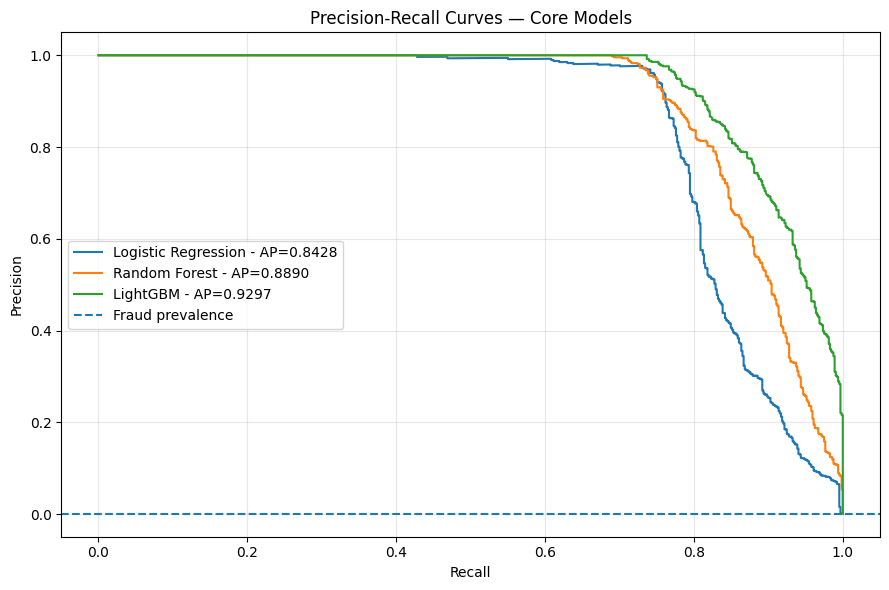

In [455]:
# Tracer les courbes Core
core_score_names = [
    "Logistic Regression | Core",
    "Random Forest | Core",
    "LightGBM | Core"
]

plt.figure(
    figsize=(9, 6)
)

for name in core_score_names:

    scores = validation_scores[name]

    precision, recall, _ = (
        precision_recall_curve(
            y_validation,
            scores
        )
    )

    ap = average_precision_score(
        y_validation,
        scores
    )

    plt.plot(
        recall,
        precision,
        label=(
            f"{name.split(' | ')[0]} "
            f"- AP={ap:.4f}"
        )
    )

plt.axhline(
    y=y_validation.mean(),
    linestyle="--",
    label="Fraud prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curves — Core Models"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [456]:
# Comparer les modèles Full
full_comparison_df = (
    validation_model_metrics_df[
        validation_model_metrics_df[
            "feature_set"
        ].isin(
            [
                "Linear Full",
                "Full"
            ]
        )
    ]
    .copy()
)

full_comparison_df[
    [
        "model",
        "feature_set",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "tp",
        "fp",
        "fn"
    ]
].sort_values(
    "average_precision",
    ascending=False
)

,model,feature_set,average_precision,roc_auc,precision,recall,f1,tp,fp,fn
4,LightGBM,Full,1.000000,1.0,1.0,0.998433,0.999216,637,0,1
2,Random Forest,Full,0.999998,1.0,1.0,0.998433,0.999216,637,0,1
5,Logistic Regression,Linear Full,0.999789,1.0,1.0,0.996865,0.998430,636,0,2


### 9.12 Precision-Recall Curves - Full Models

Les modèles Full obtiennent des performances presque parfaites. La courbe Precision-Recall est donc affichée avec une échelle verticale resserrée afin de rendre visibles les faibles différences entre les trois modèles.

Cette visualisation ne modifie aucune métrique et sert uniquement à faciliter la comparaison graphique.

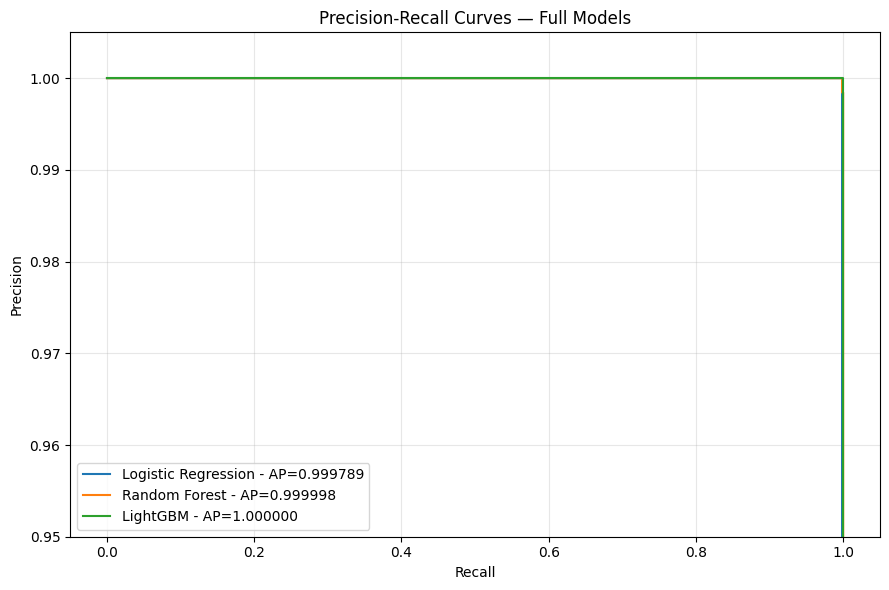

In [457]:
# Tracer les courbes Full
full_score_names = [
    "Logistic Regression | Full",
    "Random Forest | Full",
    "LightGBM | Full"
]

plt.figure(
    figsize=(9, 6)
)

for name in full_score_names:

    scores = validation_scores[name]

    precision, recall, _ = (
        precision_recall_curve(
            y_validation,
            scores
        )
    )

    ap = average_precision_score(
        y_validation,
        scores
    )

    plt.plot(
        recall,
        precision,
        label=(
            f"{name.split(' | ')[0]} "
            f"- AP={ap:.6f}"
        )
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curves — Full Models"
)

plt.ylim(
    0.95,
    1.005
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [458]:
# Résumer Core vs Full
core_full_summary = pd.DataFrame(
    [
        {
            "model": "Logistic Regression",
            "core_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "Logistic Regression | Core"
                ]
            ),
            "full_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "Logistic Regression | Full"
                ]
            )
        },
        {
            "model": "Random Forest",
            "core_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "Random Forest | Core"
                ]
            ),
            "full_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "Random Forest | Full"
                ]
            )
        },
        {
            "model": "LightGBM",
            "core_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "LightGBM | Core"
                ]
            ),
            "full_ap": average_precision_score(
                y_validation,
                validation_scores[
                    "LightGBM | Full"
                ]
            )
        }
    ]
)

core_full_summary[
    "absolute_gain"
] = (
    core_full_summary["full_ap"]
    - core_full_summary["core_ap"]
)

core_full_summary[
    "relative_gain_pct"
] = (
    100
    * (
        core_full_summary["full_ap"]
        / core_full_summary["core_ap"]
        - 1
    )
)

core_full_summary

,model,core_ap,full_ap,absolute_gain,relative_gain_pct
0,Logistic Regression,0.842838,0.999789,0.156952,18.621850
1,Random Forest,0.888957,0.999998,0.111041,12.491166
2,LightGBM,0.929704,1.000000,0.070296,7.561152


In [460]:
# Sélectionner le meilleur Core
best_core_row = (
    core_comparison_df
    .sort_values(
        "average_precision",
        ascending=False
    )
    .iloc[0]
)

print("Meilleur candidat Core")
print()

print(
    best_core_row[
        [
            "model",
            "feature_set",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1"
        ]
    ]
)

Meilleur candidat Core

model                LightGBM
feature_set              Core
average_precision    0.929704
roc_auc              0.999892
precision            0.977733
recall               0.757053
f1                   0.853357
Name: 3, dtype: object


In [462]:
# Sélectionner le meilleur Full
best_full_row = (
    full_comparison_df
    .sort_values(
        "average_precision",
        ascending=False
    )
    .iloc[0]
)

print("Meilleur candidat Full")
print()

print(
    best_full_row[
        [
            "model",
            "feature_set",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1"
        ]
    ]
)

Meilleur candidat Full

model                LightGBM
feature_set              Full
average_precision         1.0
roc_auc                   1.0
precision                 1.0
recall               0.998433
f1                   0.999216
Name: 4, dtype: object


In [463]:
# Résumer la sélection
section_9_summary = {
    "n_supervised_models": len(
        validation_model_metrics_df
    ),
    "n_validation_scores": len(
        validation_scores
    ),
    "best_core_model": best_core_row[
        "model"
    ],
    "best_core_ap": best_core_row[
        "average_precision"
    ],
    "best_full_model": best_full_row[
        "model"
    ],
    "best_full_ap": best_full_row[
        "average_precision"
    ]
}

for key, value in section_9_summary.items():
    print(
        f"{key} :",
        value
    )

n_supervised_models : 6
n_validation_scores : 6
best_core_model : LightGBM
best_core_ap : 0.9297036922443951
best_full_model : LightGBM
best_full_ap : 1.0


### 9.16 Validation Model Comparison - Interpretation

La comparaison finale sur la Validation confirme une hiérarchie claire entre les modèles Core.

LightGBM obtient la meilleure Average Precision avec **0,9297**, devant le Random Forest (**0,8890**) et la Logistic Regression (**0,8428**). Les courbes Precision-Recall confirment cette hiérarchie : LightGBM maintient globalement une meilleure précision lorsque le niveau de rappel augmente.

Au seuil provisoire de 0,5, les comportements diffèrent néanmoins entre les modèles. LightGBM Core obtient une précision de **97,77 %** et un rappel de **75,71 %**, tandis que le Random Forest privilégie davantage le rappel (**88,09 %**) mais génère beaucoup plus de faux positifs. Ces différences montrent que les métriques calculées à un seuil fixe ne suffisent pas pour sélectionner un modèle et justifient une optimisation séparée du seuil de décision.

LightGBM est donc retenu comme **meilleur candidat Core**, avec :

- **Average Precision : 0,9297**
- **ROC-AUC : 0,9999**
- **Precision à 0,5 : 97,77 %**
- **Recall à 0,5 : 75,71 %**
- **F1-score à 0,5 : 85,34 %**

Les configurations Full produisent un comportement radicalement différent. Les trois familles de modèles atteignent des performances presque parfaites :

- Logistic Regression Full : AP = **0,99979**
- Random Forest Full : AP ≈ **0,999998**
- LightGBM Full : AP = **1,00000**

Les courbes Precision-Recall Full sont pratiquement confondues avec le bord supérieur du graphique. Cette quasi-séparation parfaite apparaît donc indépendamment de la famille de modèles utilisée.

L'analyse Core vs Full confirme l'importance des variables PaySim-sensitive. Leur ajout augmente l'Average Precision de :

- **+0,1570** pour la Logistic Regression, soit environ **+18,62 %** ;
- **+0,1110** pour le Random Forest, soit environ **+12,49 %** ;
- **+0,0703** pour LightGBM, soit environ **+7,56 %**.

Le fait que cette amélioration soit observée avec trois familles de modèles différentes indique que le phénomène provient principalement de l'information contenue dans les variables supplémentaires plutôt que d'un algorithme particulier.

Ces résultats constituent un point méthodologique majeur du notebook. Les performances Full ne doivent pas être interprétées comme une estimation réaliste de la détection de fraude Mobile Money dans un environnement réel. Elles montrent surtout que certains mécanismes propres au simulateur PaySim rendent les transactions frauduleuses presque parfaitement séparables.

Pour la suite du protocole :

- **LightGBM Core** est retenu comme baseline tabulaire principale et prudente ;
- **LightGBM Full** est retenu comme référence complémentaire permettant de quantifier la sensibilité aux artefacts de PaySim.

Les deux modèles seront maintenant étudiés pour le choix du seuil de classification, exclusivement à partir de la Validation. Le Test reste totalement intact.

## 10. Threshold Optimization

Les modèles ont jusqu'à présent été comparés principalement à partir de métriques indépendantes du seuil, notamment l'Average Precision.

Pour une utilisation opérationnelle, il est cependant nécessaire de convertir les scores probabilistes en décisions binaires.

Le seuil standard de 0,5 n'est pas supposé optimal. Le choix du seuil est réalisé exclusivement sur la Validation et uniquement pour les deux modèles sélectionnés :

- LightGBM Core ;
- LightGBM Full.

Plusieurs compromis Precision/Recall sont étudiés. En l'absence d'une fonction de coût métier explicitement définie, aucun coût arbitraire n'est attribué aux faux positifs ou aux faux négatifs.

Le Test reste entièrement exclu du processus de sélection du seuil.

In [464]:
# Auditer la séparation des scores
def audit_score_separation(
    y_true,
    scores,
    model_name
):
    legitimate_scores = scores[
        y_true == 0
    ]

    fraud_scores = scores[
        y_true == 1
    ]

    max_legitimate = legitimate_scores.max()
    min_fraud = fraud_scores.min()

    separation_gap = (
        min_fraud
        - max_legitimate
    )

    return {
        "model": model_name,
        "max_legitimate_score": max_legitimate,
        "min_fraud_score": min_fraud,
        "separation_gap": separation_gap,
        "perfect_separation": (
            separation_gap > 0
        )
    }

In [465]:
# Auditer Core et Full
score_separation_df = pd.DataFrame(
    [
        audit_score_separation(
            y_true=y_validation,
            scores=validation_scores[
                "LightGBM | Core"
            ],
            model_name="LightGBM Core"
        ),
        audit_score_separation(
            y_true=y_validation,
            scores=validation_scores[
                "LightGBM | Full"
            ],
            model_name="LightGBM Full"
        )
    ]
)

score_separation_df

,model,max_legitimate_score,min_fraud_score,separation_gap,perfect_separation
0,LightGBM Core,0.667962,0.008835,-0.659127,False
1,LightGBM Full,0.000312,0.000315,0.000004,True


In [466]:
# Trouver les seuils candidats
def find_threshold_candidates(
    y_true,
    scores
):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            scores
        )
    )

    precision_t = precision[:-1]
    recall_t = recall[:-1]

    f1_t = np.divide(
        2 * precision_t * recall_t,
        precision_t + recall_t,
        out=np.zeros_like(
            precision_t
        ),
        where=(
            precision_t + recall_t
        ) > 0
    )

    candidates = {}

    # Maximum F1
    best_f1_idx = np.argmax(
        f1_t
    )

    candidates[
        "Max F1"
    ] = thresholds[
        best_f1_idx
    ]

    # Precision minimale 95 %
    valid = np.where(
        precision_t >= 0.95
    )[0]

    if len(valid) > 0:
        best_idx = valid[
            np.argmax(
                recall_t[valid]
            )
        ]

        candidates[
            "Precision >= 95%"
        ] = thresholds[
            best_idx
        ]

    # Precision minimale 99 %
    valid = np.where(
        precision_t >= 0.99
    )[0]

    if len(valid) > 0:
        best_idx = valid[
            np.argmax(
                recall_t[valid]
            )
        ]

        candidates[
            "Precision >= 99%"
        ] = thresholds[
            best_idx
        ]

    # Recall minimal 90 %
    valid = np.where(
        recall_t >= 0.90
    )[0]

    if len(valid) > 0:
        best_idx = valid[
            np.argmax(
                precision_t[valid]
            )
        ]

        candidates[
            "Recall >= 90%"
        ] = thresholds[
            best_idx
        ]

    return candidates

In [467]:
# Évaluer plusieurs seuils
def evaluate_threshold_candidates(
    y_true,
    scores,
    model_name,
    feature_set,
    candidates
):
    rows = []

    default_metrics = (
        evaluate_binary_classifier(
            y_true=y_true,
            y_score=scores,
            model_name=model_name,
            feature_set=feature_set,
            threshold=0.5
        )
    )

    default_metrics[
        "threshold_strategy"
    ] = "Default 0.5"

    rows.append(
        default_metrics
    )

    for strategy, threshold in (
        candidates.items()
    ):

        metrics = (
            evaluate_binary_classifier(
                y_true=y_true,
                y_score=scores,
                model_name=model_name,
                feature_set=feature_set,
                threshold=float(
                    threshold
                )
            )
        )

        metrics[
            "threshold_strategy"
        ] = strategy

        rows.append(
            metrics
        )

    return pd.DataFrame(
        rows
    )

In [468]:
# Chercher les seuils Core
lgb_core_threshold_candidates = (
    find_threshold_candidates(
        y_true=y_validation,
        scores=validation_scores[
            "LightGBM | Core"
        ]
    )
)

print(
    lgb_core_threshold_candidates
)

{'Max F1': np.float64(0.31370041201761084), 'Precision >= 95%': np.float64(0.392587145341068), 'Precision >= 99%': np.float64(0.6159108080914172), 'Recall >= 90%': np.float64(0.11664615293690578)}


In [469]:
# Évaluer les seuils Core
lgb_core_threshold_df = (
    evaluate_threshold_candidates(
        y_true=y_validation,
        scores=validation_scores[
            "LightGBM | Core"
        ],
        model_name="LightGBM",
        feature_set="Core",
        candidates=(
            lgb_core_threshold_candidates
        )
    )
)

threshold_display_columns = [
    "threshold_strategy",
    "threshold",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "tp",
    "fp",
    "fn",
    "tn"
]

lgb_core_threshold_df[
    threshold_display_columns
]

,threshold_strategy,threshold,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
0,Default 0.5,0.500000,0.977733,0.757053,0.853357,0.878520,483,11,155,791757
1,Max F1,0.313700,0.925725,0.800940,0.858824,0.900444,511,41,127,791727
2,Precision >= 95%,0.392587,0.950192,0.777429,0.855172,0.888698,496,26,142,791742
3,Precision >= 99%,0.615911,0.991597,0.739812,0.847397,0.869903,472,4,166,791764
4,Recall >= 90%,0.116646,0.692771,0.901254,0.783379,0.950466,575,255,63,791513


In [470]:
# Chercher les seuils Full
lgb_full_threshold_candidates = (
    find_threshold_candidates(
        y_true=y_validation,
        scores=validation_scores[
            "LightGBM | Full"
        ]
    )
)

print(
    lgb_full_threshold_candidates
)

{'Max F1': np.float64(0.00031535523910048), 'Precision >= 95%': np.float64(0.0001623432499232572), 'Precision >= 99%': np.float64(0.00021929117810287914), 'Recall >= 90%': np.float64(0.00031535523910048)}


In [471]:
# Évaluer les seuils Full
lgb_full_threshold_df = (
    evaluate_threshold_candidates(
        y_true=y_validation,
        scores=validation_scores[
            "LightGBM | Full"
        ],
        model_name="LightGBM",
        feature_set="Full",
        candidates=(
            lgb_full_threshold_candidates
        )
    )
)

lgb_full_threshold_df[
    threshold_display_columns
]

,threshold_strategy,threshold,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
0,Default 0.5,0.500000,1.000000,0.998433,0.999216,0.999216,637,0,1,791768
1,Max F1,0.000315,1.000000,1.000000,1.000000,1.000000,638,0,0,791768
2,Precision >= 95%,0.000162,0.966667,1.000000,0.983051,0.999986,638,22,0,791746
3,Precision >= 99%,0.000219,0.996875,1.000000,0.998435,0.999999,638,2,0,791766
4,Recall >= 90%,0.000315,1.000000,1.000000,1.000000,1.000000,638,0,0,791768


In [472]:
# Chercher un seuil de séparation Full
full_separation_row = (
    score_separation_df[
        score_separation_df[
            "model"
        ] == "LightGBM Full"
    ]
    .iloc[0]
)

if full_separation_row[
    "perfect_separation"
]:
    lgb_full_separation_threshold = (
        (
            full_separation_row[
                "max_legitimate_score"
            ]
            + full_separation_row[
                "min_fraud_score"
            ]
        )
        / 2
    )

    print(
        "Seuil de séparation :",
        lgb_full_separation_threshold
    )

else:
    lgb_full_separation_threshold = None

    print(
        "Pas de séparation parfaite."
    )

Seuil de séparation : 0.0003134442718939925


In [474]:
# Évaluer le seuil de séparation
if (
    lgb_full_separation_threshold
    is not None
):
    lgb_full_separation_metrics = (
        evaluate_binary_classifier(
            y_true=y_validation,
            y_score=validation_scores[
                "LightGBM | Full"
            ],
            model_name="LightGBM",
            feature_set="Full",
            threshold=(
                lgb_full_separation_threshold
            )
        )
    )

    pd.DataFrame(
        [
            lgb_full_separation_metrics
        ]
    )[
        display_columns
    ]

C:\Users\bouza\AppData\Local\Temp\ipykernel_28620\2964233811.py:41: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bouza\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


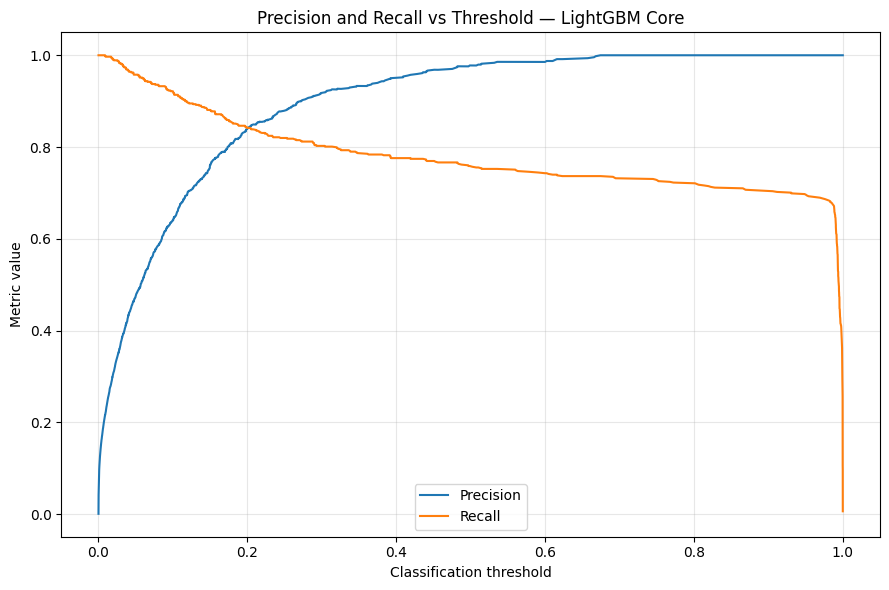

In [475]:
# Calculer la courbe de seuil Core
core_precision, core_recall, core_thresholds = (
    precision_recall_curve(
        y_validation,
        validation_scores[
            "LightGBM | Core"
        ]
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    core_thresholds,
    core_precision[:-1],
    label="Precision"
)

plt.plot(
    core_thresholds,
    core_recall[:-1],
    label="Recall"
)

plt.xlabel(
    "Classification threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Precision and Recall vs Threshold — LightGBM Core"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10.9 Threshold Optimization - Results

Le seuil standard de 0,5 n'est pas optimal pour les deux modèles LightGBM sélectionnés.

#### LightGBM Core

Pour LightGBM Core, le seuil de 0,5 obtient une précision élevée de 97,77 %, mais un rappel limité à 75,71 %. Sur les 638 fraudes présentes dans la Validation, 155 restent alors non détectées.

L'analyse Precision/Recall montre qu'une diminution du seuil permet d'améliorer le rappel au prix d'une augmentation contrôlée des faux positifs.

Le seuil maximisant le F1-score sur la Validation est :

**threshold = 0,3137**

À ce seuil, le modèle obtient :

- **Precision : 92,57 %**
- **Recall : 80,09 %**
- **F1-score : 85,88 %**
- **TP : 511**
- **FP : 41**
- **FN : 127**

Par rapport au seuil standard de 0,5, 28 fraudes supplémentaires sont détectées, au prix de 30 faux positifs supplémentaires.

En l'absence d'une fonction de coût métier permettant de quantifier précisément le coût relatif d'un faux positif et d'un faux négatif, le seuil maximisant le F1-score est retenu comme compromis principal entre Precision et Recall.

Un point de fonctionnement alternatif avec une précision minimale d'environ 95 % est également identifié autour de 0,393. Il pourra être discuté dans une perspective opérationnelle si la réduction des faux positifs devient prioritaire.

#### LightGBM Full

La configuration Full présente une situation radicalement différente.

Sur la Validation, le score maximal observé parmi les transactions légitimes est inférieur au score minimal observé parmi les fraudes. Les deux classes sont donc parfaitement séparables par un seuil unique.

Le seuil placé au milieu de cet intervalle est :

**threshold ≈ 0,00031344**

Il permet d'obtenir sur la Validation :

- **Precision : 100 %**
- **Recall : 100 %**
- **F1-score : 100 %**
- **638 vrais positifs**
- **0 faux positif**
- **0 faux négatif**

Cette séparation parfaite doit toutefois être interprétée avec une grande prudence. Le seuil est plusieurs ordres de grandeur inférieur à 0,5 et résulte de la structure des scores produite sur PaySim avec les variables Full.

Il ne constitue donc pas une règle universelle de décision pour la fraude Mobile Money. Ce résultat renforce au contraire l'hypothèse selon laquelle les variables PaySim-sensitive rendent les transactions frauduleuses artificiellement faciles à séparer.

Les seuils retenus pour l'évaluation finale sont donc :

- **LightGBM Core : 0,313700**
- **LightGBM Full : 0,00031344**

Ces seuils sont désormais figés. Aucun ajustement supplémentaire ne sera effectué à partir du Test.

In [476]:
# Verrouiller les seuils
FINAL_CORE_THRESHOLD = 0.31370041201761084

FINAL_FULL_THRESHOLD = (
    lgb_full_separation_threshold
)

final_thresholds = {
    "LightGBM Core": FINAL_CORE_THRESHOLD,
    "LightGBM Full": FINAL_FULL_THRESHOLD
}

for model_name, threshold in final_thresholds.items():
    print(
        f"{model_name} :",
        f"{threshold:.12f}"
    )

LightGBM Core : 0.313700412018
LightGBM Full : 0.000313444272


In [477]:
# Résumer les décisions Validation
model_selection = {
    "primary_metric": "average_precision",
    "best_core_model": "LightGBM",
    "best_core_feature_set": "Core",
    "best_core_iteration": int(
        lgb_core_model.best_iteration_
    ),
    "best_core_threshold": float(
        FINAL_CORE_THRESHOLD
    ),
    "best_core_threshold_strategy": "Max F1",
    "best_full_model": "LightGBM",
    "best_full_feature_set": "Full",
    "best_full_iteration": int(
        lgb_full_model.best_iteration_
    ),
    "best_full_threshold": float(
        FINAL_FULL_THRESHOLD
    ),
    "best_full_threshold_strategy": (
        "Validation separation midpoint"
    )
}

for key, value in model_selection.items():
    print(
        f"{key} :",
        value
    )

primary_metric : average_precision
best_core_model : LightGBM
best_core_feature_set : Core
best_core_iteration : 209
best_core_threshold : 0.31370041201761084
best_core_threshold_strategy : Max F1
best_full_model : LightGBM
best_full_feature_set : Full
best_full_iteration : 65
best_full_threshold : 0.0003134442718939925
best_full_threshold_strategy : Validation separation midpoint


In [478]:
# Vérifier les décisions finales
final_protocol_check = pd.DataFrame(
    [
        {
            "model": "LightGBM",
            "feature_set": "Core",
            "best_iteration": (
                lgb_core_model.best_iteration_
            ),
            "threshold": (
                FINAL_CORE_THRESHOLD
            ),
            "selection_source": "Validation"
        },
        {
            "model": "LightGBM",
            "feature_set": "Full",
            "best_iteration": (
                lgb_full_model.best_iteration_
            ),
            "threshold": (
                FINAL_FULL_THRESHOLD
            ),
            "selection_source": "Validation"
        }
    ]
)

final_protocol_check

,model,feature_set,best_iteration,threshold,selection_source
0,LightGBM,Core,209,0.313700,Validation
1,LightGBM,Full,65,0.000313,Validation


## 11. Final Test Evaluation

Les décisions de modélisation sont désormais entièrement figées à partir du Train et de la Validation.

Les deux modèles sélectionnés sont :

- **LightGBM Core**, représentant la baseline tabulaire principale et prudente ;
- **LightGBM Full**, utilisé comme expérience complémentaire de sensibilité aux variables spécifiques à PaySim.

Le nombre d'itérations et le seuil de classification de chaque modèle ont été déterminés avant toute évaluation finale :

- LightGBM Core : `best_iteration = 209`, `threshold = 0.313700`
- LightGBM Full : `best_iteration = 65`, `threshold = 0.00031344`

Les modèles ne sont pas réentraînés après la sélection des seuils afin de conserver exactement les fonctions de score utilisées lors de la Validation.

Le Test correspond à une période temporelle future présentant un changement important de prévalence de la fraude. Il est utilisé ici pour la première et unique évaluation finale.

Aucune information issue du Test ne sera utilisée pour modifier les modèles, les variables, les hyperparamètres ou les seuils.

In [479]:
# Vérifier le protocole final
assert lgb_core_model.best_iteration_ == 209
assert lgb_full_model.best_iteration_ == 65

assert np.isclose(
    FINAL_CORE_THRESHOLD,
    0.31370041201761084
)

assert np.isclose(
    FINAL_FULL_THRESHOLD,
    0.0003134442718939925
)

print(
    "LightGBM Core iteration :",
    lgb_core_model.best_iteration_
)

print(
    "LightGBM Core threshold :",
    FINAL_CORE_THRESHOLD
)

print(
    "LightGBM Full iteration :",
    lgb_full_model.best_iteration_
)

print(
    "LightGBM Full threshold :",
    FINAL_FULL_THRESHOLD
)

print("\nProtocole final verrouillé.")

LightGBM Core iteration : 209
LightGBM Core threshold : 0.31370041201761084
LightGBM Full iteration : 65
LightGBM Full threshold : 0.0003134442718939925

Protocole final verrouillé.


In [480]:
# Préparer la cible Test
y_test = df.loc[
    test_mask,
    TARGET
].copy()

print(
    "Transactions Test :",
    len(y_test)
)

print(
    "Fraudes Test :",
    int(y_test.sum())
)

print(
    "Taux fraude Test :",
    f"{100 * y_test.mean():.6f}%"
)

print(
    "Steps Test :",
    df.loc[test_mask, "step"].min(),
    "à",
    df.loc[test_mask, "step"].max()
)

Transactions Test : 798827
Fraudes Test : 3830
Taux fraude Test : 0.479453%
Steps Test : 393 à 743


In [481]:
# Comparer les prévalences temporelles
prevalence_comparison = pd.DataFrame(
    [
        {
            "split": "Train",
            "transactions": len(y_train),
            "frauds": int(y_train.sum()),
            "fraud_rate": y_train.mean()
        },
        {
            "split": "Validation",
            "transactions": len(y_validation),
            "frauds": int(y_validation.sum()),
            "fraud_rate": y_validation.mean()
        },
        {
            "split": "Test",
            "transactions": len(y_test),
            "frauds": int(y_test.sum()),
            "fraud_rate": y_test.mean()
        }
    ]
)

prevalence_comparison[
    "fraud_rate_pct"
] = (
    100
    * prevalence_comparison[
        "fraud_rate"
    ]
)

prevalence_comparison

,split,transactions,frauds,fraud_rate,fraud_rate_pct
0,Train,4771387,3745,0.000785,0.078489
1,Validation,792406,638,0.000805,0.080514
2,Test,798827,3830,0.004795,0.479453


In [482]:
# Mesurer le changement Validation vers Test
test_validation_prevalence_ratio = (
    y_test.mean()
    / y_validation.mean()
)

print(
    "Ratio prévalence Test / Validation :",
    f"{test_validation_prevalence_ratio:.2f}x"
)

Ratio prévalence Test / Validation : 5.95x


In [483]:
# Vérifier la mémoire
gc.collect()

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

RAM disponible : 2.08 GB


In [484]:
# Préparer le Test Core
X_test_lgb_core = df.loc[
    test_mask,
    core_ml_features
].copy()

print(
    "Dimensions :",
    X_test_lgb_core.shape
)

print(
    "Mémoire :",
    f"{X_test_lgb_core.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (798827, 22)
Mémoire : 67.80 MB


In [485]:
# Prédire LightGBM Core
start = perf_counter()

lgb_core_test_scores = (
    lgb_core_model.predict_proba(
        X_test_lgb_core,
        num_iteration=lgb_core_model.best_iteration_
    )[:, 1]
)

lgb_core_test_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{lgb_core_test_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_core_test_scores.min()
)

print(
    "Score maximum :",
    lgb_core_test_scores.max()
)

print(
    "Score moyen :",
    lgb_core_test_scores.mean()
)

print(
    "Score médian :",
    np.median(
        lgb_core_test_scores
    )
)

Temps de prédiction : 11.30 s
Score minimum : 5.22321263562553e-15
Score maximum : 0.9999994789843215
Score moyen : 0.003926043045287566
Score médian : 6.221955308655669e-07


In [486]:
# Libérer le Test Core
del X_test_lgb_core

gc.collect()

4

In [487]:
# Évaluer LightGBM Core
lgb_core_test_metrics = (
    evaluate_binary_classifier(
        y_true=y_test,
        y_score=lgb_core_test_scores,
        model_name="LightGBM",
        feature_set="Core",
        threshold=FINAL_CORE_THRESHOLD
    )
)

lgb_core_test_metrics[
    "predict_time_seconds"
] = (
    lgb_core_test_predict_time
)

pd.DataFrame(
    [lgb_core_test_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,LightGBM,Core,0.3137,0.979749,0.99989,0.982229,0.793734,0.877978,0.896832,0.998942,3040,55,790,794942


In [488]:
# Construire la matrice de confusion Core
lgb_core_test_confusion = pd.DataFrame(
    [
        [
            lgb_core_test_metrics["tn"],
            lgb_core_test_metrics["fp"]
        ],
        [
            lgb_core_test_metrics["fn"],
            lgb_core_test_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

lgb_core_test_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,794942,55
Actual Fraud,790,3040


In [489]:
# Préparer le Test Full
X_test_lgb_full = df.loc[
    test_mask,
    full_ml_features
].copy()

print(
    "Dimensions :",
    X_test_lgb_full.shape
)

print(
    "Mémoire :",
    f"{X_test_lgb_full.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions : (798827, 31)
Mémoire : 86.85 MB


In [490]:
# Prédire LightGBM Full
start = perf_counter()

lgb_full_test_scores = (
    lgb_full_model.predict_proba(
        X_test_lgb_full,
        num_iteration=lgb_full_model.best_iteration_
    )[:, 1]
)

lgb_full_test_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{lgb_full_test_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_full_test_scores.min()
)

print(
    "Score maximum :",
    lgb_full_test_scores.max()
)

print(
    "Score moyen :",
    lgb_full_test_scores.mean()
)

print(
    "Score médian :",
    np.median(
        lgb_full_test_scores
    )
)

Temps de prédiction : 2.06 s
Score minimum : 3.236883005931655e-05
Score maximum : 1.0
Score moyen : 0.004798811671833744
Score médian : 3.236883005931655e-05


In [491]:
# Prédire LightGBM Full
start = perf_counter()

lgb_full_test_scores = (
    lgb_full_model.predict_proba(
        X_test_lgb_full,
        num_iteration=lgb_full_model.best_iteration_
    )[:, 1]
)

lgb_full_test_predict_time = (
    perf_counter() - start
)

print(
    "Temps de prédiction :",
    f"{lgb_full_test_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_full_test_scores.min()
)

print(
    "Score maximum :",
    lgb_full_test_scores.max()
)

print(
    "Score moyen :",
    lgb_full_test_scores.mean()
)

print(
    "Score médian :",
    np.median(
        lgb_full_test_scores
    )
)

Temps de prédiction : 2.65 s
Score minimum : 3.236883005931655e-05
Score maximum : 1.0
Score moyen : 0.004798811671833744
Score médian : 3.236883005931655e-05


In [492]:
# Libérer le Test Full
del X_test_lgb_full

gc.collect()

188

In [493]:
# Évaluer LightGBM Full
lgb_full_test_metrics = (
    evaluate_binary_classifier(
        y_true=y_test,
        y_score=lgb_full_test_scores,
        model_name="LightGBM",
        feature_set="Full",
        threshold=FINAL_FULL_THRESHOLD
    )
)

lgb_full_test_metrics[
    "predict_time_seconds"
] = (
    lgb_full_test_predict_time
)

pd.DataFrame(
    [lgb_full_test_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,LightGBM,Full,0.000313,0.99974,0.999895,0.999738,0.997389,0.998562,0.998694,0.999986,3820,1,10,794996


In [494]:
# Construire la matrice de confusion Full
lgb_full_test_confusion = pd.DataFrame(
    [
        [
            lgb_full_test_metrics["tn"],
            lgb_full_test_metrics["fp"]
        ],
        [
            lgb_full_test_metrics["fn"],
            lgb_full_test_metrics["tp"]
        ]
    ],
    index=[
        "Actual Legitimate",
        "Actual Fraud"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Fraud"
    ]
)

lgb_full_test_confusion

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,794996,1
Actual Fraud,10,3820


In [495]:
# Comparer Core et Full sur Test
final_test_comparison = pd.DataFrame(
    [
        lgb_core_test_metrics,
        lgb_full_test_metrics
    ]
)

final_test_comparison[
    [
        "model",
        "feature_set",
        "threshold",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "tp",
        "fp",
        "fn",
        "tn"
    ]
]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
0,LightGBM,Core,0.313700,0.979749,0.999890,0.982229,0.793734,0.877978,0.896832,3040,55,790,794942
1,LightGBM,Full,0.000313,0.999740,0.999895,0.999738,0.997389,0.998562,0.998694,3820,1,10,794996


In [496]:
# Comparer Validation et Test
validation_test_comparison = pd.DataFrame(
    [
        {
            "model": "LightGBM Core",
            "split": "Validation",
            "fraud_rate": y_validation.mean(),
            "average_precision": (
                lgb_core_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_core_metrics[
                    "roc_auc"
                ]
            )
        },
        {
            "model": "LightGBM Core",
            "split": "Test",
            "fraud_rate": y_test.mean(),
            "average_precision": (
                lgb_core_test_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_core_test_metrics[
                    "roc_auc"
                ]
            )
        },
        {
            "model": "LightGBM Full",
            "split": "Validation",
            "fraud_rate": y_validation.mean(),
            "average_precision": (
                lgb_full_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_full_metrics[
                    "roc_auc"
                ]
            )
        },
        {
            "model": "LightGBM Full",
            "split": "Test",
            "fraud_rate": y_test.mean(),
            "average_precision": (
                lgb_full_test_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_full_test_metrics[
                    "roc_auc"
                ]
            )
        }
    ]
)

validation_test_comparison[
    "fraud_rate_pct"
] = (
    100
    * validation_test_comparison[
        "fraud_rate"
    ]
)

validation_test_comparison

,model,split,fraud_rate,average_precision,roc_auc,fraud_rate_pct
0,LightGBM Core,Validation,0.000805,0.929704,0.999892,0.080514
1,LightGBM Core,Test,0.004795,0.979749,0.999890,0.479453
2,LightGBM Full,Validation,0.000805,1.000000,1.000000,0.080514
3,LightGBM Full,Test,0.004795,0.999740,0.999895,0.479453


In [497]:
# Calculer le lift par rapport à la prévalence
validation_test_comparison[
    "ap_lift_over_prevalence"
] = (
    validation_test_comparison[
        "average_precision"
    ]
    / validation_test_comparison[
        "fraud_rate"
    ]
)

validation_test_comparison[
    [
        "model",
        "split",
        "fraud_rate_pct",
        "average_precision",
        "ap_lift_over_prevalence",
        "roc_auc"
    ]
]

,model,split,fraud_rate_pct,average_precision,ap_lift_over_prevalence,roc_auc
0,LightGBM Core,Validation,0.080514,0.929704,1154.706558,0.999892
1,LightGBM Core,Test,0.479453,0.979749,204.347257,0.999890
2,LightGBM Full,Validation,0.080514,1.000000,1242.015674,1.000000
3,LightGBM Full,Test,0.479453,0.999740,208.516834,0.999895


In [498]:
# Mesurer le drift des métriques
performance_drift = pd.DataFrame(
    [
        {
            "model": "LightGBM Core",
            "validation_ap": (
                lgb_core_metrics[
                    "average_precision"
                ]
            ),
            "test_ap": (
                lgb_core_test_metrics[
                    "average_precision"
                ]
            ),
            "ap_change": (
                lgb_core_test_metrics[
                    "average_precision"
                ]
                - lgb_core_metrics[
                    "average_precision"
                ]
            ),
            "validation_roc_auc": (
                lgb_core_metrics[
                    "roc_auc"
                ]
            ),
            "test_roc_auc": (
                lgb_core_test_metrics[
                    "roc_auc"
                ]
            )
        },
        {
            "model": "LightGBM Full",
            "validation_ap": (
                lgb_full_metrics[
                    "average_precision"
                ]
            ),
            "test_ap": (
                lgb_full_test_metrics[
                    "average_precision"
                ]
            ),
            "ap_change": (
                lgb_full_test_metrics[
                    "average_precision"
                ]
                - lgb_full_metrics[
                    "average_precision"
                ]
            ),
            "validation_roc_auc": (
                lgb_full_metrics[
                    "roc_auc"
                ]
            ),
            "test_roc_auc": (
                lgb_full_test_metrics[
                    "roc_auc"
                ]
            )
        }
    ]
)

performance_drift[
    "roc_auc_change"
] = (
    performance_drift[
        "test_roc_auc"
    ]
    - performance_drift[
        "validation_roc_auc"
    ]
)

performance_drift

,model,validation_ap,test_ap,ap_change,validation_roc_auc,test_roc_auc,roc_auc_change
0,LightGBM Core,0.929704,0.979749,0.050045,0.999892,0.999890,-0.000002
1,LightGBM Full,1.000000,0.999740,-0.000260,1.000000,0.999895,-0.000105


### 11.12 Final Test Evaluation - Interpretation

L'évaluation finale est réalisée sur les steps 393 à 743, sans aucune modification des modèles, des hyperparamètres ou des seuils déterminés précédemment sur la Validation.

Le Test présente un changement important de distribution. Le taux de fraude passe de **0,0805 % sur la Validation à 0,4795 % sur le Test**, soit une prévalence environ **5,95 fois supérieure**.

#### LightGBM Core

Avec le seuil figé à **0,313700**, LightGBM Core obtient sur le Test :

- **Average Precision : 0,9797**
- **ROC-AUC : 0,99989**
- **Precision : 98,22 %**
- **Recall : 79,37 %**
- **F1-score : 87,80 %**
- **TP : 3 040**
- **FP : 55**
- **FN : 790**
- **TN : 794 942**

L'Average Precision est supérieure à celle observée sur la Validation. Cette augmentation doit cependant être interprétée avec prudence, car l'Average Precision dépend de la prévalence de la classe positive, nettement plus élevée sur le Test.

Le ROC-AUC fournit ici un signal plus directement comparable entre les périodes. Il reste pratiquement inchangé, passant de **0,999892 sur la Validation à 0,999890 sur le Test**.

Le seuil sélectionné sur la Validation présente également une bonne stabilité. Le Recall passe d'environ 80,09 % à 79,37 %, tandis que la Precision augmente sur le Test.

Ces résultats indiquent que LightGBM Core conserve un pouvoir de classement élevé et un comportement décisionnel relativement stable malgré le drift temporel observé.

#### LightGBM Full

Avec le seuil figé à environ **0,00031344**, LightGBM Full obtient :

- **Average Precision : 0,99974**
- **ROC-AUC : 0,999895**
- **Precision : 99,97 %**
- **Recall : 99,74 %**
- **F1-score : 99,86 %**
- **TP : 3 820**
- **FP : 1**
- **FN : 10**
- **TN : 794 996**

La séparation parfaite obtenue sur la Validation ne se reproduit donc pas strictement sur le Test. Néanmoins, les performances restent presque parfaites sur cette période future.

Ce comportement confirme que les variables PaySim-sensitive restent extrêmement discriminantes au-delà de la fenêtre temporelle utilisée pour leur validation. Leur efficacité ne semble donc pas être limitée à une seule période du dataset.

Cette stabilité ne doit toutefois pas être assimilée à une preuve de généralisation vers des données Mobile Money réelles. Elle indique plutôt que certains mécanismes caractéristiques du simulateur PaySim persistent au cours du temps et peuvent être fortement exploités par les modèles.

#### Conclusion de l'évaluation finale

LightGBM Core reste la **baseline tabulaire principale** du projet. Il offre des performances élevées sur une période future tout en excluant les variables considérées comme les plus sensibles aux artefacts du simulateur.

LightGBM Full constitue une **borne supérieure spécifique à PaySim**. Ses performances quasi parfaites permettent de quantifier l'effet considérable des variables PaySim-sensitive, mais ne doivent pas être présentées comme une estimation réaliste de la performance attendue en production.

Ces deux références fourniront ensuite un cadre de comparaison pour évaluer la valeur ajoutée des futurs modèles Graph Learning et GNN.

## 12. Feature Importance and Model Interpretation

Les modèles LightGBM Core et Full ont été retenus comme principales références tabulaires.

Cette section analyse les variables utilisées par ces modèles afin de mieux comprendre les sources de leur pouvoir prédictif.

L'objectif principal est double :

- identifier les variables les plus importantes dans la configuration Core ;
- déterminer dans quelle mesure la performance presque parfaite du modèle Full repose sur les variables PaySim-sensitive.

L'importance des variables est mesurée dans un premier temps à partir du **gain cumulé** produit par LightGBM.

Cette mesure représente l'amélioration de la fonction objectif apportée par les divisions utilisant une variable. Elle constitue une mesure d'importance prédictive et ne doit pas être interprétée comme une relation causale avec la fraude.

In [533]:
# Extraire les importances LightGBM
def get_lgb_feature_importance(
    model,
    features
):
    booster = model.booster_

    importance_df = pd.DataFrame({
        "feature": features,
        "gain": booster.feature_importance(
            importance_type="gain"
        ),
        "split": booster.feature_importance(
            importance_type="split"
        )
    })

    total_gain = importance_df[
        "gain"
    ].sum()

    importance_df[
        "gain_pct"
    ] = np.where(
        total_gain > 0,
        100 * importance_df["gain"] / total_gain,
        0
    )

    return (
        importance_df
        .sort_values(
            "gain",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [534]:
# Extraire les importances Core
lgb_core_importance_df = (
    get_lgb_feature_importance(
        model=lgb_core_model,
        features=core_ml_features
    )
)

lgb_core_importance_df[
    [
        "feature",
        "gain",
        "gain_pct",
        "split"
    ]
].head(15)

,feature,gain,gain_pct,split
0,newbalanceDest,592960.735757,57.188486,355
1,oldbalanceDest,157647.265908,15.204394,223
2,log_amount,53954.498474,5.203677,343
3,oldbalanceOrg,49650.023456,4.788529,968
4,amount,44318.397500,4.274317,1161
5,origin_balance_change,43905.882843,4.234532,549
6,type,21883.723546,2.110590,82
7,newbalanceOrig,21310.878199,2.055342,157
8,destination_balance_change,20882.325896,2.014010,423
9,amount_to_dest_balance_ratio,9043.364576,0.872193,471


In [535]:
# Calculer la concentration des gains Core
core_top5_gain_pct = (
    lgb_core_importance_df[
        "gain_pct"
    ]
    .head(5)
    .sum()
)

core_top10_gain_pct = (
    lgb_core_importance_df[
        "gain_pct"
    ]
    .head(10)
    .sum()
)

print(
    "Gain porté par le Top 5 :",
    f"{core_top5_gain_pct:.2f}%"
)

print(
    "Gain porté par le Top 10 :",
    f"{core_top10_gain_pct:.2f}%"
)

Gain porté par le Top 5 : 86.66%
Gain porté par le Top 10 : 97.95%


In [536]:
# Extraire les importances Full
lgb_full_importance_df = (
    get_lgb_feature_importance(
        model=lgb_full_model,
        features=full_ml_features
    )
)

lgb_full_importance_df[
    [
        "feature",
        "gain",
        "gain_pct",
        "split"
    ]
].head(15)

,feature,gain,gain_pct,split
0,amount_equals_oldbalance,2.620960e+06,99.664146,1
1,destination_balance_residual,2.670551e+03,0.101550,114
2,oldbalanceOrg,2.239936e+03,0.085175,84
3,origin_balance_change,1.605830e+03,0.061063,59
4,amount_to_dest_balance_ratio,5.910510e+02,0.022475,145
5,amount,2.330375e+02,0.008861,98
6,amount_to_oldbalance_ratio,2.218669e+02,0.008437,51
7,log_amount,1.924573e+02,0.007318,57
8,destination_balance_change,1.538691e+02,0.005851,83
9,origin_balance_residual,1.231078e+02,0.004681,57


In [537]:
# Marquer les variables PaySim-sensitive
model_paysim_sensitive = set(
    metadata[
        "feature_sets"
    ][
        "model_paysim_sensitive"
    ]
)

lgb_full_importance_df[
    "paysim_sensitive"
] = (
    lgb_full_importance_df[
        "feature"
    ]
    .isin(
        model_paysim_sensitive
    )
)

lgb_full_importance_df[
    [
        "feature",
        "gain_pct",
        "split",
        "paysim_sensitive"
    ]
].head(15)

,feature,gain_pct,split,paysim_sensitive
0,amount_equals_oldbalance,99.664146,1,True
1,destination_balance_residual,0.101550,114,True
2,oldbalanceOrg,0.085175,84,False
3,origin_balance_change,0.061063,59,False
4,amount_to_dest_balance_ratio,0.022475,145,False
5,amount,0.008861,98,False
6,amount_to_oldbalance_ratio,0.008437,51,True
7,log_amount,0.007318,57,False
8,destination_balance_change,0.005851,83,False
9,origin_balance_residual,0.004681,57,True


In [538]:
# Mesurer la dépendance aux features sensibles
sensitive_gain_pct = (
    lgb_full_importance_df.loc[
        lgb_full_importance_df[
            "paysim_sensitive"
        ],
        "gain_pct"
    ]
    .sum()
)

core_gain_pct_in_full = (
    lgb_full_importance_df.loc[
        ~lgb_full_importance_df[
            "paysim_sensitive"
        ],
        "gain_pct"
    ]
    .sum()
)

print(
    "Gain PaySim-sensitive :",
    f"{sensitive_gain_pct:.2f}%"
)

print(
    "Gain variables Core :",
    f"{core_gain_pct_in_full:.2f}%"
)

Gain PaySim-sensitive : 99.79%
Gain variables Core : 0.21%


In [539]:
# Afficher les variables sensibles
sensitive_importance_df = (
    lgb_full_importance_df[
        lgb_full_importance_df[
            "paysim_sensitive"
        ]
    ][
        [
            "feature",
            "gain",
            "gain_pct",
            "split"
        ]
    ]
    .copy()
)

sensitive_importance_df

,feature,gain,gain_pct,split
0,amount_equals_oldbalance,2.620960e+06,99.664146,1
1,destination_balance_residual,2.670551e+03,0.101550,114
6,amount_to_oldbalance_ratio,2.218669e+02,0.008437,51
9,origin_balance_residual,1.231078e+02,0.004681,57
10,cycle_cos,1.221384e+02,0.004644,71
12,simulated_day,1.103266e+02,0.004195,57
18,cycle_sin,3.919572e+01,0.001490,22
29,origin_emptied,0.000000e+00,0.000000,0
30,dest_active_last_24,0.000000e+00,0.000000,0


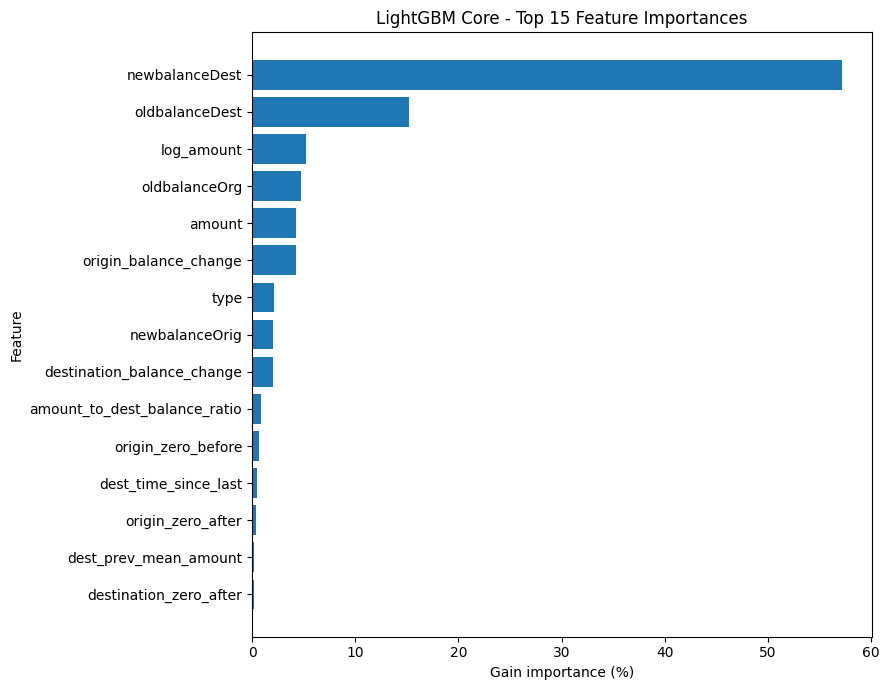

In [540]:
# Visualiser les principales variables Core
core_top_features = (
    lgb_core_importance_df
    .head(15)
    .sort_values(
        "gain_pct",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    core_top_features["feature"],
    core_top_features["gain_pct"]
)

plt.xlabel("Gain importance (%)")
plt.ylabel("Feature")
plt.title(
    "LightGBM Core - Top 15 Feature Importances"
)

plt.tight_layout()
plt.show()

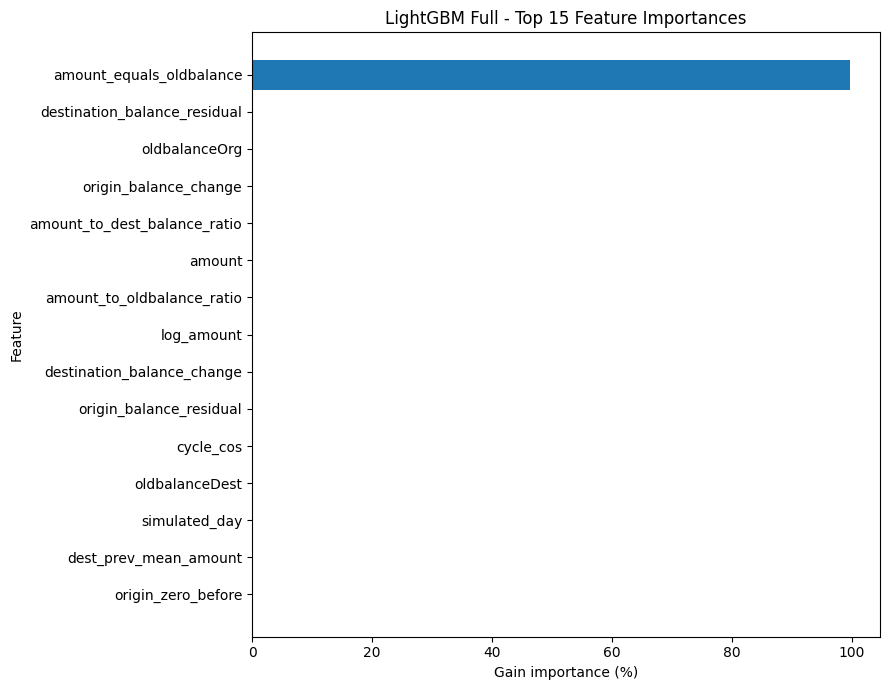

In [541]:
# Visualiser les principales variables Full
full_top_features = (
    lgb_full_importance_df
    .head(15)
    .sort_values(
        "gain_pct",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    full_top_features["feature"],
    full_top_features["gain_pct"]
)

plt.xlabel("Gain importance (%)")
plt.ylabel("Feature")
plt.title(
    "LightGBM Full - Top 15 Feature Importances"
)

plt.tight_layout()
plt.show()

### 12.1 Native Feature Importance - Interpretation

L'analyse des importances natives de LightGBM révèle des comportements très différents entre les configurations Core et Full.

#### LightGBM Core

Le modèle Core repose principalement sur les variables décrivant les montants et l'évolution des soldes.

La variable la plus importante est `newbalanceDest`, qui représente environ **57,19 %** du gain total. Elle est suivie par `oldbalanceDest` avec **15,20 %**. Les variables `log_amount`, `oldbalanceOrg`, `amount` et `origin_balance_change` contribuent également de manière notable.

Les cinq variables les plus importantes concentrent environ **86,66 %** du gain total et les dix premières environ **97,95 %**.

Le signal prédictif du modèle Core reste donc relativement concentré, mais il est réparti entre plusieurs informations transactionnelles et de solde. Aucune variable unique ne présente le caractère quasi déterministe observé dans la configuration Full.

Les variables historiques comportementales ne figurent pas parmi les variables les plus importantes selon le gain LightGBM. Cette observation ne permet toutefois pas de conclure qu'elles sont inutiles : l'importance native mesure l'utilisation prédictive des variables dans un modèle donné et non leur contribution causale ou incrémentale. Une expérience d'ablation spécifique sera nécessaire pour mesurer leur valeur ajoutée.

#### LightGBM Full

La structure du modèle Full est radicalement différente.

La variable PaySim-sensitive `amount_equals_oldbalance` représente à elle seule environ **99,66 % du gain total** du modèle. Elle n'est pourtant utilisée que dans un seul split, ce qui signifie qu'une séparation fondée sur cette variable apporte une réduction extrêmement importante de l'erreur dès la construction des arbres.

Les autres variables ont une importance marginale en comparaison. `destination_balance_residual`, deuxième variable en importance, représente seulement environ **0,10 % du gain total**.

Au total, les neuf variables identifiées comme PaySim-sensitive concentrent environ **99,79 % du gain**, contre seulement **0,21 % pour l'ensemble des variables Core**.

Cette domination explique directement les performances presque parfaites observées avec les modèles Full. Elle confirme que le gain de performance ne provient pas principalement d'une exploitation plus fine des comportements transactionnels généraux, mais d'un signal extrêmement discriminant lié au fonctionnement du simulateur PaySim.

L'importance de `amount_equals_oldbalance` ne doit donc pas être interprétée comme une règle universelle selon laquelle une transaction égale au solde disponible serait nécessairement frauduleuse dans un système Mobile Money réel.

Il s'agit d'une importance prédictive propre aux données étudiées et non d'une relation causale.

Ces résultats renforcent la décision de considérer LightGBM Core comme la baseline tabulaire principale du projet, tandis que LightGBM Full constitue une borne supérieure fortement dépendante des artefacts de PaySim.

### 12.2 Lightweight SHAP Analysis - LightGBM Core

L'importance par gain permet d'identifier les variables fortement utilisées par le modèle, mais elle ne fournit pas d'information sur la direction de leur contribution aux prédictions.

Une analyse SHAP légère est donc envisagée uniquement pour LightGBM Core.

Afin de conserver un coût mémoire et computationnel raisonnable, l'analyse sera réalisée sur un échantillon limité de la Validation plutôt que sur l'ensemble du dataset.

La configuration Full n'est pas analysée en profondeur avec SHAP à ce stade, car son importance prédictive est déjà presque entièrement dominée par la variable PaySim-sensitive `amount_equals_oldbalance`.

Les valeurs SHAP doivent être interprétées comme des contributions au comportement du modèle et non comme des effets causaux.

In [542]:
# Vérifier la disponibilité de SHAP
shap_available = (
    importlib.util.find_spec("shap")
    is not None
)

print(
    "SHAP disponible :",
    shap_available
)

SHAP disponible : True


In [543]:
# Importer SHAP
import shap

print(
    "SHAP version :",
    shap.__version__
)

SHAP version : 0.52.0


#### SHAP Sampling Strategy

Deux échantillons distincts sont utilisés pour l'analyse SHAP.

Un premier échantillon aléatoire de la Validation conserve approximativement la distribution réelle des transactions et sert à l'analyse globale du comportement du modèle.

Un second échantillon, enrichi en fraudes, contient toutes les transactions frauduleuses de la Validation ainsi qu'un sous-échantillon reproductible de transactions légitimes. Il est utilisé uniquement pour faciliter l'étude des contributions associées aux prédictions de fraude.

L'échantillon enrichi n'est donc pas interprété comme représentatif de la prévalence réelle de la fraude.

In [544]:
# Initialiser le générateur aléatoire
rng = np.random.default_rng(
    RANDOM_STATE
)

validation_indices = df.index[
    validation_mask
].to_numpy()

print(
    "Transactions Validation :",
    len(validation_indices)
)

Transactions Validation : 792406


In [545]:
# Construire l'échantillon global
SHAP_GLOBAL_SIZE = 5000

shap_global_indices = rng.choice(
    validation_indices,
    size=SHAP_GLOBAL_SIZE,
    replace=False
)

X_shap_global = df.loc[
    shap_global_indices,
    core_ml_features
].copy()

y_shap_global = df.loc[
    shap_global_indices,
    TARGET
].to_numpy()

print(
    "Global sample :",
    X_shap_global.shape
)

print(
    "Fraudes global sample :",
    int(y_shap_global.sum())
)

print(
    "Taux fraude global sample :",
    f"{100 * y_shap_global.mean():.4f}%"
)

Global sample : (5000, 22)
Fraudes global sample : 4
Taux fraude global sample : 0.0800%


In [546]:
# Identifier les fraudes Validation
validation_fraud_indices = df.index[
    validation_mask
    & (df[TARGET] == 1)
].to_numpy()

validation_legitimate_indices = df.index[
    validation_mask
    & (df[TARGET] == 0)
].to_numpy()

print(
    "Fraudes Validation :",
    len(validation_fraud_indices)
)

print(
    "Légitimes Validation :",
    len(validation_legitimate_indices)
)

Fraudes Validation : 638
Légitimes Validation : 791768


In [547]:
# Échantillonner les transactions légitimes
SHAP_LEGITIMATE_SIZE = 3000

shap_legitimate_indices = rng.choice(
    validation_legitimate_indices,
    size=SHAP_LEGITIMATE_SIZE,
    replace=False
)

shap_focus_indices = np.concatenate(
    [
        validation_fraud_indices,
        shap_legitimate_indices
    ]
)

rng.shuffle(
    shap_focus_indices
)

X_shap_focus = df.loc[
    shap_focus_indices,
    core_ml_features
].copy()

y_shap_focus = df.loc[
    shap_focus_indices,
    TARGET
].to_numpy()

print(
    "Fraud-focused sample :",
    X_shap_focus.shape
)

print(
    "Fraudes :",
    int(y_shap_focus.sum())
)

print(
    "Légitimes :",
    int(
        len(y_shap_focus)
        - y_shap_focus.sum()
    )
)

Fraud-focused sample : (3638, 22)
Fraudes : 638
Légitimes : 3000


In [548]:
# Vérifier la mémoire SHAP
print(
    "Mémoire Global :",
    f"{X_shap_global.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

print(
    "Mémoire Fraud-focused :",
    f"{X_shap_focus.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

if importlib.util.find_spec("psutil") is not None:
    memory = psutil.virtual_memory()

    print(
        "RAM disponible :",
        f"{memory.available / (1024 ** 3):.2f} GB"
    )

Mémoire Global : 0.46 MB
Mémoire Fraud-focused : 0.34 MB
RAM disponible : 1.93 GB


In [549]:
# Construire l'explainer
shap_explainer_core = shap.TreeExplainer(
    lgb_core_model.booster_
)

print(
    "Explainer :",
    type(shap_explainer_core)
)

Explainer : <class 'shap.explainers._tree.TreeExplainer'>


In [550]:
# Calculer les valeurs SHAP globales
start = perf_counter()

shap_global_values = (
    shap_explainer_core(
        X_shap_global
    )
)

shap_global_time = (
    perf_counter() - start
)

print(
    "Temps SHAP :",
    f"{shap_global_time:.2f} s"
)

print(
    "Type :",
    type(shap_global_values)
)

print(
    "Shape values :",
    shap_global_values.values.shape
)

print(
    "Shape data :",
    np.asarray(
        shap_global_values.data
    ).shape
)

print(
    "Shape base_values :",
    np.asarray(
        shap_global_values.base_values
    ).shape
)

Temps SHAP : 6.36 s
Type : <class 'shap._explanation.Explanation'>
Shape values : (5000, 22)
Shape data : (5000, 22)
Shape base_values : (5000,)


#### SHAP Additivity Check

Avant d'interpréter les contributions SHAP, leur cohérence avec la sortie du modèle est vérifiée.

Pour chaque observation, la somme de la valeur de base et des contributions SHAP doit reproduire le score brut produit par LightGBM.

Sur cette échelle, une contribution SHAP positive pousse la prédiction vers la classe fraude, tandis qu'une contribution négative la pousse vers la classe légitime.

In [551]:
# Vérifier l'additivité SHAP
shap_reconstructed_raw = (
    shap_global_values.base_values
    + shap_global_values.values.sum(
        axis=1
    )
)

model_raw_scores = (
    lgb_core_model.predict(
        X_shap_global,
        raw_score=True,
        num_iteration=lgb_core_model.best_iteration_
    )
)

shap_additivity_error = np.abs(
    shap_reconstructed_raw
    - model_raw_scores
)

print(
    "Écart moyen :",
    shap_additivity_error.mean()
)

print(
    "Écart maximum :",
    shap_additivity_error.max()
)

print(
    "Additivité cohérente :",
    np.allclose(
        shap_reconstructed_raw,
        model_raw_scores,
        rtol=1e-5,
        atol=1e-5
    )
)

Écart moyen : 7.078337915800148e-15
Écart maximum : 3.9968028886505635e-14
Additivité cohérente : True


In [552]:
# Calculer l'importance SHAP globale
global_mean_abs_shap = np.abs(
    shap_global_values.values
).mean(
    axis=0
)

shap_global_importance_df = pd.DataFrame({
    "feature": core_ml_features,
    "mean_abs_shap": global_mean_abs_shap
})

shap_global_importance_df[
    "importance_pct"
] = (
    100
    * shap_global_importance_df[
        "mean_abs_shap"
    ]
    / shap_global_importance_df[
        "mean_abs_shap"
    ].sum()
)

shap_global_importance_df = (
    shap_global_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

shap_global_importance_df.head(
    15
)

,feature,mean_abs_shap,importance_pct
0,type,1.312218,15.748987
1,destination_zero_after,1.009168,12.111834
2,origin_zero_after,0.993981,11.929562
3,newbalanceOrig,0.949362,11.394061
4,newbalanceDest,0.924221,11.092313
5,oldbalanceOrg,0.638352,7.661379
6,amount,0.596141,7.154763
7,origin_balance_change,0.423736,5.085595
8,destination_balance_change,0.411301,4.936351
9,amount_to_dest_balance_ratio,0.325402,3.905416


In [553]:
# Comparer Gain et SHAP
gain_shap_comparison = (
    lgb_core_importance_df[
        [
            "feature",
            "gain_pct"
        ]
    ]
    .merge(
        shap_global_importance_df[
            [
                "feature",
                "importance_pct"
            ]
        ],
        on="feature",
        how="left"
    )
)

gain_shap_comparison[
    "gain_rank"
] = (
    gain_shap_comparison[
        "gain_pct"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

gain_shap_comparison[
    "shap_rank"
] = (
    gain_shap_comparison[
        "importance_pct"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

gain_shap_comparison[
    [
        "feature",
        "gain_pct",
        "importance_pct",
        "gain_rank",
        "shap_rank"
    ]
].sort_values(
    "shap_rank"
).head(
    15
)

,feature,gain_pct,importance_pct,gain_rank,shap_rank
6,type,2.110590,15.748987,7,1
14,destination_zero_after,0.176766,12.111834,15,2
12,origin_zero_after,0.365547,11.929562,13,3
7,newbalanceOrig,2.055342,11.394061,8,4
0,newbalanceDest,57.188486,11.092313,1,5
3,oldbalanceOrg,4.788529,7.661379,4,6
4,amount,4.274317,7.154763,5,7
5,origin_balance_change,4.234532,5.085595,6,8
8,destination_balance_change,2.014010,4.936351,9,9
9,amount_to_dest_balance_ratio,0.872193,3.905416,10,10


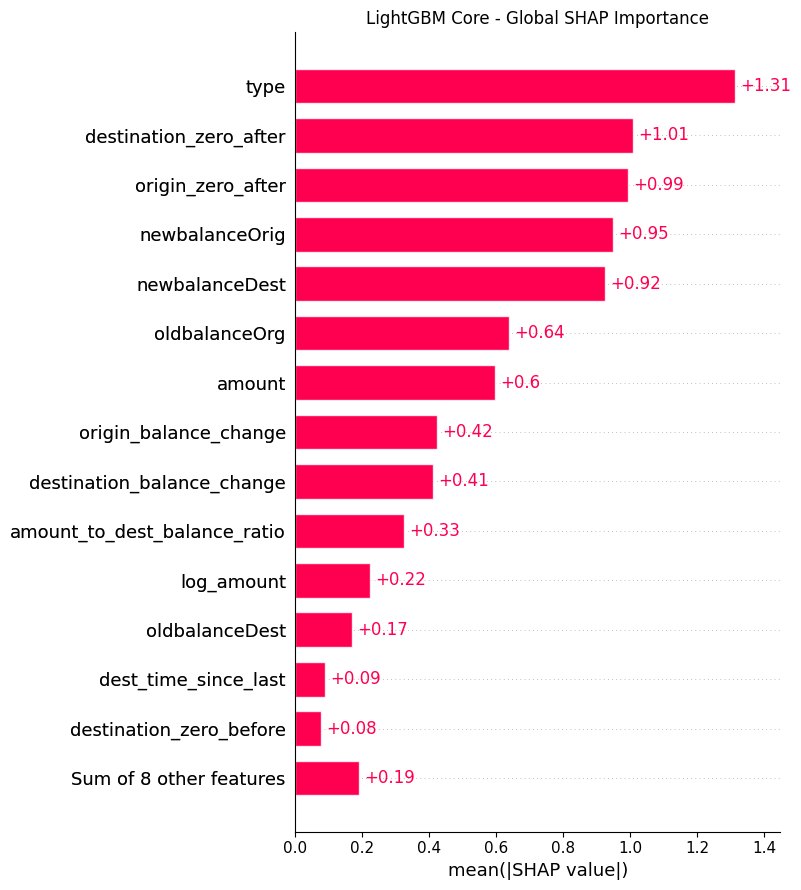

In [554]:
# Visualiser l'importance SHAP globale
shap.plots.bar(
    shap_global_values,
    max_display=15,
    show=False
)

plt.title(
    "LightGBM Core - Global SHAP Importance"
)

plt.tight_layout()
plt.show()

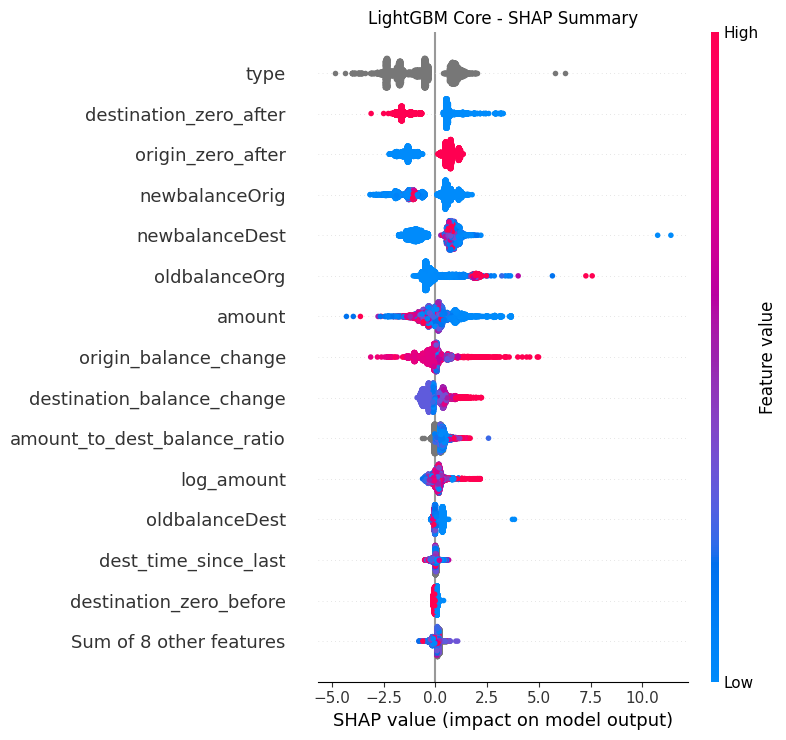

In [555]:
# Visualiser les contributions SHAP
shap.plots.beeswarm(
    shap_global_values,
    max_display=15,
    show=False
)

plt.title(
    "LightGBM Core - SHAP Summary"
)

plt.tight_layout()
plt.show()

In [556]:
# Calculer SHAP sur l'échantillon orienté fraude
start = perf_counter()

shap_focus_values = (
    shap_explainer_core(
        X_shap_focus
    )
)

shap_focus_time = (
    perf_counter()
    - start
)

print(
    "Temps SHAP :",
    f"{shap_focus_time:.2f} s"
)

print(
    "Shape :",
    shap_focus_values.values.shape
)

Temps SHAP : 4.57 s
Shape : (3638, 22)


In [557]:
# Séparer fraude et légitime
fraud_mask_shap = (
    y_shap_focus == 1
)

legitimate_mask_shap = (
    y_shap_focus == 0
)

fraud_mean_abs_shap = np.abs(
    shap_focus_values.values[
        fraud_mask_shap
    ]
).mean(
    axis=0
)

legitimate_mean_abs_shap = np.abs(
    shap_focus_values.values[
        legitimate_mask_shap
    ]
).mean(
    axis=0
)

fraud_mean_signed_shap = (
    shap_focus_values.values[
        fraud_mask_shap
    ]
    .mean(
        axis=0
    )
)

shap_class_comparison_df = pd.DataFrame({
    "feature": core_ml_features,
    "fraud_mean_abs_shap": fraud_mean_abs_shap,
    "legitimate_mean_abs_shap": legitimate_mean_abs_shap,
    "fraud_mean_signed_shap": fraud_mean_signed_shap
})

shap_class_comparison_df[
    "fraud_vs_legitimate_ratio"
] = np.divide(
    shap_class_comparison_df[
        "fraud_mean_abs_shap"
    ],
    shap_class_comparison_df[
        "legitimate_mean_abs_shap"
    ],
    out=np.full(
        len(
            shap_class_comparison_df
        ),
        np.nan
    ),
    where=(
        shap_class_comparison_df[
            "legitimate_mean_abs_shap"
        ] > 0
    )
)

shap_class_comparison_df = (
    shap_class_comparison_df
    .sort_values(
        "fraud_mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

shap_class_comparison_df.head(
    15
)

,feature,fraud_mean_abs_shap,legitimate_mean_abs_shap,fraud_mean_signed_shap,fraud_vs_legitimate_ratio
0,newbalanceDest,5.707515,0.919952,5.702620,6.204144
1,oldbalanceOrg,4.274535,0.649774,4.242708,6.578492
2,type,3.407446,1.312785,3.407446,2.595586
3,origin_balance_change,3.263664,0.423756,3.180667,7.701755
4,oldbalanceDest,1.662350,0.170495,1.648513,9.750163
5,amount,1.655294,0.585891,-0.475122,2.825257
6,destination_zero_after,1.417289,1.013134,-0.929914,1.398916
7,newbalanceOrig,1.162411,0.964054,1.123494,1.205753
8,origin_zero_after,1.099868,1.004898,1.056517,1.094507
9,log_amount,0.951732,0.226448,0.528184,4.202874


In [558]:
# Extraire les fraudes
shap_fraud_values = (
    shap_focus_values[
        fraud_mask_shap
    ]
)

print(
    "Fraudes expliquées :",
    shap_fraud_values.shape
)

Fraudes expliquées : (638, 22)


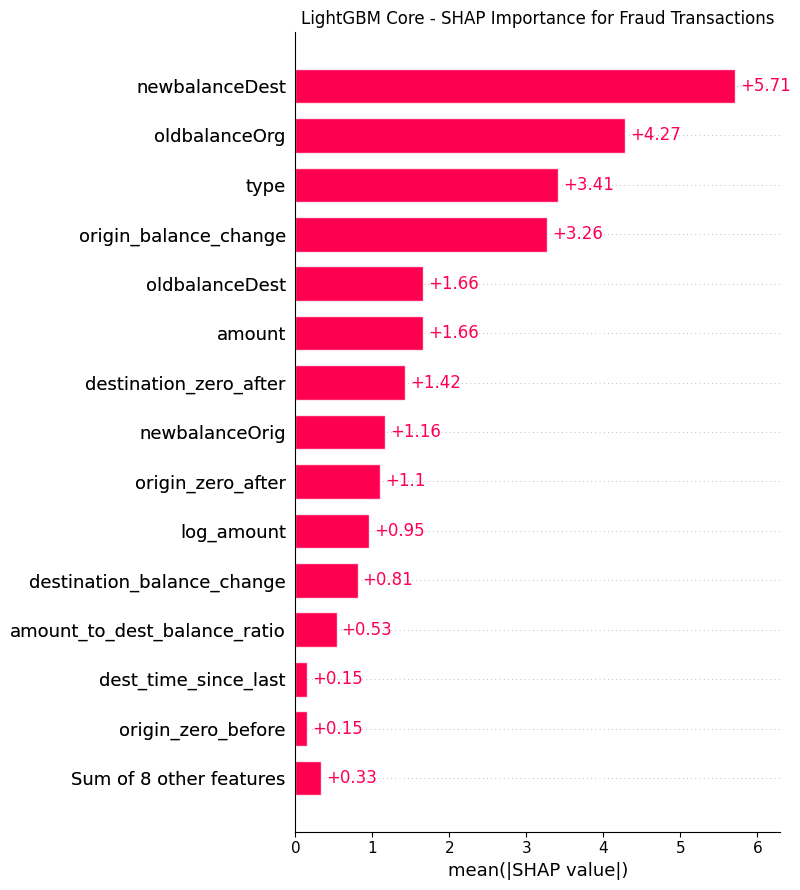

In [559]:
# Visualiser les contributions pour les fraudes
shap.plots.bar(
    shap_fraud_values,
    max_display=15,
    show=False
)

plt.title(
    "LightGBM Core - SHAP Importance for Fraud Transactions"
)

plt.tight_layout()
plt.show()

In [560]:
# Mesurer la concentration SHAP globale
shap_top5_pct = (
    shap_global_importance_df[
        "importance_pct"
    ]
    .head(5)
    .sum()
)

shap_top10_pct = (
    shap_global_importance_df[
        "importance_pct"
    ]
    .head(10)
    .sum()
)

print(
    "SHAP Top 5 :",
    f"{shap_top5_pct:.2f}%"
)

print(
    "SHAP Top 10 :",
    f"{shap_top10_pct:.2f}%"
)

SHAP Top 5 : 62.28%
SHAP Top 10 : 91.02%


### 12.2 Lightweight SHAP Analysis - Interpretation

L'analyse SHAP de LightGBM Core est réalisée sur deux échantillons complémentaires de la Validation.

L'échantillon global contient 5 000 transactions tirées aléatoirement et conserve approximativement la prévalence réelle de la fraude. Il contient 4 fraudes, soit 0,0800 % des observations. Un second échantillon enrichi contient les 638 fraudes de la Validation et 3 000 transactions légitimes afin d'étudier plus précisément le comportement du modèle sur les cas frauduleux.

La cohérence mathématique des explications est vérifiée avant leur interprétation. L'erreur moyenne d'additivité est de l'ordre de `7 × 10⁻¹⁵` et l'erreur maximale de l'ordre de `4 × 10⁻¹⁴`, confirmant que les contributions SHAP reconstruisent correctement la sortie brute de LightGBM.

#### Global SHAP importance

L'importance SHAP globale présente une distribution plus équilibrée que l'importance native par gain.

Les principales variables sont :

- `type` : environ 15,75 % ;
- `destination_zero_after` : 12,11 % ;
- `origin_zero_after` : 11,93 % ;
- `newbalanceOrig` : 11,39 % ;
- `newbalanceDest` : 11,09 %.

Les cinq premières variables concentrent environ **62,28 %** de l'importance SHAP et les dix premières environ **91,02 %**.

Le classement diffère sensiblement de l'importance native LightGBM. Par exemple, `newbalanceDest`, première variable selon le gain, se situe au cinquième rang selon SHAP, tandis que `type`, seulement septième selon le gain, devient la première variable selon la contribution SHAP moyenne.

Cette différence est attendue : le gain mesure l'amélioration de la fonction objectif apportée par les divisions des arbres, tandis que SHAP mesure l'amplitude moyenne de la contribution des variables aux prédictions individuelles.

Les deux mesures sont donc complémentaires plutôt que contradictoires.

#### Contributions sur les transactions frauduleuses

L'analyse spécifique des 638 transactions frauduleuses fait apparaître une hiérarchie différente de celle de la population globale.

Les contributions moyennes absolues les plus élevées concernent principalement :

- `newbalanceDest` ;
- `oldbalanceOrg` ;
- `type` ;
- `origin_balance_change` ;
- `oldbalanceDest` ;
- `amount`.

Pour les fraudes observées, `newbalanceDest`, `oldbalanceOrg`, `type` et `origin_balance_change` présentent notamment des contributions moyennes signées fortement positives. Ces variables tendent donc à déplacer la sortie du modèle vers la classe fraude dans ces observations.

Certaines variables présentent cependant un comportement plus complexe. Par exemple, `amount` possède une contribution absolue importante mais une contribution moyenne signée légèrement négative sur les transactions frauduleuses. Son influence ne peut donc pas être résumée par une relation monotone simple.

Les graphiques SHAP confirment ainsi que LightGBM Core exploite plusieurs interactions non linéaires entre le type de transaction, les montants, les soldes et leurs évolutions.

Ces contributions doivent être interprétées comme des explications du comportement du modèle et non comme des relations causales avec la fraude.

Contrairement au modèle Full, dont l'importance prédictive est presque entièrement dominée par une variable PaySim-sensitive, le modèle Core combine plusieurs signaux transactionnels. Cette caractéristique renforce son intérêt comme baseline tabulaire principale du projet.

## 13. Behavioral Feature Ablation

Les importances LightGBM et SHAP montrent que les variables historiques causales ne figurent pas parmi les principaux prédicteurs du modèle Core.

Une faible importance individuelle ne permet toutefois pas de conclure à leur absence de valeur prédictive.

Une expérience d'ablation est donc réalisée afin de mesurer directement leur contribution.

Deux configurations sont comparées sur la Validation :

- LightGBM Core complet ;
- LightGBM Core sans les variables historiques causales.

Toutes les autres caractéristiques du protocole sont conservées identiques. Le Test final n'est pas réutilisé pour cette expérience.

In [561]:
# Définir les historiques causaux
historical_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_mean_amount",
    "orig_time_since_last",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_mean_amount",
    "dest_time_since_last"
]

print(
    "Features historiques :",
    len(historical_features)
)

print()

for feature in historical_features:
    print("-", feature)

Features historiques : 8

- orig_prev_transactions
- orig_prev_volume
- orig_prev_mean_amount
- orig_time_since_last
- dest_prev_transactions
- dest_prev_volume
- dest_prev_mean_amount
- dest_time_since_last


In [562]:
# Vérifier leur présence dans Core
historical_in_core = [
    feature
    for feature in historical_features
    if feature in core_ml_features
]

historical_missing_core = [
    feature
    for feature in historical_features
    if feature not in core_ml_features
]

print(
    "Historiques présents dans Core :",
    len(historical_in_core)
)

print(
    "Historiques absents de Core :",
    historical_missing_core
)

Historiques présents dans Core : 8
Historiques absents de Core : []


In [563]:
# Construire Core sans historiques
core_no_history_features = [
    feature
    for feature in core_ml_features
    if feature not in historical_features
]

print(
    "Core complet :",
    len(core_ml_features)
)

print(
    "Historiques retirés :",
    len(historical_in_core)
)

print(
    "Core sans historiques :",
    len(core_no_history_features)
)

print()

print(
    core_no_history_features
)

Core complet : 22
Historiques retirés : 8
Core sans historiques : 14

['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'log_amount', 'amount_to_dest_balance_ratio', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after', 'type']


In [564]:
# Vérifier les différences
print(
    "Core - No History :",
    sorted(
        set(core_ml_features)
        - set(core_no_history_features)
    )
)

print(
    "No History hors Core :",
    sorted(
        set(core_no_history_features)
        - set(core_ml_features)
    )
)

Core - No History : ['dest_prev_mean_amount', 'dest_prev_transactions', 'dest_prev_volume', 'dest_time_since_last', 'orig_prev_mean_amount', 'orig_prev_transactions', 'orig_prev_volume', 'orig_time_since_last']
No History hors Core : []


In [565]:
# Estimer la mémoire
core_no_history_memory = (
    df[
        core_no_history_features
    ]
    .memory_usage(
        deep=True
    )
    .sum()
)

train_no_history_mb = (
    core_no_history_memory
    * train_mask.mean()
    / (1024 ** 2)
)

validation_no_history_mb = (
    core_no_history_memory
    * validation_mask.mean()
    / (1024 ** 2)
)

print(
    "Dataset complet estimé :",
    f"{core_no_history_memory / (1024 ** 2):.2f} MB"
)

print(
    "Train estimé :",
    f"{train_no_history_mb:.2f} MB"
)

print(
    "Validation estimée :",
    f"{validation_no_history_mb:.2f} MB"
)

Dataset complet estimé : 370.14 MB
Train estimé : 277.57 MB
Validation estimée : 46.10 MB


### 13.1 Ablation Configuration

Les huit variables historiques causales présentes dans le jeu Core sont retirées afin de construire une configuration d'ablation.

Les variables concernées sont :

- `orig_prev_transactions`
- `orig_prev_volume`
- `orig_prev_mean_amount`
- `orig_time_since_last`
- `dest_prev_transactions`
- `dest_prev_volume`
- `dest_prev_mean_amount`
- `dest_time_since_last`

Le nombre de prédicteurs passe ainsi de **22 à 14**.

La configuration obtenue conserve uniquement les informations transactionnelles courantes, les soldes, leurs transformations et le type de transaction.

Aucune autre variable n'est ajoutée ou supprimée. Cette expérience permet donc d'isoler directement la contribution prédictive des informations historiques construites avec la contrainte causale `step < t`.

L'évaluation de l'ablation est limitée au Train et à la Validation. Le Test final n'est pas réutilisé.

### 13.2 LightGBM Core Without Historical Features

LightGBM Core est réentraîné après suppression des huit variables historiques.

L'estimateur original est cloné afin de conserver exactement la même configuration expérimentale. La seule modification concerne donc le jeu de variables.

L'Average Precision sur la Validation constitue la métrique principale de l'expérience d'ablation.

In [631]:
# Cloner la configuration Core
from sklearn.base import clone

lgb_core_no_history_model = clone(
    lgb_core_model
)

print(
    lgb_core_no_history_model
)

LGBMClassifier(colsample_bytree=0.8, force_col_wise=True, learning_rate=0.05,
               max_bin=127, metric='average_precision', min_child_samples=50,
               n_estimators=500, n_jobs=2, objective='binary', random_state=42,
               reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbosity=-1)


In [632]:
# Vérifier les paramètres principaux
ablation_params = [
    "n_estimators",
    "learning_rate",
    "num_leaves",
    "max_depth",
    "min_child_samples",
    "subsample",
    "subsample_freq",
    "colsample_bytree",
    "reg_alpha",
    "reg_lambda",
    "class_weight",
    "random_state",
    "n_jobs"
]

original_params = (
    lgb_core_model.get_params()
)

ablation_model_params = (
    lgb_core_no_history_model.get_params()
)

param_check = pd.DataFrame(
    {
        "parameter": ablation_params,
        "core": [
            original_params[param]
            for param in ablation_params
        ],
        "no_history": [
            ablation_model_params[param]
            for param in ablation_params
        ]
    }
)

param_check[
    "same"
] = (
    param_check["core"]
    == param_check["no_history"]
)

param_check

,parameter,core,no_history,same
0,n_estimators,500.00,500.00,True
1,learning_rate,0.05,0.05,True
2,num_leaves,31.00,31.00,True
3,max_depth,-1.00,-1.00,True
4,min_child_samples,50.00,50.00,True
5,subsample,0.80,0.80,True
6,subsample_freq,1.00,1.00,True
7,colsample_bytree,0.80,0.80,True
8,reg_alpha,0.00,0.00,True
9,reg_lambda,1.00,1.00,True


In [633]:
# Vérifier la cohérence des paramètres
print(
    "Tous les paramètres identiques :",
    param_check["same"].all()
)

Tous les paramètres identiques : False


In [634]:
# Vérifier la mémoire disponible
gc.collect()

memory = psutil.virtual_memory()

print(
    "RAM disponible avant préparation :",
    f"{memory.available / (1024 ** 3):.2f} GB"
)

RAM disponible avant préparation : 1.22 GB


In [635]:
# Préparer Train sans historiques
X_train_no_history = df.loc[
    train_mask,
    core_no_history_features
].copy()

print(
    "Train :",
    X_train_no_history.shape
)

print(
    "Mémoire Train :",
    f"{X_train_no_history.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Train : (4771387, 14)
Mémoire Train : 277.57 MB


In [636]:
# Préparer Validation sans historiques
X_validation_no_history = df.loc[
    validation_mask,
    core_no_history_features
].copy()

print(
    "Validation :",
    X_validation_no_history.shape
)

print(
    "Mémoire Validation :",
    f"{X_validation_no_history.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

print(
    "Type catégoriel :",
    X_train_no_history["type"].dtype
)

Validation : (792406, 14)
Mémoire Validation : 46.10 MB
Type catégoriel : category


In [637]:
# Vérifier la RAM avant entraînement
memory = psutil.virtual_memory()

print(
    "RAM disponible avant fit :",
    f"{memory.available / (1024 ** 3):.2f} GB"
)

RAM disponible avant fit : 0.84 GB


In [638]:
# Importer les callbacks LightGBM
from lightgbm import (
    early_stopping,
    log_evaluation
)

In [639]:
# Entraîner LightGBM sans historiques
start = perf_counter()

lgb_core_no_history_model.fit(
    X_train_no_history,
    y_train,
    eval_set=[
        (
            X_validation_no_history,
            y_validation
        )
    ],
    eval_names=[
        "Validation"
    ],
    eval_metric="average_precision",
    callbacks=[
        early_stopping(
            stopping_rounds=50,
            first_metric_only=True
        ),
        log_evaluation(
            period=25
        )
    ]
)

lgb_no_history_fit_time = (
    perf_counter()
    - start
)

print(
    "Temps d'entraînement :",
    f"{lgb_no_history_fit_time:.2f} s"
)

print(
    "Temps d'entraînement :",
    f"{lgb_no_history_fit_time / 60:.2f} min"
)

print(
    "Best iteration :",
    lgb_core_no_history_model.best_iteration_
)

print(
    "Nombre d'arbres :",
    lgb_core_no_history_model.booster_.num_trees()
)

print(
    "Best score :",
    lgb_core_no_history_model.best_score_
)

Training until validation scores don't improve for 50 rounds
[25]	Validation's average_precision: 0.896996
[50]	Validation's average_precision: 0.915398
[75]	Validation's average_precision: 0.920622
[100]	Validation's average_precision: 0.924388
[125]	Validation's average_precision: 0.926543
[150]	Validation's average_precision: 0.927819
[175]	Validation's average_precision: 0.929089
[200]	Validation's average_precision: 0.929405
[225]	Validation's average_precision: 0.929915
[250]	Validation's average_precision: 0.930105
[275]	Validation's average_precision: 0.930638
[300]	Validation's average_precision: 0.930444
[325]	Validation's average_precision: 0.930818
[350]	Validation's average_precision: 0.930622
[375]	Validation's average_precision: 0.930507
Early stopping, best iteration is:
[328]	Validation's average_precision: 0.930854
Evaluated only: average_precision
Temps d'entraînement : 206.02 s
Temps d'entraînement : 3.43 min
Best iteration : 328
Nombre d'arbres : 328
Best score : d

In [640]:
# Prédire sur Validation
start = perf_counter()

lgb_no_history_validation_scores = (
    lgb_core_no_history_model.predict_proba(
        X_validation_no_history,
        num_iteration=(
            lgb_core_no_history_model.best_iteration_
        )
    )[:, 1]
)

lgb_no_history_predict_time = (
    perf_counter()
    - start
)

print(
    "Temps de prédiction :",
    f"{lgb_no_history_predict_time:.2f} s"
)

print(
    "Score minimum :",
    lgb_no_history_validation_scores.min()
)

print(
    "Score maximum :",
    lgb_no_history_validation_scores.max()
)

print(
    "Score moyen :",
    lgb_no_history_validation_scores.mean()
)

Temps de prédiction : 15.21 s
Score minimum : 6.578470903792845e-17
Score maximum : 0.999994709659167
Score moyen : 0.0007851354109163459


In [641]:
# Évaluer le modèle d'ablation
lgb_no_history_metrics = (
    evaluate_binary_classifier(
        y_true=y_validation,
        y_score=lgb_no_history_validation_scores,
        model_name="LightGBM",
        feature_set="Core No History",
        threshold=0.5
    )
)

pd.DataFrame(
    [lgb_no_history_metrics]
)[display_columns]

,model,feature_set,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,LightGBM,Core No History,0.5,0.930854,0.999897,0.977912,0.763323,0.857394,0.881654,0.999796,487,11,151,791757


In [642]:
# Comparer Core avec et sans historique
behavioral_ablation_df = pd.DataFrame(
    [
        {
            "configuration": "Core",
            "n_features": len(
                core_ml_features
            ),
            "historical_features": 8,
            "best_iteration": (
                lgb_core_model.best_iteration_
            ),
            "average_precision": (
                lgb_core_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_core_metrics[
                    "roc_auc"
                ]
            )
        },
        {
            "configuration": "Core No History",
            "n_features": len(
                core_no_history_features
            ),
            "historical_features": 0,
            "best_iteration": (
                lgb_core_no_history_model.best_iteration_
            ),
            "average_precision": (
                lgb_no_history_metrics[
                    "average_precision"
                ]
            ),
            "roc_auc": (
                lgb_no_history_metrics[
                    "roc_auc"
                ]
            )
        }
    ]
)

behavioral_ablation_df

,configuration,n_features,historical_features,best_iteration,average_precision,roc_auc
0,Core,22,8,209,0.929704,0.999892
1,Core No History,14,0,328,0.930854,0.999897


In [643]:
# Mesurer la contribution des historiques
core_ap = lgb_core_metrics[
    "average_precision"
]

no_history_ap = lgb_no_history_metrics[
    "average_precision"
]

core_roc = lgb_core_metrics[
    "roc_auc"
]

no_history_roc = lgb_no_history_metrics[
    "roc_auc"
]

history_ap_gain = (
    core_ap
    - no_history_ap
)

history_ap_relative_gain = (
    100
    * history_ap_gain
    / no_history_ap
)

history_roc_gain = (
    core_roc
    - no_history_roc
)

print(
    "AP Core :",
    core_ap
)

print(
    "AP sans historiques :",
    no_history_ap
)

print(
    "Gain AP absolu :",
    f"{history_ap_gain:+.6f}"
)

print(
    "Gain AP relatif :",
    f"{history_ap_relative_gain:+.2f}%"
)

print(
    "Gain ROC-AUC :",
    f"{history_roc_gain:+.6f}"
)

AP Core : 0.9297036922443951
AP sans historiques : 0.9308537077777049
Gain AP absolu : -0.001150
Gain AP relatif : -0.12%
Gain ROC-AUC : -0.000005


In [644]:
# Libérer le Train d'ablation
del X_train_no_history

gc.collect()

memory = psutil.virtual_memory()

print(
    "RAM disponible :",
    f"{memory.available / (1024 ** 3):.2f} GB"
)

RAM disponible : 1.75 GB


In [645]:
# Identifier les différences apparentes
param_check.loc[
    ~param_check["same"]
]

,parameter,core,no_history,same
10,class_weight,NaN,NaN,False


In [646]:
# Comparer correctement les paramètres
def same_parameter_value(a, b):
    if pd.isna(a) and pd.isna(b):
        return True
    return a == b

param_check["same_robust"] = [
    same_parameter_value(a, b)
    for a, b in zip(
        param_check["core"],
        param_check["no_history"]
    )
]

param_check[
    [
        "parameter",
        "core",
        "no_history",
        "same_robust"
    ]
]

,parameter,core,no_history,same_robust
0,n_estimators,500.00,500.00,True
1,learning_rate,0.05,0.05,True
2,num_leaves,31.00,31.00,True
3,max_depth,-1.00,-1.00,True
4,min_child_samples,50.00,50.00,True
5,subsample,0.80,0.80,True
6,subsample_freq,1.00,1.00,True
7,colsample_bytree,0.80,0.80,True
8,reg_alpha,0.00,0.00,True
9,reg_lambda,1.00,1.00,True


In [647]:
# Vérifier la cohérence finale
print(
    "Tous les paramètres réellement identiques :",
    param_check["same_robust"].all()
)

Tous les paramètres réellement identiques : True


### 13.3 Behavioral Feature Ablation - Interpretation

L'expérience d'ablation permet de mesurer directement la contribution des huit variables historiques causales du jeu Core.

La configuration complète contient 22 variables, tandis que la configuration d'ablation conserve 14 variables après suppression de :

- `orig_prev_transactions`
- `orig_prev_volume`
- `orig_prev_mean_amount`
- `orig_time_since_last`
- `dest_prev_transactions`
- `dest_prev_volume`
- `dest_prev_mean_amount`
- `dest_time_since_last`

Les deux modèles utilisent la même configuration LightGBM et sont entraînés sur le même Train, avec sélection du nombre d'itérations par early stopping sur la même Validation.

LightGBM Core atteint une Average Precision de **0,92970**, tandis que la configuration sans historique obtient **0,93085**.

La différence associée à l'ajout des variables historiques est donc :

- **gain AP absolu : -0,00115**
- **gain AP relatif : -0,12 %**
- **variation ROC-AUC : environ -0,000005**

La suppression des variables historiques ne provoque donc aucune dégradation de la performance de classement. La légère amélioration observée sans ces variables est trop faible pour conclure qu'elles détériorent intrinsèquement le modèle ; elle indique surtout qu'aucun bénéfice prédictif mesurable n'est observé dans cette expérience.

Les métriques au seuil de 0,5 conduisent à la même conclusion. Le modèle sans historique détecte 487 fraudes contre 483 pour le Core complet, avec le même nombre de faux positifs.

Une différence apparaît néanmoins dans la dynamique d'apprentissage : le modèle Core atteint son optimum après 209 itérations, contre 328 pour la configuration sans historique. Les variables historiques peuvent donc faciliter certaines étapes de l'apprentissage sans améliorer le meilleur pouvoir de classement finalement obtenu.

Ce résultat est cohérent avec les caractéristiques de PaySim. L'historique des comptes sources est extrêmement rare et les variables transactionnelles courantes, notamment les montants et les soldes avant et après transaction, fournissent déjà des signaux prédictifs très puissants.

Cette absence de gain ne doit pas être généralisée aux systèmes Mobile Money réels. Dans un environnement disposant d'historiques clients plus riches, les comportements passés pourraient jouer un rôle sensiblement plus important.

Pour ce dataset et cette baseline LightGBM, les huit variables historiques causales ne démontrent donc pas de valeur ajoutée mesurable sur la Validation.

## 14. Error Analysis

L'analyse des erreurs porte sur LightGBM Core, retenu comme baseline tabulaire principale.

Le modèle et son seuil de décision restent strictement inchangés. Cette section est uniquement descriptive et aucune observation issue du Test ne sera utilisée pour modifier le modèle.

L'objectif est d'identifier les caractéristiques des :

- faux négatifs : fraudes non détectées ;
- faux positifs : transactions légitimes signalées à tort.

L'analyse porte notamment sur le type de transaction, les montants, les soldes, la dimension temporelle et la position des scores par rapport au seuil de décision.

In [648]:
# Récupérer les index Test
test_indices = df.index[
    test_mask
].to_numpy()

print(
    "Lignes Test :",
    len(test_indices)
)

print(
    "Scores Test Core :",
    len(lgb_core_test_scores)
)

print(
    "Alignement :",
    len(test_indices)
    == len(lgb_core_test_scores)
)

Lignes Test : 798827
Scores Test Core : 798827
Alignement : True


In [649]:
# Construire les prédictions finales
core_test_predictions = (
    lgb_core_test_scores
    >= FINAL_CORE_THRESHOLD
).astype(np.int8)

print(
    "Fraudes prédites :",
    int(core_test_predictions.sum())
)

Fraudes prédites : 3095


In [650]:
# Identifier les erreurs
y_test_array = y_test.to_numpy()

fn_mask_test = (
    (y_test_array == 1)
    & (core_test_predictions == 0)
)

fp_mask_test = (
    (y_test_array == 0)
    & (core_test_predictions == 1)
)

print(
    "False Negatives :",
    int(fn_mask_test.sum())
)

print(
    "False Positives :",
    int(fp_mask_test.sum())
)

print(
    "Total erreurs :",
    int(
        fn_mask_test.sum()
        + fp_mask_test.sum()
    )
)

False Negatives : 790
False Positives : 55
Total erreurs : 845


In [651]:
# Identifier les erreurs
y_test_array = y_test.to_numpy()

fn_mask_test = (
    (y_test_array == 1)
    & (core_test_predictions == 0)
)

fp_mask_test = (
    (y_test_array == 0)
    & (core_test_predictions == 1)
)

print(
    "False Negatives :",
    int(fn_mask_test.sum())
)

print(
    "False Positives :",
    int(fp_mask_test.sum())
)

print(
    "Total erreurs :",
    int(
        fn_mask_test.sum()
        + fp_mask_test.sum()
    )
)

False Negatives : 790
False Positives : 55
Total erreurs : 845


In [652]:
# Sélectionner les variables d'analyse
error_analysis_features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after"
]

print(
    "Variables d'analyse :",
    len(error_analysis_features)
)

Variables d'analyse : 13


In [653]:
# Construire la table Test minimale
test_audit_df = df.loc[
    test_indices,
    error_analysis_features
].copy()

test_audit_df[
    "actual"
] = y_test_array

test_audit_df[
    "predicted"
] = core_test_predictions

test_audit_df[
    "score"
] = lgb_core_test_scores

test_audit_df[
    "error_type"
] = "Correct"

test_audit_df.loc[
    (
        (test_audit_df["actual"] == 1)
        & (test_audit_df["predicted"] == 0)
    ),
    "error_type"
] = "False Negative"

test_audit_df.loc[
    (
        (test_audit_df["actual"] == 0)
        & (test_audit_df["predicted"] == 1)
    ),
    "error_type"
] = "False Positive"

In [654]:
# Isoler les erreurs
core_errors_df = (
    test_audit_df[
        test_audit_df[
            "error_type"
        ] != "Correct"
    ]
    .copy()
)

print(
    "Dimensions erreurs :",
    core_errors_df.shape
)

print()

print(
    core_errors_df[
        "error_type"
    ].value_counts()
)

print(
    "\nMémoire :",
    f"{core_errors_df.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB"
)

Dimensions erreurs : (845, 17)

error_type
False Negative    790
False Positive     55
Name: count, dtype: int64

Mémoire : 0.08 MB


In [655]:
# Libérer la table intermédiaire
del test_audit_df

gc.collect()

600

In [656]:
# Compter les erreurs par type
error_by_type = (
    core_errors_df
    .groupby(
        [
            "error_type",
            "type"
        ],
        observed=True
    )
    .size()
    .reset_index(
        name="count"
    )
)

error_by_type

,error_type,type,count
0,False Negative,CASH_OUT,790
1,False Positive,CASH_OUT,55


In [657]:
# Calculer les proportions par type
error_by_type[
    "pct_within_error"
] = (
    error_by_type[
        "count"
    ]
    / error_by_type
      .groupby(
          "error_type"
      )[
          "count"
      ]
      .transform("sum")
    * 100
)

error_by_type

,error_type,type,count,pct_within_error
0,False Negative,CASH_OUT,790,100.0
1,False Positive,CASH_OUT,55,100.0


In [658]:
# Résumer les montants des erreurs
error_amount_summary = (
    core_errors_df
    .groupby(
        "error_type"
    )[
        "amount"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    )
)

error_amount_summary

,count,mean,median,min,max
error_type,,,,,
False Negative,790,145829.724278,111616.155,0.00,594471.04
False Positive,55,310268.134727,336363.230,287.58,688229.06


In [659]:
# Calculer les quantiles de montant
error_amount_quantiles = (
    core_errors_df
    .groupby(
        "error_type"
    )[
        "amount"
    ]
    .quantile(
        [
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.99
        ]
    )
    .unstack()
)

error_amount_quantiles

,0.10,0.25,0.50,0.75,0.90,0.99
error_type,,,,,,
False Negative,17622.208,48461.3775,111616.155,219380.830,328062.337,472036.3648
False Positive,79570.280,170846.9000,336363.230,420239.165,537111.314,678177.2894


In [660]:
# Calculer la distance au seuil
core_errors_df[
    "distance_to_threshold"
] = (
    core_errors_df["score"]
    - FINAL_CORE_THRESHOLD
)

score_error_summary = (
    core_errors_df
    .groupby(
        "error_type"
    )[
        [
            "score",
            "distance_to_threshold"
        ]
    ]
    .agg(
        [
            "mean",
            "median",
            "min",
            "max"
        ]
    )
)

score_error_summary

score                               distance_to_threshold  \
                    mean    median       min       max                  mean   
error_type                                                                     
False Negative  0.143333  0.138108  0.004898  0.311352             -0.170367   
False Positive  0.433342  0.392257  0.316075  0.875524              0.119641   

                                              
                  median       min       max  
error_type                                    
False Negative -0.175593 -0.308802 -0.002349  
False Positive  0.078557  0.002375  0.561823

In [661]:
# Quantiles des scores d'erreur
error_score_quantiles = (
    core_errors_df
    .groupby(
        "error_type"
    )[
        "score"
    ]
    .quantile(
        [
            0.01,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.99
        ]
    )
    .unstack()
)

error_score_quantiles

,0.01,0.10,0.25,0.50,0.75,0.90,0.99
error_type,,,,,,,
False Negative,0.010853,0.042284,0.071555,0.138108,0.207769,0.258431,0.307684
False Positive,0.318340,0.329739,0.361838,0.392257,0.469229,0.585426,0.789700


In [662]:
# Extraire les faux négatifs
false_negatives_df = (
    core_errors_df[
        core_errors_df[
            "error_type"
        ] == "False Negative"
    ]
    .copy()
)

fn_score_bands = pd.DataFrame(
    {
        "band": [
            "score >= 0.25",
            "score >= 0.10",
            "score >= 0.01",
            "score < 0.01"
        ],
        "count": [
            int(
                (
                    false_negatives_df[
                        "score"
                    ] >= 0.25
                ).sum()
            ),
            int(
                (
                    false_negatives_df[
                        "score"
                    ] >= 0.10
                ).sum()
            ),
            int(
                (
                    false_negatives_df[
                        "score"
                    ] >= 0.01
                ).sum()
            ),
            int(
                (
                    false_negatives_df[
                        "score"
                    ] < 0.01
                ).sum()
            )
        ]
    }
)

fn_score_bands

,band,count
0,score >= 0.25,100
1,score >= 0.10,496
2,score >= 0.01,782
3,score < 0.01,8


In [663]:
# Résumer les steps des erreurs
error_step_summary = (
    core_errors_df
    .groupby(
        "error_type"
    )[
        "step"
    ]
    .agg(
        [
            "count",
            "min",
            "median",
            "max"
        ]
    )
)

error_step_summary

,count,min,median,max
error_type,,,,
False Negative,790,394,576.5,742
False Positive,55,394,401.0,710


In [664]:
# Identifier les steps avec le plus de FN
top_fn_steps = (
    false_negatives_df[
        "step"
    ]
    .value_counts()
    .head(15)
    .rename_axis(
        "step"
    )
    .reset_index(
        name="false_negatives"
    )
)

top_fn_steps

,step,false_negatives
0,537,8
1,694,8
2,699,7
3,741,7
4,425,6
5,462,6
6,523,6
7,578,6
8,639,6
9,731,6


In [665]:
# Résumer les indicateurs zéro des FN
fn_zero_summary = pd.DataFrame(
    {
        "feature": [
            "origin_zero_before",
            "origin_zero_after",
            "destination_zero_before",
            "destination_zero_after"
        ],
        "count_true": [
            int(
                false_negatives_df[
                    feature
                ].sum()
            )
            for feature in [
                "origin_zero_before",
                "origin_zero_after",
                "destination_zero_before",
                "destination_zero_after"
            ]
        ]
    }
)

fn_zero_summary[
    "pct_false_negatives"
] = (
    100
    * fn_zero_summary[
        "count_true"
    ]
    / len(
        false_negatives_df
    )
)

fn_zero_summary

,feature,count_true,pct_false_negatives
0,origin_zero_before,9,1.139241
1,origin_zero_after,790,100.000000
2,destination_zero_before,225,28.481013
3,destination_zero_after,1,0.126582


### 14.10 Error Patterns

L'analyse des erreurs de LightGBM Core retrouve exactement les résultats de l'évaluation finale : **790 faux négatifs** et **55 faux positifs** sur les 798 827 transactions du Test.

Un premier résultat particulièrement marqué concerne le type de transaction. La totalité des erreurs observées appartient à la catégorie `CASH_OUT` : les 790 fraudes non détectées et les 55 transactions légitimes faussement signalées sont toutes des opérations de ce type.

Aucune erreur n'est observée sur les transactions `TRANSFER`. Le principal domaine de difficulté de la baseline Core se situe donc au sein des opérations `CASH_OUT`.

Les montants présentent également des profils distincts. La médiane des faux négatifs est d'environ **111 616**, contre **336 363** pour les faux positifs. Les faux positifs concernent ainsi, dans cet échantillon d'erreurs, des transactions globalement plus élevées.

L'analyse des scores montre que les fraudes manquées ne correspondent pas principalement à des observations situées juste sous le seuil de décision. Le score médian des faux négatifs est d'environ **0,138**, alors que le seuil final est d'environ **0,314**. Seulement 100 faux négatifs sur 790 obtiennent un score supérieur ou égal à 0,25.

À l'inverse, près de 99 % des faux négatifs obtiennent néanmoins un score supérieur ou égal à 0,01. Le modèle attribue donc un certain degré de suspicion à la grande majorité des fraudes manquées, sans que ce signal soit suffisant pour dépasser le seuil verrouillé sur la Validation.

Les faux positifs présentent à la fois des cas proches du seuil et quelques erreurs plus affirmées, avec des scores allant d'environ 0,316 à 0,876.

Les faux négatifs sont répartis sur presque toute la période Test, des steps 394 à 742. Aucun step ne concentre à lui seul un nombre important d'erreurs. Les faux positifs semblent davantage présents au début de la période Test, avec un step médian de 401, mais cette observation ne peut pas être interprétée indépendamment du volume de transactions de chaque période.

Enfin, toutes les fraudes manquées ont `origin_zero_after = 1`. Cette caractéristique doit cependant être comparée aux fraudes correctement détectées avant de déterminer si elle constitue réellement une particularité des faux négatifs.

### 14.11 Error Analysis by Transaction Type and Fraud Detection Status

Les erreurs doivent être replacées dans leur population de référence.

Une analyse par type de transaction est donc réalisée afin de mesurer le Recall des fraudes et le taux de faux positifs pour chaque catégorie.

Les faux négatifs sont également comparés aux fraudes correctement détectées afin d'identifier d'éventuelles différences de montant ou d'état des soldes.

Cette analyse reste strictement descriptive et ne conduit à aucune modification du modèle ou du seuil.

In [666]:
# Construire la table minimale par type
test_type_df = pd.DataFrame({
    "type": df.loc[
        test_mask,
        "type"
    ].astype(str).to_numpy(),
    "actual": y_test_array,
    "predicted": core_test_predictions
})

type_error_metrics = []

for transaction_type, group in test_type_df.groupby(
    "type"
):
    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()

    tp = int(
        ((actual == 1) & (predicted == 1)).sum()
    )

    fp = int(
        ((actual == 0) & (predicted == 1)).sum()
    )

    fn = int(
        ((actual == 1) & (predicted == 0)).sum()
    )

    tn = int(
        ((actual == 0) & (predicted == 0)).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    type_error_metrics.append({
        "type": transaction_type,
        "frauds": tp + fn,
        "tp": tp,
        "fn": fn,
        "recall": recall,
        "legitimate": fp + tn,
        "fp": fp,
        "false_positive_rate": false_positive_rate
    })

type_error_metrics_df = pd.DataFrame(
    type_error_metrics
)

type_error_metrics_df 

,type,frauds,tp,fn,recall,legitimate,fp,false_positive_rate
0,CASH_IN,0,0,0,NaN,178958,0,0.000000
1,CASH_OUT,1915,1125,790,0.587467,269136,55,0.000204
2,DEBIT,0,0,0,NaN,5739,0,0.000000
3,PAYMENT,0,0,0,NaN,272255,0,0.000000
4,TRANSFER,1915,1915,0,1.000000,68909,0,0.000000


In [667]:
# Afficher les types contenant des fraudes
type_fraud_performance_df = (
    type_error_metrics_df[
        type_error_metrics_df[
            "frauds"
        ] > 0
    ]
    .copy()
)

type_fraud_performance_df[
    "recall_pct"
] = (
    100
    * type_fraud_performance_df[
        "recall"
    ]
)

type_fraud_performance_df[
    "false_positive_rate_pct"
] = (
    100
    * type_fraud_performance_df[
        "false_positive_rate"
    ]
)

type_fraud_performance_df

,type,frauds,tp,fn,recall,legitimate,fp,false_positive_rate,recall_pct,false_positive_rate_pct
1,CASH_OUT,1915,1125,790,0.587467,269136,55,0.000204,58.746736,0.020436
4,TRANSFER,1915,1915,0,1.000000,68909,0,0.000000,100.000000,0.000000


In [668]:
# Extraire les fraudes du Test
fraud_test_mask = (
    y_test_array == 1
)

fraud_detection_df = df.loc[
    test_indices[
        fraud_test_mask
    ],
    [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest",
        "origin_zero_before",
        "origin_zero_after",
        "destination_zero_before",
        "destination_zero_after"
    ]
].copy()

fraud_detection_df[
    "score"
] = lgb_core_test_scores[
    fraud_test_mask
]

fraud_detection_df[
    "detection_status"
] = np.where(
    core_test_predictions[
        fraud_test_mask
    ] == 1,
    "True Positive",
    "False Negative"
)

print(
    fraud_detection_df[
        "detection_status"
    ].value_counts()
)

detection_status
True Positive     3040
False Negative     790
Name: count, dtype: int64


In [669]:
# Comparer les montants des fraudes
fraud_amount_comparison = (
    fraud_detection_df
    .groupby(
        "detection_status"
    )[
        "amount"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    )
)

fraud_amount_comparison

,count,mean,median,min,max
detection_status,,,,,
False Negative,790,1.458297e+05,111616.155,0.0,594471.04
True Positive,3040,1.910365e+06,761883.620,0.0,10000000.00


In [670]:
# Calculer les quantiles
fraud_amount_quantiles = (
    fraud_detection_df
    .groupby(
        "detection_status"
    )[
        "amount"
    ]
    .quantile(
        [
            0.10,
            0.25,
            0.50,
            0.75,
            0.90
        ]
    )
    .unstack()
)

fraud_amount_quantiles

,0.10,0.25,0.50,0.75,0.90
detection_status,,,,,
False Negative,17622.208,48461.3775,111616.155,219380.83,328062.337
True Positive,67109.601,240333.5850,761883.620,2119030.26,6370726.840


In [671]:
# Comparer les états zéro
zero_features = [
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after"
]

zero_detection_rows = []

for status, group in fraud_detection_df.groupby(
    "detection_status"
):
    for feature in zero_features:
        zero_detection_rows.append({
            "detection_status": status,
            "feature": feature,
            "count_true": int(
                group[
                    feature
                ].sum()
            ),
            "pct_true": (
                100
                * group[
                    feature
                ].mean()
            )
        })

fraud_zero_comparison_df = pd.DataFrame(
    zero_detection_rows
)

fraud_zero_comparison_df

,detection_status,feature,count_true,pct_true
0,False Negative,origin_zero_before,9,1.139241
1,False Negative,origin_zero_after,790,100.000000
2,False Negative,destination_zero_before,225,28.481013
3,False Negative,destination_zero_after,1,0.126582
4,True Positive,origin_zero_before,3,0.098684
5,True Positive,origin_zero_after,2941,96.743421
6,True Positive,destination_zero_before,2290,75.328947
7,True Positive,destination_zero_after,1918,63.092105


In [672]:
# Comparer les scores des fraudes
fraud_score_summary = (
    fraud_detection_df
    .groupby(
        "detection_status"
    )[
        "score"
    ]
    .agg(
        [
            "mean",
            "median",
            "min",
            "max"
        ]
    )
)

fraud_score_summary

,mean,median,min,max
detection_status,,,,
False Negative,0.143333,0.138108,0.004898,0.311352
True Positive,0.939599,0.996714,0.314648,0.999999


### 14.12 Error Analysis - Final Interpretation

L'analyse des erreurs de LightGBM Core est réalisée sur le Test final sans modification du modèle ni du seuil sélectionné sur la Validation.

Le modèle produit :

- **3 040 vrais positifs**
- **55 faux positifs**
- **790 faux négatifs**
- **794 942 vrais négatifs**

L'analyse met en évidence une forte hétérogénéité de la performance selon le type de transaction.

#### Performance selon le type de transaction

Les 3 830 fraudes du Test sont également réparties entre :

- 1 915 transactions `CASH_OUT`
- 1 915 transactions `TRANSFER`

LightGBM Core détecte les **1 915 fraudes TRANSFER**, soit un Recall de **100 %** pour cette catégorie, sans faux positif observé.

La situation est différente pour `CASH_OUT`. Parmi les 1 915 fraudes de ce type, seulement **1 125 sont détectées**, tandis que **790 sont manquées**, soit un Recall de **58,75 %**.

Les 55 faux positifs du modèle concernent également exclusivement `CASH_OUT`. Ils représentent toutefois seulement environ **0,0204 %** des transactions `CASH_OUT` légitimes.

La principale faiblesse de la baseline Core ne concerne donc pas uniformément toutes les fraudes : elle est concentrée sur les transactions frauduleuses `CASH_OUT`.

#### Montant des fraudes détectées et manquées

Les fraudes manquées ont des montants nettement plus faibles que les fraudes correctement détectées.

Pour les faux négatifs :

- montant moyen ≈ **145 830**
- médiane ≈ **111 616**
- 90e percentile ≈ **328 062**
- maximum ≈ **594 471**

Pour les vrais positifs :

- montant moyen ≈ **1 910 365**
- médiane ≈ **761 884**
- 90e percentile ≈ **6 370 727**
- maximum = **10 000 000**

La baseline Core apparaît donc beaucoup plus efficace pour identifier les fraudes de montant élevé.

#### États des soldes

L'indicateur `origin_zero_after` est présent pour 100 % des faux négatifs, mais également pour environ 96,74 % des vrais positifs. Il ne permet donc pas, à lui seul, de distinguer les fraudes détectées des fraudes manquées.

Les caractéristiques de la destination présentent en revanche des différences beaucoup plus marquées.

`destination_zero_before` est observé pour :

- environ **28,48 %** des faux négatifs ;
- environ **75,33 %** des vrais positifs.

`destination_zero_after` est observé pour :

- environ **0,13 %** des faux négatifs ;
- environ **63,09 %** des vrais positifs.

Ces résultats sont cohérents avec les analyses d'importance et SHAP, qui ont montré le rôle important des soldes destination dans les décisions de LightGBM Core.

Une partie de ces différences peut toutefois être associée au type de transaction, puisque tous les faux négatifs appartiennent à `CASH_OUT`. Elles ne doivent donc pas être interprétées comme des règles universelles de fraude Mobile Money.

#### Scores des fraudes

Les vrais positifs obtiennent des scores généralement très élevés :

- score moyen ≈ **0,940**
- médiane ≈ **0,997**

À l'inverse, les faux négatifs présentent :

- score moyen ≈ **0,143**
- médiane ≈ **0,138**
- score maximum ≈ **0,311**

avec un seuil de classification fixé à environ **0,314**.

Les fraudes manquées ne correspondent donc pas uniquement à quelques transactions situées juste sous le seuil. Elles constituent un sous-ensemble que le modèle Core classe structurellement avec une confiance sensiblement plus faible.

#### Conclusion

LightGBM Core offre une excellente capacité globale de classement et une très faible proportion de faux positifs, mais ses performances sont hétérogènes selon la nature de la fraude.

Le modèle détecte parfaitement les fraudes `TRANSFER` du Test, mais seulement environ **58,75 %** des fraudes `CASH_OUT`. Les fraudes manquées sont notamment associées à des montants plus faibles et à des configurations de soldes destination différentes de celles des fraudes correctement détectées.

Cette limite constitue un point de comparaison particulièrement pertinent pour les futurs modèles Graph Learning : au-delà des métriques globales, leur capacité à améliorer la détection des fraudes `CASH_OUT` difficiles devra être étudiée.

## 15. Saving Models and Experimental Results

Seuls les artefacts nécessaires à la reproductibilité et aux comparaisons futures avec les modèles Graph Learning sont conservés.

Les modèles sauvegardés sont :

- LightGBM Core, retenu comme baseline tabulaire principale ;
- LightGBM Full, conservé comme référence expérimentale PaySim-sensitive.

Les modèles intermédiaires Logistic Regression, Random Forest et les variantes d'ablation ne sont pas sauvegardés afin d'éviter la conservation inutile d'artefacts lourds.

Les métriques finales, seuils, feature sets, configurations expérimentales et résultats d'interprétabilité utiles sont également exportés.

In [673]:
# Définir les dossiers de sortie
from pathlib import Path

models_dir = Path(
    "../models"
)

results_dir = Path(
    "../results"
)

models_dir.mkdir(
    parents=True,
    exist_ok=True
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Models :",
    models_dir.resolve()
)

print(
    "Results :",
    results_dir.resolve()
)

Models : C:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\models
Results : C:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\results


In [674]:
# Vérifier les modèles finaux
model_artifact_check = pd.DataFrame(
    [
        {
            "artifact": "LightGBM Core",
            "exists": lgb_core_model is not None,
            "best_iteration": lgb_core_model.best_iteration_,
            "n_features": len(core_ml_features),
            "threshold": FINAL_CORE_THRESHOLD
        },
        {
            "artifact": "LightGBM Full",
            "exists": lgb_full_model is not None,
            "best_iteration": lgb_full_model.best_iteration_,
            "n_features": len(full_ml_features),
            "threshold": FINAL_FULL_THRESHOLD
        }
    ]
)

model_artifact_check

,artifact,exists,best_iteration,n_features,threshold
0,LightGBM Core,True,209,22,0.313700
1,LightGBM Full,True,65,31,0.000313


In [676]:
# Normaliser le protocole final
if "final_protocol" not in globals():
    if "final_protocol_check" in globals():
        final_protocol = final_protocol_check.copy()

print(
    "final_protocol disponible :",
    "final_protocol" in globals()
)

final_protocol

final_protocol disponible : True


,model,feature_set,best_iteration,threshold,selection_source
0,LightGBM,Core,209,0.313700,Validation
1,LightGBM,Full,65,0.000313,Validation


In [677]:
# Auditer les objets de résultats
result_object_names = {
    "validation_results": "validation_results",
    "final_protocol": "final_protocol",
    "test_core_metrics": "lgb_core_test_metrics",
    "test_full_metrics": "lgb_full_test_metrics",
    "core_importance": "lgb_core_importance_df",
    "full_importance": "lgb_full_importance_df",
    "behavioral_ablation": "behavioral_ablation_df"
}

artifact_audit = pd.DataFrame(
    [
        {
            "object": label,
            "variable": variable,
            "available": (
                variable in globals()
                and globals()[variable] is not None
            )
        }
        for label, variable
        in result_object_names.items()
    ]
)

artifact_audit

,object,variable,available
0,validation_results,validation_results,True
1,final_protocol,final_protocol,True
2,test_core_metrics,lgb_core_test_metrics,True
3,test_full_metrics,lgb_full_test_metrics,True
4,core_importance,lgb_core_importance_df,True
5,full_importance,lgb_full_importance_df,True
6,behavioral_ablation,behavioral_ablation_df,True


In [678]:
# Vérifier les modèles finaux
model_artifact_check = pd.DataFrame(
    [
        {
            "artifact": "LightGBM Core",
            "exists": lgb_core_model is not None,
            "best_iteration": lgb_core_model.best_iteration_,
            "n_features": len(core_ml_features),
            "threshold": FINAL_CORE_THRESHOLD
        },
        {
            "artifact": "LightGBM Full",
            "exists": lgb_full_model is not None,
            "best_iteration": lgb_full_model.best_iteration_,
            "n_features": len(full_ml_features),
            "threshold": FINAL_FULL_THRESHOLD
        }
    ]
)

model_artifact_check

,artifact,exists,best_iteration,n_features,threshold
0,LightGBM Core,True,209,22,0.313700
1,LightGBM Full,True,65,31,0.000313


In [679]:
# Vérifier la mémoire
gc.collect()

memory = psutil.virtual_memory()

print(
    "RAM disponible :",
    f"{memory.available / (1024 ** 3):.2f} GB"
)

print(
    "LightGBM Core arbres :",
    lgb_core_model.booster_.num_trees()
)

print(
    "LightGBM Full arbres :",
    lgb_full_model.booster_.num_trees()
)

RAM disponible : 1.13 GB
LightGBM Core arbres : 209
LightGBM Full arbres : 65


### 15.2 Final Model Export

Les deux modèles LightGBM effectivement évalués sur le Test sont sauvegardés dans leur format natif.

- **LightGBM Core** constitue la baseline tabulaire principale du projet.
- **LightGBM Full** est conservé comme référence expérimentale incluant les variables identifiées comme PaySim-sensitive.

Les modèles ne sont pas réentraînés après l'ouverture du Test : les artefacts sauvegardés correspondent exactement aux modèles ayant produit les performances finales rapportées dans ce notebook.

In [680]:
# Définir les fichiers modèles
core_model_path = (
    models_dir
    / "lightgbm_core_baseline.txt"
)

full_model_path = (
    models_dir
    / "lightgbm_full_paysim_sensitive.txt"
)

print(
    "Core :",
    core_model_path
)

print(
    "Full :",
    full_model_path
)

Core : ..\models\lightgbm_core_baseline.txt
Full : ..\models\lightgbm_full_paysim_sensitive.txt


In [681]:
# Sauvegarder les modèles LightGBM
lgb_core_model.booster_.save_model(
    str(core_model_path)
)

lgb_full_model.booster_.save_model(
    str(full_model_path)
)

print(
    "Core sauvegardé :",
    core_model_path.exists()
)

print(
    "Full sauvegardé :",
    full_model_path.exists()
)

Core sauvegardé : True
Full sauvegardé : True


In [682]:
# Vérifier la taille des modèles
model_files_df = pd.DataFrame(
    [
        {
            "model": "LightGBM Core",
            "path": str(core_model_path),
            "size_mb": (
                core_model_path.stat().st_size
                / (1024 ** 2)
            )
        },
        {
            "model": "LightGBM Full",
            "path": str(full_model_path),
            "size_mb": (
                full_model_path.stat().st_size
                / (1024 ** 2)
            )
        }
    ]
)

model_files_df

,model,path,size_mb
0,LightGBM Core,..\models\lightgbm_core_baseline.txt,0.709507
1,LightGBM Full,..\models\lightgbm_full_paysim_sensitive.txt,0.134074


In [683]:
# Recharger les modèles sauvegardés
import lightgbm as lgb

core_booster_check = lgb.Booster(
    model_file=str(
        core_model_path
    )
)

full_booster_check = lgb.Booster(
    model_file=str(
        full_model_path
    )
)

In [684]:
# Vérifier les modèles rechargés
reload_check = pd.DataFrame(
    [
        {
            "model": "LightGBM Core",
            "trees_expected": 209,
            "trees_loaded": (
                core_booster_check.num_trees()
            ),
            "features_expected": 22,
            "features_loaded": (
                core_booster_check.num_feature()
            )
        },
        {
            "model": "LightGBM Full",
            "trees_expected": 65,
            "trees_loaded": (
                full_booster_check.num_trees()
            ),
            "features_expected": 31,
            "features_loaded": (
                full_booster_check.num_feature()
            )
        }
    ]
)

reload_check[
    "trees_ok"
] = (
    reload_check[
        "trees_expected"
    ]
    == reload_check[
        "trees_loaded"
    ]
)

reload_check[
    "features_ok"
] = (
    reload_check[
        "features_expected"
    ]
    == reload_check[
        "features_loaded"
    ]
)

reload_check

,model,trees_expected,trees_loaded,features_expected,features_loaded,trees_ok,features_ok
0,LightGBM Core,209,209,22,22,True,True
1,LightGBM Full,65,65,31,31,True,True


In [685]:
# Vérifier la cohérence du rechargement
print(
    "Rechargement valide :",
    (
        reload_check["trees_ok"].all()
        and
        reload_check["features_ok"].all()
    )
)

Rechargement valide : True


In [686]:
# Vérifier la cohérence du rechargement
print(
    "Rechargement valide :",
    (
        reload_check["trees_ok"].all()
        and
        reload_check["features_ok"].all()
    )
)

Rechargement valide : True


In [687]:
# Libérer les modèles de contrôle
del core_booster_check
del full_booster_check

gc.collect()

67

In [688]:
# Consolider les métriques Test
final_test_results = pd.DataFrame(
    [
        lgb_core_test_metrics,
        lgb_full_test_metrics
    ]
)

final_test_results

,model,feature_set,threshold,n_obs,fraud_rate,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,tn,fp,fn,tp,predicted_frauds,predicted_fraud_rate,predict_time_seconds
0,LightGBM,Core,0.313700,798827,0.004795,0.979749,0.999890,0.982229,0.793734,0.877978,0.896832,0.998942,794942,55,790,3040,3095,0.003874,11.298334
1,LightGBM,Full,0.000313,798827,0.004795,0.999740,0.999895,0.999738,0.997389,0.998562,0.998694,0.999986,794996,1,10,3820,3821,0.004783,2.652037


In [690]:
# Convertir les résultats Validation en DataFrame
validation_results_df = pd.DataFrame(
    validation_results
)

print(
    "Type original :",
    type(validation_results)
)

print(
    "Type export :",
    type(validation_results_df)
)

print(
    "Dimensions :",
    validation_results_df.shape
)

validation_results_df

Type original : <class 'list'>
Type export : <class 'pandas.DataFrame'>
Dimensions : (7, 21)


,model,feature_set,threshold,n_obs,fraud_rate,average_precision,roc_auc,precision,recall,f1,...,accuracy,tn,fp,fn,tp,predicted_frauds,predicted_fraud_rate,fit_time_seconds,predict_time_seconds,best_iteration
0,Dummy Prior,None,0.5,792406,0.000805,0.000805,0.500000,0.000000,0.000000,0.000000,...,0.999195,791768,0,638,0,0,0.000000,0.375710,0.037231,NaN
1,Logistic Regression,Linear Core,0.5,792406,0.000805,0.842838,0.996787,0.976842,0.727273,0.833783,...,0.999767,791757,11,174,464,475,0.000599,158.189775,1.462897,NaN
2,Logistic Regression,Linear Full,0.5,792406,0.000805,0.999789,1.000000,1.000000,0.996865,0.998430,...,0.999997,791768,0,2,636,636,0.000803,99.072438,2.991283,NaN
3,Random Forest,Core,0.5,792406,0.000805,0.888957,0.999650,0.574055,0.880878,0.695114,...,0.999378,791351,417,76,562,979,0.001235,226.333327,1.964325,NaN
4,Random Forest,Full,0.5,792406,0.000805,0.999998,1.000000,1.000000,0.998433,0.999216,...,0.999999,791768,0,1,637,637,0.000804,254.241294,2.091199,NaN
5,LightGBM,Core,0.5,792406,0.000805,0.929704,0.999892,0.977733,0.757053,0.853357,...,0.999791,791757,11,155,483,494,0.000623,184.153346,17.329487,209.0
6,LightGBM,Full,0.5,792406,0.000805,1.000000,1.000000,1.000000,0.998433,0.999216,...,0.999999,791768,0,1,637,637,0.000804,133.785971,5.590665,65.0


In [691]:
# Sauvegarder les résultats principaux
validation_results_df.to_csv(
    results_dir
    / "validation_model_comparison.csv",
    index=False
)

final_test_results.to_csv(
    results_dir
    / "final_test_results.csv",
    index=False
)

final_protocol.to_csv(
    results_dir
    / "final_protocol.csv",
    index=False
)

behavioral_ablation_df.to_csv(
    results_dir
    / "behavioral_feature_ablation.csv",
    index=False
)

In [692]:
# Sauvegarder les importances
lgb_core_importance_df.to_csv(
    results_dir
    / "lightgbm_core_feature_importance.csv",
    index=False
)

lgb_full_importance_df.to_csv(
    results_dir
    / "lightgbm_full_feature_importance.csv",
    index=False
)

In [693]:
# Sauvegarder les performances par type
type_fraud_performance_df.to_csv(
    results_dir
    / "lightgbm_core_test_performance_by_type.csv",
    index=False
)

In [694]:
# Vérifier les fichiers CSV
csv_files = [
    "validation_model_comparison.csv",
    "final_test_results.csv",
    "final_protocol.csv",
    "behavioral_feature_ablation.csv",
    "lightgbm_core_feature_importance.csv",
    "lightgbm_full_feature_importance.csv",
    "lightgbm_core_test_performance_by_type.csv"
]

for file_name in csv_files:
    path = results_dir / file_name

    print(
        file_name,
        "->",
        path.exists()
    )

validation_model_comparison.csv -> True
final_test_results.csv -> True
final_protocol.csv -> True
behavioral_feature_ablation.csv -> True
lightgbm_core_feature_importance.csv -> True
lightgbm_full_feature_importance.csv -> True
lightgbm_core_test_performance_by_type.csv -> True


In [695]:
# Sauvegarder les résultats principaux
validation_results_df.to_csv(
    results_dir / "validation_model_comparison.csv",
    index=False
)

final_test_results.to_csv(
    results_dir / "final_test_results.csv",
    index=False
)

final_protocol.to_csv(
    results_dir / "final_protocol.csv",
    index=False
)

behavioral_ablation_df.to_csv(
    results_dir / "behavioral_feature_ablation.csv",
    index=False
)

# Sauvegarder les importances
lgb_core_importance_df.to_csv(
    results_dir / "lightgbm_core_feature_importance.csv",
    index=False
)

lgb_full_importance_df.to_csv(
    results_dir / "lightgbm_full_feature_importance.csv",
    index=False
)

# Sauvegarder les performances par type
type_fraud_performance_df.to_csv(
    results_dir / "lightgbm_core_test_performance_by_type.csv",
    index=False
)

In [696]:
# Vérifier les fichiers CSV
csv_files = [
    "validation_model_comparison.csv",
    "final_test_results.csv",
    "final_protocol.csv",
    "behavioral_feature_ablation.csv",
    "lightgbm_core_feature_importance.csv",
    "lightgbm_full_feature_importance.csv",
    "lightgbm_core_test_performance_by_type.csv"
]

csv_export_check = []

for file_name in csv_files:
    path = results_dir / file_name

    csv_export_check.append({
        "file": file_name,
        "exists": path.exists(),
        "size_kb": (
            path.stat().st_size / 1024
            if path.exists()
            else np.nan
        )
    })

csv_export_check_df = pd.DataFrame(
    csv_export_check
)

csv_export_check_df

,file,exists,size_kb
0,validation_model_comparison.csv,True,1.896484
1,final_test_results.csv,True,0.689453
2,final_protocol.csv,True,0.158203
3,behavioral_feature_ablation.csv,True,0.199219
4,lightgbm_core_feature_importance.csv,True,1.209961
5,lightgbm_full_feature_importance.csv,True,1.746094
6,lightgbm_core_test_performance_by_type.csv,True,0.248047


In [697]:
# Vérifier l'export CSV
print(
    "Tous les CSV exportés :",
    csv_export_check_df["exists"].all()
)

print(
    "Nombre de CSV :",
    len(csv_export_check_df)
)

Tous les CSV exportés : True
Nombre de CSV : 7


### 15.5 Experimental Metadata

Une configuration expérimentale compacte est sauvegardée afin de conserver les informations nécessaires à la reproductibilité du notebook.

Elle contient notamment :

- le protocole temporel ;
- les feature sets Core et Full ;
- les itérations finales LightGBM ;
- les seuils sélectionnés sur la Validation ;
- les performances finales sur le Test ;
- les variables PaySim-sensitive ;
- les résultats de l'ablation des features historiques ;
- les versions principales de l'environnement logiciel.

Le Test n'a été utilisé ni pour le choix des modèles, ni pour les hyperparamètres, ni pour la sélection des seuils.

In [698]:
# Extraire les résultats finaux
core_test_row = final_test_results[
    final_test_results["feature_set"] == "Core"
].iloc[0]

full_test_row = final_test_results[
    final_test_results["feature_set"] == "Full"
].iloc[0]

core_ablation_row = behavioral_ablation_df[
    behavioral_ablation_df["configuration"] == "Core"
].iloc[0]

no_history_row = behavioral_ablation_df[
    behavioral_ablation_df["configuration"] == "Core No History"
].iloc[0]

In [699]:
# Récupérer les features PaySim-sensitive
if "model_paysim_sensitive_features" in globals():
    final_sensitive_features = list(
        model_paysim_sensitive_features
    )
else:
    final_sensitive_features = sorted(
        set(full_ml_features)
        - set(core_ml_features)
    )

print(
    "Features PaySim-sensitive :",
    len(final_sensitive_features)
)

print(
    final_sensitive_features
)

Features PaySim-sensitive : 9
['amount_equals_oldbalance', 'amount_to_oldbalance_ratio', 'cycle_cos', 'cycle_sin', 'dest_active_last_24', 'destination_balance_residual', 'origin_balance_residual', 'origin_emptied', 'simulated_day']


In [700]:
# Convertir les types pour JSON
def json_safe(value):
    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value

In [701]:
# Construire les métadonnées finales
ml_baseline_metadata = {
    "dataset": "PaySim",
    "notebook": "04_machine_learning_baseline.ipynb",
    "random_state": RANDOM_STATE,

    "experimental_protocol": {
        "split_type": "temporal",
        "train_steps": [1, 334],
        "validation_steps": [335, 392],
        "test_steps": [393, 743],
        "primary_metric": "average_precision",
        "threshold_selection": "Validation only",
        "test_used_for_selection": False
    },

    "data": {
        "transactions": int(len(df)),
        "train_transactions": 4771387,
        "validation_transactions": 792406,
        "test_transactions": 798827,
        "train_frauds": 3745,
        "validation_frauds": 638,
        "test_frauds": 3830
    },

    "core_model": {
        "model": "LightGBM",
        "feature_set": "Core",
        "n_features": len(core_ml_features),
        "features": list(core_ml_features),
        "best_iteration": int(
            lgb_core_model.best_iteration_
        ),
        "threshold": float(
            FINAL_CORE_THRESHOLD
        ),
        "threshold_strategy": "Validation Max F1",
        "model_file": core_model_path.name,
        "test_average_precision": float(
            core_test_row["average_precision"]
        ),
        "test_roc_auc": float(
            core_test_row["roc_auc"]
        ),
        "test_precision": float(
            core_test_row["precision"]
        ),
        "test_recall": float(
            core_test_row["recall"]
        ),
        "test_f1": float(
            core_test_row["f1"]
        )
    },

    "full_model": {
        "model": "LightGBM",
        "feature_set": "Full",
        "n_features": len(full_ml_features),
        "features": list(full_ml_features),
        "best_iteration": int(
            lgb_full_model.best_iteration_
        ),
        "threshold": float(
            FINAL_FULL_THRESHOLD
        ),
        "threshold_strategy": (
            "Validation separation midpoint"
        ),
        "model_file": full_model_path.name,
        "test_average_precision": float(
            full_test_row["average_precision"]
        ),
        "test_roc_auc": float(
            full_test_row["roc_auc"]
        ),
        "test_precision": float(
            full_test_row["precision"]
        ),
        "test_recall": float(
            full_test_row["recall"]
        ),
        "test_f1": float(
            full_test_row["f1"]
        )
    },

    "paysim_sensitive": {
        "features": final_sensitive_features,
        "interpretation": (
            "Full performance is strongly dependent "
            "on PaySim-specific patterns and must not "
            "be interpreted as a conservative estimate "
            "of real-world generalisation."
        )
    },

    "behavioral_ablation": {
        "historical_features": list(
            historical_features
        ),
        "core_validation_ap": float(
            core_ablation_row[
                "average_precision"
            ]
        ),
        "no_history_validation_ap": float(
            no_history_row[
                "average_precision"
            ]
        )
    },

    "software": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "lightgbm": lgb.__version__
    }
}

In [702]:
# Sauvegarder les métadonnées
metadata_path = (
    results_dir
    / "ml_baseline_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        ml_baseline_metadata,
        file,
        indent=4,
        ensure_ascii=False,
        default=json_safe
    )

print(
    "JSON sauvegardé :",
    metadata_path.exists()
)

print(
    "Fichier :",
    metadata_path
)

print(
    "Taille :",
    f"{metadata_path.stat().st_size / 1024:.2f} KB"
)

JSON sauvegardé : True
Fichier : ..\results\ml_baseline_metadata.json
Taille : 4.91 KB


In [703]:
# Relire les métadonnées
with open(
    metadata_path,
    "r",
    encoding="utf-8"
) as file:
    metadata_check = json.load(
        file
    )

print(
    "Dataset :",
    metadata_check["dataset"]
)

print(
    "Core model :",
    metadata_check[
        "core_model"
    ]["model"]
)

print(
    "Core features :",
    metadata_check[
        "core_model"
    ]["n_features"]
)

print(
    "Core iteration :",
    metadata_check[
        "core_model"
    ]["best_iteration"]
)

print(
    "Full features :",
    metadata_check[
        "full_model"
    ]["n_features"]
)

print(
    "Full iteration :",
    metadata_check[
        "full_model"
    ]["best_iteration"]
)

print(
    "Test utilisé pour sélection :",
    metadata_check[
        "experimental_protocol"
    ]["test_used_for_selection"]
)

Dataset : PaySim
Core model : LightGBM
Core features : 22
Core iteration : 209
Full features : 31
Full iteration : 65
Test utilisé pour sélection : False


### 15.6 Final Artifact Audit

Un dernier contrôle est réalisé afin de vérifier que les modèles et résultats nécessaires à la reproductibilité du notebook ont été correctement exportés.

Cet audit vérifie :

- l'existence et la taille des fichiers ;
- la lisibilité des fichiers CSV et JSON ;
- le nombre attendu de lignes dans les principaux résultats ;
- le nombre d'arbres et de features des modèles LightGBM rechargés ;
- la cohérence des informations enregistrées dans les métadonnées.

Aucun modèle n'est réentraîné et aucune nouvelle décision expérimentale n'est prise à cette étape.

In [704]:
# Définir les artefacts finaux
artifact_paths = {
    "LightGBM Core": core_model_path,
    "LightGBM Full": full_model_path,
    "Validation comparison": (
        results_dir
        / "validation_model_comparison.csv"
    ),
    "Final Test results": (
        results_dir
        / "final_test_results.csv"
    ),
    "Final protocol": (
        results_dir
        / "final_protocol.csv"
    ),
    "Behavioral ablation": (
        results_dir
        / "behavioral_feature_ablation.csv"
    ),
    "Core importance": (
        results_dir
        / "lightgbm_core_feature_importance.csv"
    ),
    "Full importance": (
        results_dir
        / "lightgbm_full_feature_importance.csv"
    ),
    "Core performance by type": (
        results_dir
        / "lightgbm_core_test_performance_by_type.csv"
    ),
    "ML metadata": metadata_path
}

len(artifact_paths)

10

In [705]:
# Auditer les fichiers exportés
final_artifact_audit = pd.DataFrame(
    [
        {
            "artifact": name,
            "file": path.name,
            "exists": path.exists(),
            "size_kb": (
                path.stat().st_size / 1024
                if path.exists()
                else np.nan
            )
        }
        for name, path
        in artifact_paths.items()
    ]
)

final_artifact_audit

,artifact,file,exists,size_kb
0,LightGBM Core,lightgbm_core_baseline.txt,True,726.535156
1,LightGBM Full,lightgbm_full_paysim_sensitive.txt,True,137.291992
2,Validation comparison,validation_model_comparison.csv,True,1.896484
3,Final Test results,final_test_results.csv,True,0.689453
4,Final protocol,final_protocol.csv,True,0.158203
5,Behavioral ablation,behavioral_feature_ablation.csv,True,0.199219
6,Core importance,lightgbm_core_feature_importance.csv,True,1.209961
7,Full importance,lightgbm_full_feature_importance.csv,True,1.746094
8,Core performance by type,lightgbm_core_test_performance_by_type.csv,True,0.248047
9,ML metadata,ml_baseline_metadata.json,True,4.913086


In [706]:
# Vérifier l'existence
print(
    "Tous les artefacts existent :",
    final_artifact_audit[
        "exists"
    ].all()
)

print(
    "Nombre d'artefacts :",
    len(final_artifact_audit)
)

Tous les artefacts existent : True
Nombre d'artefacts : 10


In [707]:
# Définir les tailles attendues
expected_csv_rows = {
    "validation_model_comparison.csv": 7,
    "final_test_results.csv": 2,
    "final_protocol.csv": 2,
    "behavioral_feature_ablation.csv": 2,
    "lightgbm_core_feature_importance.csv": 22,
    "lightgbm_full_feature_importance.csv": 31,
    "lightgbm_core_test_performance_by_type.csv": 2
}

In [708]:
# Vérifier les fichiers CSV
csv_structure_checks = []

for file_name, expected_rows in expected_csv_rows.items():

    path = results_dir / file_name

    check_df = pd.read_csv(
        path
    )

    csv_structure_checks.append({
        "file": file_name,
        "rows": len(check_df),
        "expected_rows": expected_rows,
        "columns": check_df.shape[1],
        "rows_ok": (
            len(check_df)
            == expected_rows
        )
    })

    del check_df

csv_structure_check_df = pd.DataFrame(
    csv_structure_checks
)

csv_structure_check_df

,file,rows,expected_rows,columns,rows_ok
0,validation_model_comparison.csv,7,7,21,True
1,final_test_results.csv,2,2,19,True
2,final_protocol.csv,2,2,5,True
3,behavioral_feature_ablation.csv,2,2,6,True
4,lightgbm_core_feature_importance.csv,22,22,4,True
5,lightgbm_full_feature_importance.csv,31,31,5,True
6,lightgbm_core_test_performance_by_type.csv,2,2,10,True


In [709]:
# Vérifier les structures
print(
    "Structures CSV valides :",
    csv_structure_check_df[
        "rows_ok"
    ].all()
)

Structures CSV valides : True


In [710]:
# Recharger les modèles finaux
core_model_reload = lgb.Booster(
    model_file=str(
        core_model_path
    )
)

full_model_reload = lgb.Booster(
    model_file=str(
        full_model_path
    )
)

In [711]:
# Vérifier la structure des modèles
model_reload_audit = pd.DataFrame(
    [
        {
            "model": "LightGBM Core",
            "trees": (
                core_model_reload.num_trees()
            ),
            "expected_trees": 209,
            "features": (
                core_model_reload.num_feature()
            ),
            "expected_features": 22
        },
        {
            "model": "LightGBM Full",
            "trees": (
                full_model_reload.num_trees()
            ),
            "expected_trees": 65,
            "features": (
                full_model_reload.num_feature()
            ),
            "expected_features": 31
        }
    ]
)

model_reload_audit[
    "trees_ok"
] = (
    model_reload_audit["trees"]
    == model_reload_audit["expected_trees"]
)

model_reload_audit[
    "features_ok"
] = (
    model_reload_audit["features"]
    == model_reload_audit["expected_features"]
)

model_reload_audit

,model,trees,expected_trees,features,expected_features,trees_ok,features_ok
0,LightGBM Core,209,209,22,22,True,True
1,LightGBM Full,65,65,31,31,True,True


In [712]:
# Vérifier le rechargement
print(
    "Modèles rechargés correctement :",
    (
        model_reload_audit[
            "trees_ok"
        ].all()
        and
        model_reload_audit[
            "features_ok"
        ].all()
    )
)

Modèles rechargés correctement : True


In [713]:
# Relire les métadonnées finales
with open(
    metadata_path,
    "r",
    encoding="utf-8"
) as file:
    metadata_final_check = json.load(
        file
    )

In [714]:
# Vérifier les métadonnées critiques
metadata_audit = pd.DataFrame(
    [
        {
            "check": "Core features",
            "value": (
                metadata_final_check[
                    "core_model"
                ]["n_features"]
            ),
            "expected": 22
        },
        {
            "check": "Full features",
            "value": (
                metadata_final_check[
                    "full_model"
                ]["n_features"]
            ),
            "expected": 31
        },
        {
            "check": "Core iteration",
            "value": (
                metadata_final_check[
                    "core_model"
                ]["best_iteration"]
            ),
            "expected": 209
        },
        {
            "check": "Full iteration",
            "value": (
                metadata_final_check[
                    "full_model"
                ]["best_iteration"]
            ),
            "expected": 65
        },
        {
            "check": "Core threshold",
            "value": (
                metadata_final_check[
                    "core_model"
                ]["threshold"]
            ),
            "expected": float(
                FINAL_CORE_THRESHOLD
            )
        },
        {
            "check": "Full threshold",
            "value": (
                metadata_final_check[
                    "full_model"
                ]["threshold"]
            ),
            "expected": float(
                FINAL_FULL_THRESHOLD
            )
        }
    ]
)

metadata_audit[
    "valid"
] = np.isclose(
    metadata_audit[
        "value"
    ].astype(float),
    metadata_audit[
        "expected"
    ].astype(float),
    rtol=0,
    atol=1e-12
)

metadata_audit

,check,value,expected,valid
0,Core features,22.000000,22.000000,True
1,Full features,31.000000,31.000000,True
2,Core iteration,209.000000,209.000000,True
3,Full iteration,65.000000,65.000000,True
4,Core threshold,0.313700,0.313700,True
5,Full threshold,0.000313,0.000313,True


In [715]:
# Vérifier le protocole sauvegardé
print(
    "Métadonnées cohérentes :",
    metadata_audit[
        "valid"
    ].all()
)

print(
    "Test utilisé pour sélection :",
    metadata_final_check[
        "experimental_protocol"
    ][
        "test_used_for_selection"
    ]
)

Métadonnées cohérentes : True
Test utilisé pour sélection : False


In [716]:
# Libérer les objets de contrôle
del core_model_reload
del full_model_reload

gc.collect()

memory = psutil.virtual_memory()

print(
    "RAM disponible finale :",
    f"{memory.available / (1024 ** 3):.2f} GB"
)

RAM disponible finale : 2.37 GB


### 15.7 Artifact Export Validation

L'ensemble des artefacts produits par le notebook a été audité après export.

Les dix fichiers attendus sont présents : les deux modèles LightGBM finaux, les résultats de Validation et de Test, le protocole expérimental, l'ablation des variables historiques, les importances de features, les performances par type de transaction et les métadonnées de reproductibilité.

Les sept fichiers CSV possèdent le nombre de lignes attendu. Les modèles LightGBM sauvegardés ont également été rechargés avec succès : le modèle Core contient 209 arbres et 22 variables, tandis que le modèle Full contient 65 arbres et 31 variables.

Les métadonnées enregistrées reproduisent exactement les itérations et seuils sélectionnés sur la Validation. Elles confirment également que le Test n'a pas participé au choix du modèle, des hyperparamètres ou du seuil.

La sauvegarde est donc considérée comme validée. Les artefacts correspondent aux modèles effectivement évalués dans ce notebook et aucun réentraînement postérieur à l'ouverture du Test n'a été effectué.

## 16. Executive Summary

Cette section synthétise les principaux résultats du benchmark Machine Learning classique.

L'objectif n'est pas uniquement d'identifier le modèle présentant le score le plus élevé, mais de distinguer :

- une baseline **Core**, volontairement plus prudente et destinée à représenter la référence tabulaire principale du projet ;
- une configuration **Full**, enrichie de variables potentiellement spécifiques au simulateur PaySim ;
- l'effet des variables comportementales historiques ;
- la robustesse des modèles face au changement temporel entre Validation et Test.

Les conclusions suivantes sont fondées exclusivement sur les résultats obtenus avec le protocole temporel défini avant la modélisation.

In [717]:
# Construire la synthèse finale
final_summary_df = pd.DataFrame(
    [
        {
            "Model": "LightGBM",
            "Feature Set": "Core",
            "Threshold": FINAL_CORE_THRESHOLD,
            "PR-AUC": lgb_core_test_metrics["average_precision"],
            "ROC-AUC": lgb_core_test_metrics["roc_auc"],
            "Precision": lgb_core_test_metrics["precision"],
            "Recall": lgb_core_test_metrics["recall"],
            "F1": lgb_core_test_metrics["f1"],
            "TP": lgb_core_test_metrics["tp"],
            "FP": lgb_core_test_metrics["fp"],
            "FN": lgb_core_test_metrics["fn"]
        },
        {
            "Model": "LightGBM",
            "Feature Set": "Full",
            "Threshold": FINAL_FULL_THRESHOLD,
            "PR-AUC": lgb_full_test_metrics["average_precision"],
            "ROC-AUC": lgb_full_test_metrics["roc_auc"],
            "Precision": lgb_full_test_metrics["precision"],
            "Recall": lgb_full_test_metrics["recall"],
            "F1": lgb_full_test_metrics["f1"],
            "TP": lgb_full_test_metrics["tp"],
            "FP": lgb_full_test_metrics["fp"],
            "FN": lgb_full_test_metrics["fn"]
        }
    ]
)

final_summary_df

,Model,Feature Set,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN
0,LightGBM,Core,0.313700,0.979749,0.999890,0.982229,0.793734,0.877978,3040,55,790
1,LightGBM,Full,0.000313,0.999740,0.999895,0.999738,0.997389,0.998562,3820,1,10


### 16.2 Main Findings

Le benchmark montre qu'un Machine Learning tabulaire correctement construit constitue déjà une référence très forte sur PaySim.

Parmi les modèles utilisant uniquement les variables Core, LightGBM obtient les meilleures performances sur la Validation, devant Random Forest et Logistic Regression. Il est donc retenu comme baseline tabulaire principale du projet.

Sur le Test temporel, le modèle LightGBM Core atteint une PR-AUC de 0,9797, une précision de 98,22 % et un rappel de 79,37 % avec le seuil de 0,3137 sélectionné exclusivement sur la Validation. Il détecte 3 040 des 3 830 fraudes du Test, avec seulement 55 faux positifs.

Le changement de distribution entre Validation et Test est important : la prévalence de fraude passe d'environ 0,0805 % à 0,4795 %, soit une multiplication par près de six. La PR-AUC Core augmente malgré ce changement de prévalence, tandis que la ROC-AUC reste presque inchangée. Cette hausse de PR-AUC ne doit donc pas être interprétée comme une amélioration intrinsèque du modèle : l'Average Precision dépend également de la prévalence de la classe positive. Le Test doit avant tout être considéré comme une évaluation sur une période future présentant une distribution différente.

La configuration Full produit des performances presque parfaites : PR-AUC de 1,0000 sur la Validation et 0,9997 sur le Test. Cependant, l'analyse d'importance montre que 99,79 % du gain LightGBM du modèle Full provient des variables identifiées comme PaySim-sensitive. À elle seule, `amount_equals_oldbalance` représente environ 99,66 % du gain total du modèle. Ces performances reflètent donc principalement l'exploitation de régularités très spécifiques au simulateur et ne doivent pas être considérées comme une estimation réaliste de généralisation à un système Mobile Money réel.

Cette distinction justifie le choix du modèle LightGBM Core comme référence principale pour la suite du projet, tandis que le modèle Full est conservé comme expérience de sensibilité aux artefacts PaySim.

### 16.3 Contribution of Historical Behavioral Features

L'ablation des huit variables historiques causales ne montre pas d'amélioration mesurable de la performance de classement sur la Validation.

Le modèle Core complet obtient une PR-AUC de 0,9297, contre 0,9309 pour la même configuration LightGBM après retrait de l'ensemble des variables historiques. L'écart d'environ 0,0012 en faveur du modèle sans historique est très faible et ne constitue pas une amélioration substantielle.

Dans PaySim, les variables comportementales construites à partir de l'historique des comptes ne semblent donc pas apporter de signal prédictif supplémentaire au-delà des variables transactionnelles et de solde déjà disponibles. Ce résultat est cohérent avec la structure du dataset : la quasi-totalité des comptes sources ne possède aucun historique antérieur exploitable.

Ce résultat ne signifie cependant pas que l'information historique est inutile en détection de fraude réelle. Il indique uniquement que, dans la représentation tabulaire de PaySim et avec les historiques disponibles dans ce dataset, ces variables ne fournissent pas de gain observable pour LightGBM.

Cette limite renforce l'intérêt de la prochaine étape du projet : exploiter explicitement les relations entre entités et leur évolution temporelle au moyen du Graph Learning.

### 16.4 Error Analysis

L'analyse des erreurs du modèle LightGBM Core révèle une forte asymétrie selon le type de transaction.

Sur le Test, les 790 faux négatifs et les 55 faux positifs appartiennent exclusivement à la catégorie `CASH_OUT`. Le modèle détecte les 1 915 fraudes `TRANSFER`, soit un rappel de 100 %, alors que seulement 1 125 des 1 915 fraudes `CASH_OUT` sont détectées, correspondant à un rappel d'environ 58,75 % pour cette catégorie.

Les fraudes non détectées sont également associées à des montants sensiblement plus faibles. Leur montant médian est d'environ 111 616, contre environ 761 884 pour les fraudes correctement détectées. Le score médian des faux négatifs est de 0,138, très inférieur au seuil de décision de 0,3137, tandis que celui des vrais positifs est proche de 0,997.

Les faux négatifs ne sont donc pas uniquement des observations situées marginalement sous le seuil : une partie importante correspond à des transactions que le modèle Core considère réellement comme peu frauduleuses.

Cette concentration des erreurs sur les fraudes `CASH_OUT` constitue une limite importante de la baseline tabulaire et fournit un axe d'analyse pertinent pour les futurs modèles Graph Learning.

### 16.5 Model Interpretability

Les analyses d'importance LightGBM et SHAP montrent que le modèle Core exploite plusieurs familles de signaux plutôt qu'une règle unique.

L'analyse SHAP globale place notamment `type`, `destination_zero_after`, `origin_zero_after`, `newbalanceOrig` et `newbalanceDest` parmi les variables ayant le plus d'impact sur les prédictions.

Lorsque l'analyse est restreinte aux transactions frauduleuses, `newbalanceDest`, `oldbalanceOrg`, `type` et `origin_balance_change` deviennent particulièrement importantes. Cela indique que la détection Core repose principalement sur la combinaison du type de transaction, des montants et de la dynamique des soldes.

Les valeurs SHAP décrivent la contribution des variables aux décisions du modèle ; elles ne doivent pas être interprétées comme des relations causales avec la fraude.

### 16.6 Final Conclusion

Ce notebook établit une baseline Machine Learning classique solide et reproductible pour la détection de fraude Mobile Money sur PaySim.

La principale référence retenue est **LightGBM Core**, entraînée sur 22 variables ne contenant pas les principales features identifiées comme spécifiques au simulateur. Elle présente une forte capacité de classement et un compromis Precision / Recall satisfaisant sur une période future présentant un changement important de prévalence.

La comparaison Core / Full montre cependant qu'une part considérable des performances spectaculaires observées sur PaySim peut être obtenue grâce à des régularités quasi déterministes propres au simulateur. Le modèle Full ne doit donc pas être utilisé comme estimation principale de la performance généralisable.

Par ailleurs, l'ablation des variables historiques tabulaires ne met pas en évidence de gain prédictif significatif. La principale difficulté restante du modèle Core concerne les fraudes `CASH_OUT`, qui concentrent l'ensemble des faux négatifs observés sur le Test.

La baseline LightGBM Core constitue ainsi le point de référence pour les prochaines étapes du projet.

L'enjeu devient désormais de déterminer si une représentation explicite du réseau transactionnel comptes comme nœuds, transactions comme interactions et évolution temporelle du graphe permet de capturer des informations relationnelles et dynamiques qui ne sont pas pleinement exploitées par cette approche tabulaire.

La prochaine étape est donc la construction du graphe transactionnel en vue de l'évaluation de modèles Graph Neural Networks et, ensuite, de modèles de Graph Learning dynamique.